# 05 — Visuals and Graphics, Part 2

**ALTA10 wind farm — updated turbine specifications and wake exploration**

This is a **standalone continuation** of `04_Visuals_and_Graphics_P1.ipynb`. Run cells from top to bottom; none of its variables require P1 to be open.

**What's new:** all 47 turbines share the listed GE 2.85 ESS configuration (103 m rotor, 85 m hub, 2850 kW rated); a **candidate, not yet OEM-verified** wind-speed-dependent thrust coefficient (Ct) curve replaces the previous constant `Ct = 0.80`. The Jensen wake expansion parameter `k = 0.05` remains assumed. The "Gaussian-style" plot below is still a **Jensen-centerline/Gaussian-profile hybrid**, *not* the published Bastankhah–Porté-Agel formulation.

**Scientific scope:** the DEM accounts for geometric height differences but **does not model wind bending over hills, terrain speed-up, or terrain turbulence**.

## 1. Imports and project paths

Use the same `cu-capstone` environment as Part 1. Packages required: `pandas`, `numpy`, `matplotlib`, `geopandas`, `rasterio`, `pyarrow`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin

# Same directory as Part 1. Change if you move the project.
project_path = Path(r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project")
data_path = project_path / "data"
dem_path = data_path / "terrain" / "elevation.tif"

if not data_path.exists():
    raise FileNotFoundError(f"Project data folder not found: {data_path}")

def find_data_file(filename):
    matches = sorted(data_path.rglob(filename))
    if not matches:
        raise FileNotFoundError(f"Cannot find {filename} inside {data_path}")
    return matches[0]

print("Project:", project_path)

Project: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project


## 2. Load SCADA, met mast and turbine-coordinate data

Coordinate labels `GE-150` are converted to `WTG150` to match SCADA. The weather CSV from P1 is not needed for this first wake-analysis setup.

In [3]:
scada = pd.read_parquet(data_path / "processed" / "scada_data.parquet")
metmasts = pd.read_parquet(data_path / "processed" / "metmasts_data.parquet")
coordinates = pd.read_csv(find_data_file("turbine_coordinate_ALTA10.csv"))

coords = coordinates.copy()
coords["turbine"] = "WTG" + coords["Turbine_ID"].astype(str).str.extract(r"(\d+)$")[0]
coords["Latitude"] = pd.to_numeric(coords["Latitude"], errors="coerce")
coords["Longitude"] = pd.to_numeric(coords["Longitude"], errors="coerce")
coords = coords[["turbine", "Latitude", "Longitude"]].dropna().drop_duplicates("turbine")

scada_ids = set(scada["turbine"].dropna().astype(str))
coord_ids = set(coords["turbine"])
print(f"SCADA turbines: {len(scada_ids)} | Coordinate turbines: {len(coord_ids)}")
print(f"Matched: {len(scada_ids & coord_ids)}")
print("Missing coordinates:", sorted(scada_ids - coord_ids))
if scada_ids - coord_ids:
    raise ValueError("Some SCADA turbine IDs do not match coordinate IDs.")

display(coords.head())

SCADA turbines: 47 | Coordinate turbines: 47
Matched: 47
Missing coordinates: []


,turbine,Latitude,Longitude
0,WTG150,35.084015,-118.254761
1,WTG151,35.085319,-118.254003
2,WTG152,35.086521,-118.253071
3,WTG153,35.087858,-118.252658
4,WTG154,35.089106,-118.252058


## 3. Verified turbine geometry and candidate Ct curve

Only diameter, hub height, rated power and operating limits are from the supplied configuration. The shown Ct table needs source/manufacturer confirmation, especially because it marks 3 m/s as cut-in while the configuration lists 4 m/s.

In [4]:
# GE 2.85 ESS configuration, confirmed for the turbines in your specifications
rotor_diameter = 103.0  # m
hub_height = 85.0       # m
rated_power_kw = 2850.0 # kW
cut_in_speed = 4.0      # m/s
cut_out_speed = 25.0    # m/s

# Jensen wake-expansion coefficient: assumption, NOT a measured ALTA10 value
wake_decay = 0.05

# Candidate thrust-coefficient profile (verify against actual OEM Ct curve)
ct_wind_speeds = np.array(
    [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 12.5, 14, 16, 18, 20, 25], dtype=float
)
ct_values = np.array(
    [0.95, 0.92, 0.88, 0.83, 0.80, 0.77, 0.70, 0.58,
     0.44, 0.31, 0.25, 0.16, 0.11, 0.08, 0.06, 0.03], dtype=float
)

def get_ct(wind_speed):
    """Interpolate provisional Ct; scalar or array. Zero outside assumed operating range."""
    speed = np.asarray(wind_speed, dtype=float)
    ct = np.interp(speed, ct_wind_speeds, ct_values)
    ct = np.where((speed < cut_in_speed) | (speed >= cut_out_speed), 0.0, ct)
    return float(ct) if ct.ndim == 0 else ct

print(f"Rotor: {rotor_diameter:.0f} m | Hub: {hub_height:.0f} m | Rated: {rated_power_kw:.0f} kW")
print(f"Jensen k (assumed): {wake_decay:.3f}")

Rotor: 103 m | Hub: 85 m | Rated: 2850 kW
Jensen k (assumed): 0.050


## 4. Choose wind and map conditions

Change the **two wind settings here**, then rerun this cell and the model/plotting cells below. Direction is meteorological: 270° means wind **from the west**, blowing east.

In [5]:
wind_from_deg = 231.72       # degrees: where wind is FROM
free_stream_speed = 8.2      # m/s: assumed undisturbed incoming wind

grid_resolution = 10         # meters per pixel
padding = 1000               # meters beyond turbine layout
wake_color_max = 50          # percent, visualization colorbar upper bound

thrust_coefficient = get_ct(free_stream_speed)
print(f"Wind from {wind_from_deg:.2f}°, free-stream {free_stream_speed:.1f} m/s")
print(f"Candidate Ct at this wind speed: {thrust_coefficient:.3f}")
print(f"Jensen wake k still assumed: {wake_decay:.3f}")

Wind from 231.72°, free-stream 8.2 m/s
Candidate Ct at this wind speed: 0.756
Jensen wake k still assumed: 0.050


## 5. Inspect the updated Ct curve

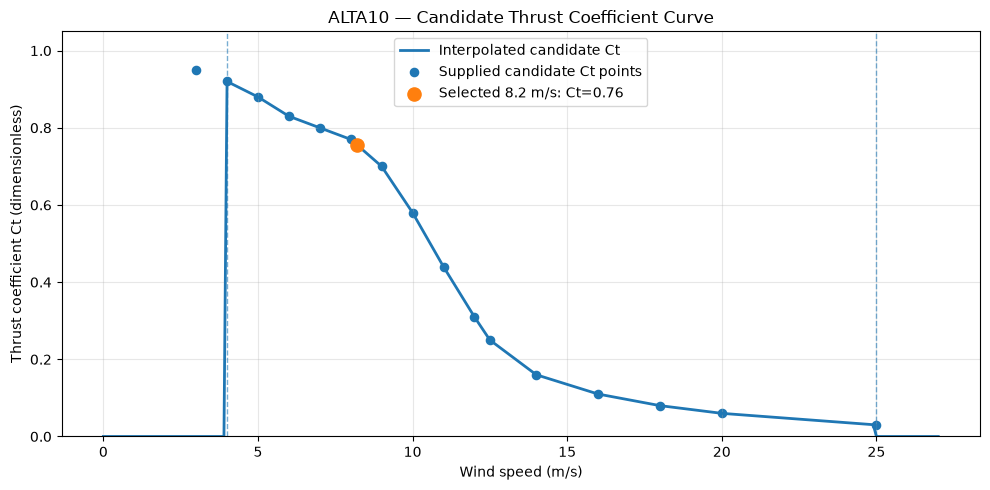

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
speeds = np.linspace(0, 27, 271)
ax.plot(speeds, get_ct(speeds), linewidth=2, label="Interpolated candidate Ct")
ax.scatter(ct_wind_speeds, ct_values, s=35, label="Supplied candidate Ct points")
ax.scatter([free_stream_speed], [thrust_coefficient], s=90, zorder=5,
           label=f"Selected {free_stream_speed:g} m/s: Ct={thrust_coefficient:.2f}")
ax.axvline(cut_in_speed, linestyle="--", linewidth=1, alpha=0.6)
ax.axvline(cut_out_speed, linestyle="--", linewidth=1, alpha=0.6)
ax.set(xlabel="Wind speed (m/s)", ylabel="Thrust coefficient Ct (dimensionless)",
       title="ALTA10 — Candidate Thrust Coefficient Curve")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Build terrain and turbine grid (UTM Zone 11N)

Calculations are performed in **meters**, EPSG:32611. Elevation comes from `elevation.tif`. This creates `farm`, `terrain`, `X`, `Y`, and `extent` for all subsequent cells.

In [7]:
farm = gpd.GeoDataFrame(
    coords.copy(),
    geometry=gpd.points_from_xy(coords["Longitude"], coords["Latitude"]),
    crs="EPSG:4326"
).to_crs("EPSG:32611")
farm["x"] = farm.geometry.x
farm["y"] = farm.geometry.y

xmin, ymin, xmax, ymax = farm.total_bounds
xmin -= padding; xmax += padding
ymin -= padding; ymax += padding
nx = int(np.ceil((xmax - xmin) / grid_resolution))
ny = int(np.ceil((ymax - ymin) / grid_resolution))
transform = from_origin(xmin, ymax, grid_resolution, grid_resolution)
terrain = np.full((ny, nx), np.nan, dtype=np.float32)

with rasterio.open(dem_path) as dem:
    reproject(
        source=rasterio.band(dem, 1),
        destination=terrain,
        src_transform=dem.transform,
        src_crs=dem.crs,
        src_nodata=dem.nodata,
        dst_transform=transform,
        dst_crs="EPSG:32611",
        dst_nodata=np.nan,
        resampling=Resampling.bilinear,
    )
    pts = farm.to_crs(dem.crs)
    samples = list(dem.sample([(p.x, p.y) for p in pts.geometry], masked=True))
    farm["elevation_m"] = [
        np.nan if np.ma.is_masked(v[0]) else float(v[0])
        for v in samples
    ]

if not np.isfinite(terrain).any():
    raise ValueError("DEM has no valid elevations in the turbine area: check coverage/CRS")
if farm["elevation_m"].isna().any():
    raise ValueError("Some turbines have missing DEM elevations: check coverage")

x = xmin + (np.arange(nx) + 0.5) * grid_resolution
y = ymax - (np.arange(ny) + 0.5) * grid_resolution
X, Y = np.meshgrid(x, y)
extent = [xmin, xmax, ymin, ymax]
print(f"Turbines: {len(farm)} | Grid: {nx} by {ny}")
print(f"Turbine elevation range: {farm.elevation_m.min():.1f}–{farm.elevation_m.max():.1f} m")

Turbines: 47 | Grid: 606 by 521
Turbine elevation range: 1048.8–1239.1 m


## 7. Wake-calculation functions

- **Jensen:** uniform top-hat deficit inside expanding wake boundary.
- **Gaussian-style:** Jensen-derived centerline deficit multiplied by a Gaussian spatial factor (not a published full Gaussian model).
- Both use a **horizontal wake centerline** with the DEM changing the vertical separation to a location's *assumed local hub height*.
- Quadratic deficit superposition; one Ct per simulation based on incoming wind speed; no terrain-following wind flow.

In [8]:
def calculate_wake_grid(model="jensen"):
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("model must be 'jensen' or 'gaussian_style'")

    theta = np.radians(wind_from_deg)
    down_x, down_y = -np.sin(theta), -np.cos(theta)
    ct = get_ct(free_stream_speed)
    deficit_sq = np.zeros(terrain.shape, dtype=np.float64)
    if ct <= 0:
        return deficit_sq

    for _, src in farm.iterrows():
        downstream = (X - src["x"]) * down_x + (Y - src["y"]) * down_y
        crosswind = -(X - src["x"]) * down_y + (Y - src["y"]) * down_x
        positive_x = np.maximum(downstream, 0.0)

        # Same hub height for all turbines: hub heights cancel in relative offset.
        vertical_offset = (terrain + hub_height) - (src["elevation_m"] + hub_height)
        center_deficit = (1 - np.sqrt(1 - ct)) / (
            1 + 2 * wake_decay * positive_x / rotor_diameter
        ) ** 2

        if model == "jensen":
            wake_radius = rotor_diameter / 2 + wake_decay * positive_x
            radial = np.hypot(crosswind, vertical_offset)
            deficit = np.where(
                (downstream > 0) & (radial <= wake_radius),
                center_deficit, 0.0
            )
        else:
            sigma = rotor_diameter / 2 + wake_decay * positive_x
            gaussian_factor = np.exp(-0.5 * (
                (crosswind / sigma) ** 2 + (vertical_offset / sigma) ** 2
            ))
            deficit = np.where(downstream > 0, center_deficit * gaussian_factor, 0.0)

        deficit[~np.isfinite(terrain)] = 0.0
        deficit_sq += deficit ** 2

    return np.minimum(np.sqrt(deficit_sq), 1.0)

jensen_deficit = calculate_wake_grid("jensen")
gaussian_deficit = calculate_wake_grid("gaussian_style")
print("Wake grids calculated. Shape:", jensen_deficit.shape)

Wake grids calculated. Shape: (521, 606)


## 8. Plot the two wake maps

Use identical wind conditions, terrain scale and wake colorbar for a fair visual comparison. The blue overlay is the **predicted percentage wind-speed deficit**, *not* a direct power-loss measurement.

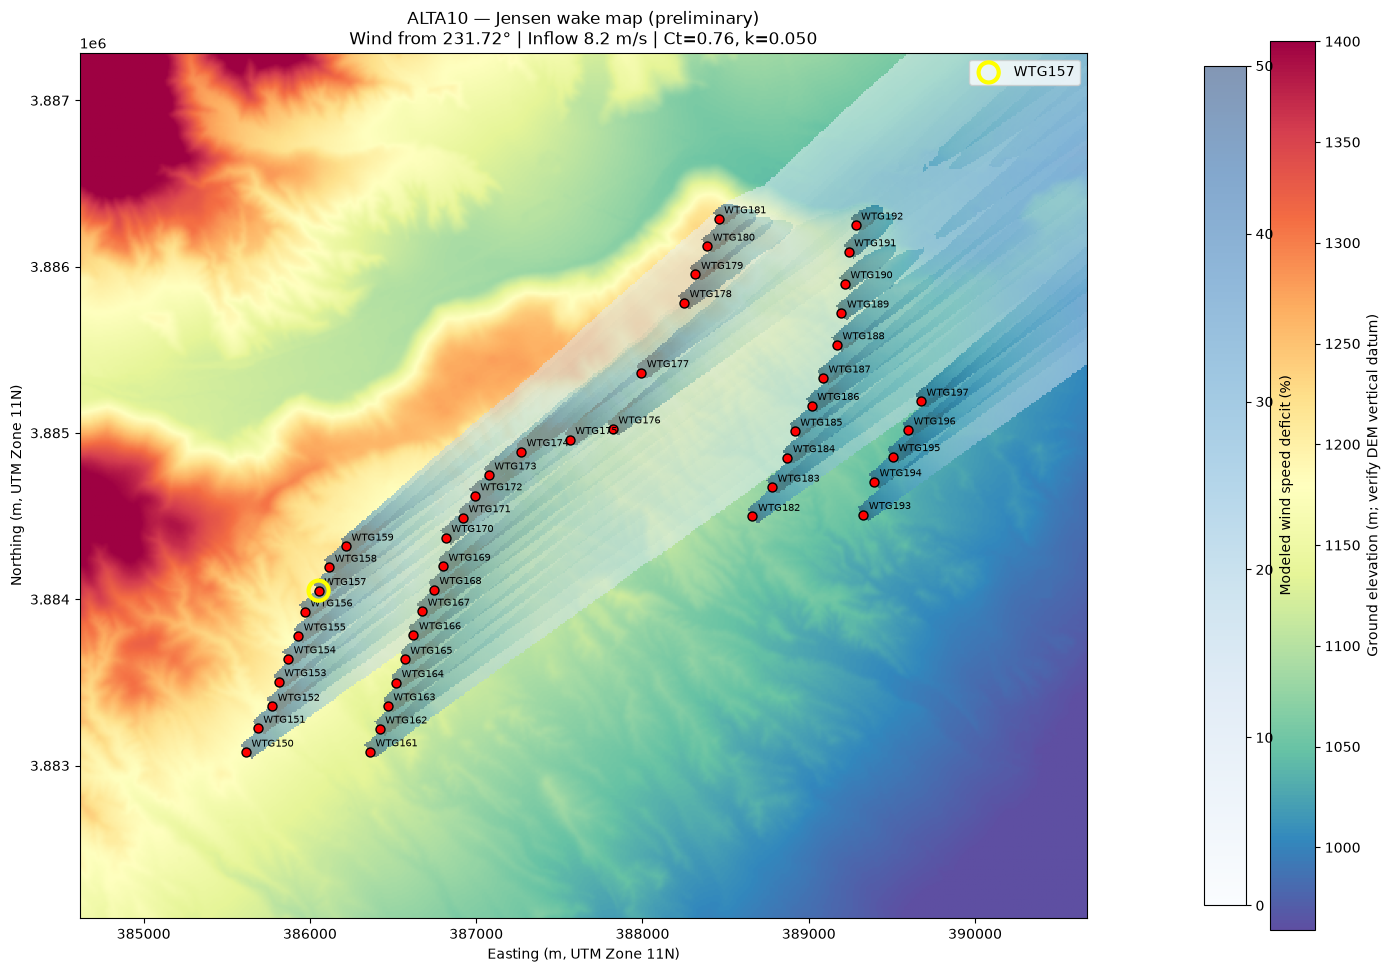

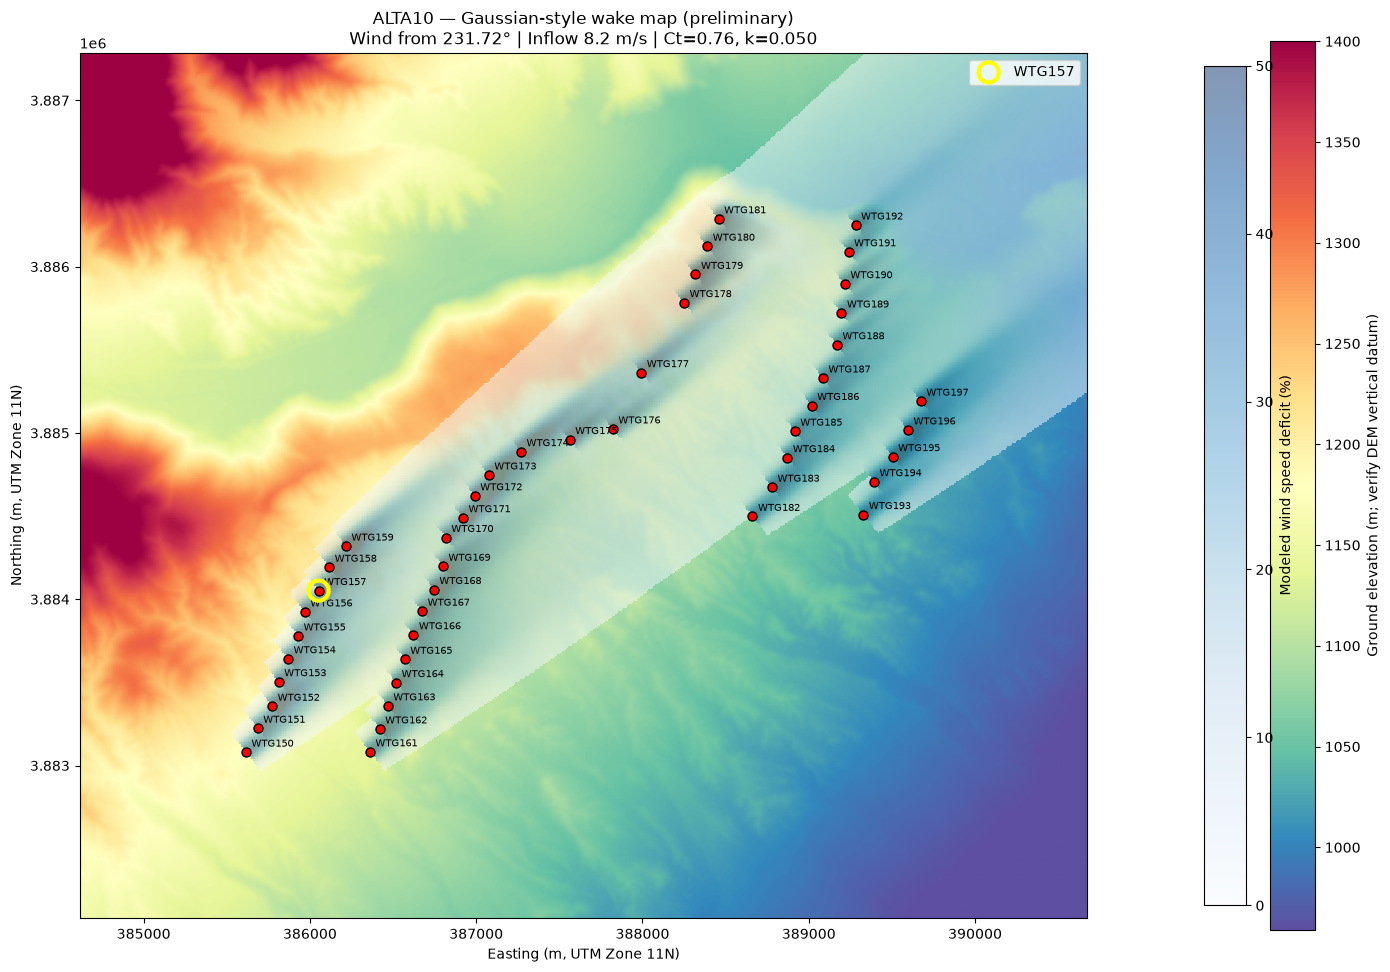

In [9]:
def plot_wake_map(deficit, model_title):
    fig, ax = plt.subplots(figsize=(14, 10))

    elev = ax.imshow(
        terrain, extent=extent, origin="upper", cmap="Spectral_r",
        vmin=np.nanpercentile(terrain, 2), vmax=np.nanpercentile(terrain, 98),
        zorder=1,
    )
    wake = np.ma.masked_where(
        (deficit < 0.01) | ~np.isfinite(terrain), deficit * 100.0
    )
    overlay = ax.imshow(
        wake, extent=extent, origin="upper", cmap="Blues",
        vmin=0, vmax=wake_color_max, alpha=0.5,
        interpolation="nearest", zorder=2,
    )
    ax.scatter(farm.x, farm.y, c="red", s=42, edgecolors="black", zorder=5)
    for _, row in farm.iterrows():
        ax.annotate(row["turbine"], (row["x"], row["y"]),
                    xytext=(4, 4), textcoords="offset points", fontsize=7, zorder=6)

    target = farm.loc[farm["turbine"] == "WTG157"]
    if not target.empty:
        ax.scatter(target.x, target.y, s=210, facecolors="none", edgecolors="yellow",
                   linewidths=3, zorder=7, label="WTG157")
        ax.legend(loc="upper right")

    bar1 = fig.colorbar(elev, ax=ax, fraction=0.036, pad=0.02)
    bar1.set_label("Ground elevation (m; verify DEM vertical datum)")
    bar2 = fig.colorbar(overlay, ax=ax, fraction=0.036, pad=0.10)
    bar2.set_label("Modeled wind speed deficit (%)")

    ax.set_title(
        f"ALTA10 — {model_title} (preliminary)\n"
        f"Wind from {wind_from_deg:.2f}° | Inflow {free_stream_speed:.1f} m/s | "
        f"Ct={get_ct(free_stream_speed):.2f}, k={wake_decay:.3f}"
    )
    ax.set_xlabel("Easting (m, UTM Zone 11N)")
    ax.set_ylabel("Northing (m, UTM Zone 11N)")
    ax.set_aspect("equal")
    fig.tight_layout()
    plt.show()

plot_wake_map(jensen_deficit, "Jensen wake map")
plot_wake_map(gaussian_deficit, "Gaussian-style wake map")

## 9. Predicted wake deficit at each turbine hub center

These are **single-condition, hub-center** predictions (no rotor averaging). No self-wakes. A zero may reflect a missed hub center even if the rotor partly overlaps a wake. Useful for identifying candidates for more detailed analysis, **not** sensor-bias estimates.

In [10]:
def turbine_wake_predictions(model="jensen"):
    if model not in {"jensen", "gaussian_style"}:
        raise ValueError("Choose 'jensen' or 'gaussian_style'")

    theta = np.radians(wind_from_deg)
    dx, dy = -np.sin(theta), -np.cos(theta)
    ct = get_ct(free_stream_speed)
    rows = []

    for _, target in farm.iterrows():
        sq = 0.0
        overlapping = 0
        for _, source in farm.iterrows():
            if source["turbine"] == target["turbine"]:
                continue
            delta_x, delta_y = target["x"] - source["x"], target["y"] - source["y"]
            downstream = delta_x * dx + delta_y * dy
            if downstream <= 0 or ct <= 0:
                continue
            crosswind = -delta_x * dy + delta_y * dx
            vert = (target["elevation_m"] + hub_height) - (source["elevation_m"] + hub_height)
            radius = rotor_diameter / 2 + wake_decay * downstream
            center = (1 - np.sqrt(1 - ct)) / (1 + 2 * wake_decay * downstream / rotor_diameter) ** 2
            if model == "jensen":
                in_wake = np.hypot(crosswind, vert) <= radius
                deficit = center if in_wake else 0.0
                overlapping += int(in_wake)
            else:
                sigma = radius
                deficit = center * np.exp(-0.5 * ((crosswind / sigma) ** 2 + (vert / sigma) ** 2))
                overlapping += int(deficit >= 0.01)  # count material contributions, not strict boundary
            sq += deficit ** 2
        combined = min(np.sqrt(sq), 1.0)
        rows.append({
            "turbine": target["turbine"],
            "model": model,
            "predicted_deficit_pct": combined * 100,
            "predicted_wind_speed_ms": free_stream_speed * (1 - combined),
            "contributing_wakes": overlapping,
        })
    return pd.DataFrame(rows)

wake_predictions = pd.concat([
    turbine_wake_predictions("jensen"),
    turbine_wake_predictions("gaussian_style")
], ignore_index=True)
display(wake_predictions.sort_values(["model", "predicted_deficit_pct"], ascending=[True, False]).head(15))
print("WTG157:")
display(wake_predictions[wake_predictions["turbine"] == "WTG157"])

,turbine,model,predicted_deficit_pct,predicted_wind_speed_ms,contributing_wakes
70,WTG174,gaussian_style,44.199377,4.575651,12
67,WTG171,gaussian_style,36.906789,5.173643,9
69,WTG173,gaussian_style,33.471731,5.455318,10
56,WTG159,gaussian_style,32.188638,5.560532,3
68,WTG172,gaussian_style,29.902517,5.747994,9
64,WTG168,gaussian_style,28.462623,5.866065,7
73,WTG177,gaussian_style,28.141476,5.892399,18
49,WTG152,gaussian_style,27.355718,5.956831,2
54,WTG157,gaussian_style,27.297908,5.961572,2
71,WTG175,gaussian_style,27.041824,5.982570,15


WTG157:


,turbine,model,predicted_deficit_pct,predicted_wind_speed_ms,contributing_wakes
7,WTG157,jensen,38.917122,5.008796,1
54,WTG157,gaussian_style,27.297908,5.961572,2


## 10. Optional comparison: wake deficit by turbine

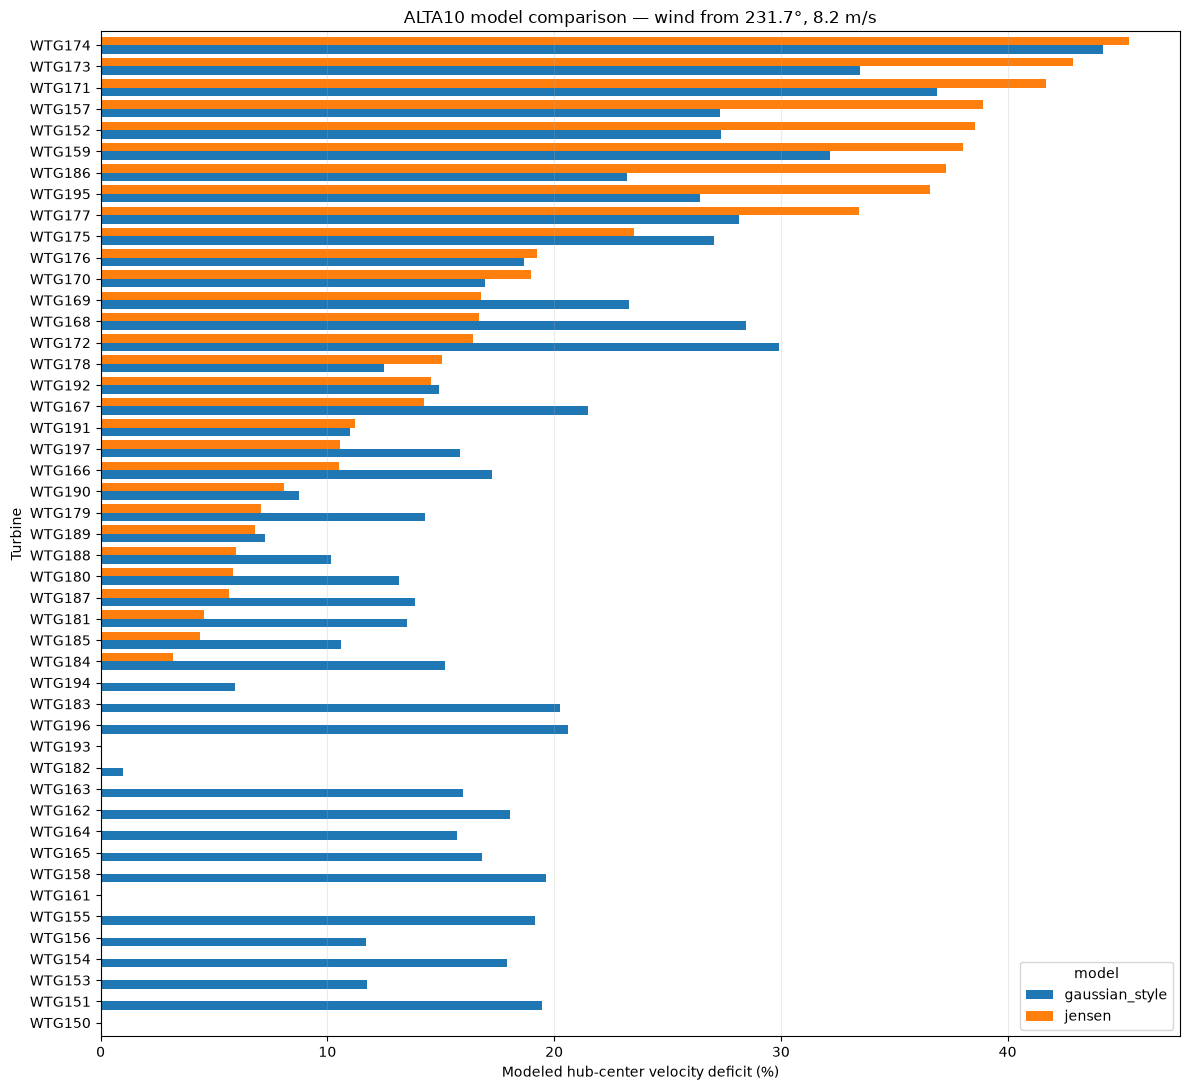

In [11]:
pivot = wake_predictions.pivot(index="turbine", columns="model", values="predicted_deficit_pct")
pivot = pivot.sort_values("jensen", ascending=True)
ax = pivot.plot.barh(figsize=(12, 11), width=0.8)
ax.set_xlabel("Modeled hub-center velocity deficit (%)")
ax.set_ylabel("Turbine")
ax.set_title(f"ALTA10 model comparison — wind from {wind_from_deg:.1f}°, {free_stream_speed:.1f} m/s")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

The supplied candidate curve above includes a thrust coefficient of 0.95 at 3 m/s.

So we're deliberately excluding that point because the manufacturer's specification lists a 4 m/s cut-in speed.

That's fine for a preliminary operating-state approximation, but we shouldn't assume a non-generating turbine always has zero aerodynamic thrust. An idling rotor can still exert aerodynamic forces.

Leave assumption for now.

## Next phase: anemometer-bias investigation

1. **Verify the Ct curve** with the sponsor (especially the 3 m/s vs 4 m/s cut-in discrepancy).
2. Keep `k = 0.05` as a placeholder and test sensitivity (`0.03`, `0.05`, `0.075`).
3. Obtain met-mast **10-minute wind-speed standard deviations** / turbulence intensity, an independent undisturbed inflow reference, availability/curtailment flags, and the OEM power curve.
4. Implement the published **Bastankhah–Porté-Agel Gaussian model** separately; *do not present the Gaussian-style map above as that published model*.
5. Compare wind predictions against **matched SCADA 10-minute intervals**, ideally first in clean/unwaked and steady operating periods. Nacelle anemometer readings are **not identical** to rotor-effective wind speeds; comparisons require measurement/flow corrections.

**Model caveat:** Terrain is used to adjust vertical geometry only. These maps do **not** simulate air flowing around or over the hills.

LIDAR SECTION_______________________


In [12]:
# ==========================================
# LIDAR DATA EXPLORATION
# ==========================================

from pathlib import Path

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

data_path = project_path / "data"

# LiDAR turbine folders
lidar_ids = [
    "WTG_T159",
    "WTG_T170",
    "WTG_T171",
    "WTG_T173",
    "WTG_T180",
    "WTG_T184"
]

lidar_folders = {}

# Locate folders inside project data directory
for folder in data_path.rglob("*"):

    if folder.is_dir() and folder.name in lidar_ids:
        lidar_folders[folder.name] = folder

# Display available files
for turbine, folder in sorted(lidar_folders.items()):

    files = sorted(
        f for f in folder.rglob("*") if f.is_file()
    )

    print(f"\n{'='*55}")
    print(f"TURBINE: {turbine}")
    print(f"Folder: {folder}")
    print(f"Number of files: {len(files)}")

    print("\nFile formats:")
    extensions = sorted(set(f.suffix.lower() for f in files))
    print(extensions)

    print("\nFirst 5 files:")
    for file in files[:5]:
        print(file.name)

print(f"\nLocated {len(lidar_folders)} of 6 LiDAR folders.")

if not lidar_folders:
    print("No folders found. Check where the LiDAR data is saved.")


TURBINE: WTG_T159
Folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\lidar_data\WTG_T159
Number of files: 134

File formats:
['.csv']

First 5 files:
2026-05-01.csv
2026-05-02.csv
2026-05-03.csv
2026-05-04.csv
2026-05-05.csv

TURBINE: WTG_T170
Folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\lidar_data\WTG_T170
Number of files: 133

File formats:
['.csv']

First 5 files:
2026-05-01.csv
2026-05-02.csv
2026-05-03.csv
2026-05-04.csv
2026-05-05.csv

TURBINE: WTG_T171
Folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\lidar_data\WTG_T171
Number of files: 134

File formats:
['.csv']

First 5 files:
2026-05-01.csv
2026-05-02.csv
2026-05-03.csv
2026-05-04.csv
2026-05-05.csv

TURBINE: WTG_T173
Folder: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\lidar_data\WTG_T173
Number of files: 134

File formats:
['.csv']

First 5 files:
2026-05-01.csv
2026-05-02.csv
2026-05-03.csv
2026-05-04.csv
202

In [13]:
# ==========================================
# INSPECT LIDAR DATA - WTG159
# ==========================================

import pandas as pd

# Select turbine folder
lidar_folder = lidar_folders["WTG_T159"]

# Select first CSV file
lidar_file = sorted(lidar_folder.glob("*.csv"))[0]

print("Reading:", lidar_file.name)

# Preview original file structure
print("\nFIRST 8 LINES OF RAW FILE:")

with open(lidar_file, "r", encoding="utf-8-sig") as f:
    for i in range(8):
        line = f.readline()
        if not line:
            break
        print(line.rstrip())

# Load file into DataFrame
lidar_sample = pd.read_csv(lidar_file)

# Display dataset information
print("\nDATASET SHAPE:")
print(lidar_sample.shape)

print("\nVARIABLES AND DATA TYPES:")
for col in lidar_sample.columns:
    print(f"{col}: {lidar_sample[col].dtype}")

print("\nFIRST 5 ROWS:")
display(lidar_sample.head())

Reading: 2026-05-01.csv

FIRST 8 LINES OF RAW FILE:
timestamp,Vlos1,Vlos2,lidar_wsp,lidar_phi,sensor1_wsp,sensor1_phi,wtg1_wsp,wtg1_phi,mode
2026-05-01 00:00:00,7.25,9.17,9.64,11.2,12.06,16.6,12.06,-164.6,1
2026-05-01 00:00:01,7.07,8.91,9.42,11.6,11.96,13.4,11.96,-167.6,1
2026-05-01 00:00:02,7.35,8.98,9.56,9.4,11.7,10.8,11.7,-170.2,1
2026-05-01 00:00:03,7.81,8.98,9.8,6.6,11.36,8.8,11.36,-172.2,1
2026-05-01 00:00:04,8.07,8.77,9.78,4.4,11.68,8.4,11.68,-172.6,1
2026-05-01 00:00:05,8.17,8.46,9.62,2.2,11.42,7.0,11.42,-174.0,1
2026-05-01 00:00:06,7.86,8.35,9.34,3.4,11.1,4.0,11.1,-177.0,1

DATASET SHAPE:
(86400, 10)

VARIABLES AND DATA TYPES:
timestamp: str
Vlos1: float64
Vlos2: float64
lidar_wsp: float64
lidar_phi: float64
sensor1_wsp: float64
sensor1_phi: float64
wtg1_wsp: float64
wtg1_phi: float64
mode: int64

FIRST 5 ROWS:


,timestamp,Vlos1,Vlos2,lidar_wsp,lidar_phi,sensor1_wsp,sensor1_phi,wtg1_wsp,wtg1_phi,mode
0,2026-05-01 00:00:00,7.25,9.17,9.64,11.2,12.06,16.6,12.06,-164.6,1
1,2026-05-01 00:00:01,7.07,8.91,9.42,11.6,11.96,13.4,11.96,-167.6,1
2,2026-05-01 00:00:02,7.35,8.98,9.56,9.4,11.70,10.8,11.70,-170.2,1
3,2026-05-01 00:00:03,7.81,8.98,9.80,6.6,11.36,8.8,11.36,-172.2,1
4,2026-05-01 00:00:04,8.07,8.77,9.78,4.4,11.68,8.4,11.68,-172.6,1


In [14]:
# ==========================================
# WTG159 - 1 SECOND TO 10 MINUTE LIDAR DATA
# ==========================================

import pandas as pd
import numpy as np

# Copy our previously loaded LiDAR sample
lidar = lidar_sample.copy()

# Convert timestamps
lidar["timestamp"] = pd.to_datetime(
    lidar["timestamp"],
    errors="coerce"
)

lidar = lidar.dropna(subset=["timestamp"])
lidar = lidar.sort_values("timestamp")

# Check instrument mode distribution
print("Measurement modes:")
print(lidar["mode"].value_counts(dropna=False))

# Check whether sensor1 and wtg1 are duplicates
valid_pair = lidar[["sensor1_wsp", "wtg1_wsp"]].dropna()

if len(valid_pair):
    agreement = np.isclose(
        valid_pair["sensor1_wsp"],
        valid_pair["wtg1_wsp"],
        atol=1e-6
    ).mean() * 100

    print(f"\nSensor1 / WTG1 agreement: {agreement:.2f}%")

# Remove invalid LiDAR wind speeds
lidar.loc[
    lidar["lidar_wsp"] < 0,
    "lidar_wsp"
] = np.nan

# Set timestamps as index
lidar = lidar.set_index("timestamp")

# Aggregate 1-second data into 10-minute intervals
lidar_10min = lidar.resample("10min").agg(
    lidar_speed_mean=("lidar_wsp", "mean"),
    lidar_speed_std=("lidar_wsp", "std"),
    lidar_count=("lidar_wsp", "count"),
    sensor1_speed_mean=("sensor1_wsp", "mean"),
    wtg1_speed_mean=("wtg1_wsp", "mean")
)

# Require at least 90% of expected 1-second samples
lidar_10min = lidar_10min[
    (lidar_10min["lidar_count"] >= 540) &
    (lidar_10min["lidar_speed_mean"] >= 3)
].copy()

# Calculate estimated LiDAR turbulence intensity
lidar_10min["lidar_TI"] = (
    lidar_10min["lidar_speed_std"] /
    lidar_10min["lidar_speed_mean"]
)

# Add turbine identifier
lidar_10min["turbine"] = "WTG159"

# Return timestamp to column
lidar_10min = lidar_10min.reset_index()

print("\n10-MINUTE LIDAR SUMMARY:")
display(lidar_10min.head(10))

print(
    "\nMedian estimated LiDAR TI:",
    f"{lidar_10min['lidar_TI'].median():.2%}"
)

Measurement modes:
mode
1    44153
0    42247
Name: count, dtype: int64

Sensor1 / WTG1 agreement: 99.92%

10-MINUTE LIDAR SUMMARY:


,timestamp,lidar_speed_mean,lidar_speed_std,lidar_count,sensor1_speed_mean,wtg1_speed_mean,lidar_TI,turbine
0,2026-05-01 00:00:00,10.733200,0.819579,600,12.902217,12.902217,0.076359,WTG159
1,2026-05-01 00:10:00,10.587100,0.846627,600,12.826983,12.826983,0.079968,WTG159
2,2026-05-01 00:20:00,11.183383,0.916572,600,13.277617,13.277617,0.081958,WTG159
3,2026-05-01 00:30:00,10.978333,1.118183,600,13.217033,13.209695,0.101854,WTG159
4,2026-05-01 00:40:00,11.676067,1.318999,600,13.924467,NaN,0.112966,WTG159
5,2026-05-01 00:50:00,11.435683,0.884665,600,13.842783,NaN,0.077360,WTG159
6,2026-05-01 01:00:00,11.881250,1.040278,600,14.254050,NaN,0.087556,WTG159
7,2026-05-01 01:10:00,11.885483,1.577866,600,14.276017,NaN,0.132756,WTG159
8,2026-05-01 01:20:00,11.548083,1.295838,600,13.725867,NaN,0.112212,WTG159
9,2026-05-01 01:30:00,11.646483,1.181432,600,13.702033,NaN,0.101441,WTG159



Median estimated LiDAR TI: 9.96%


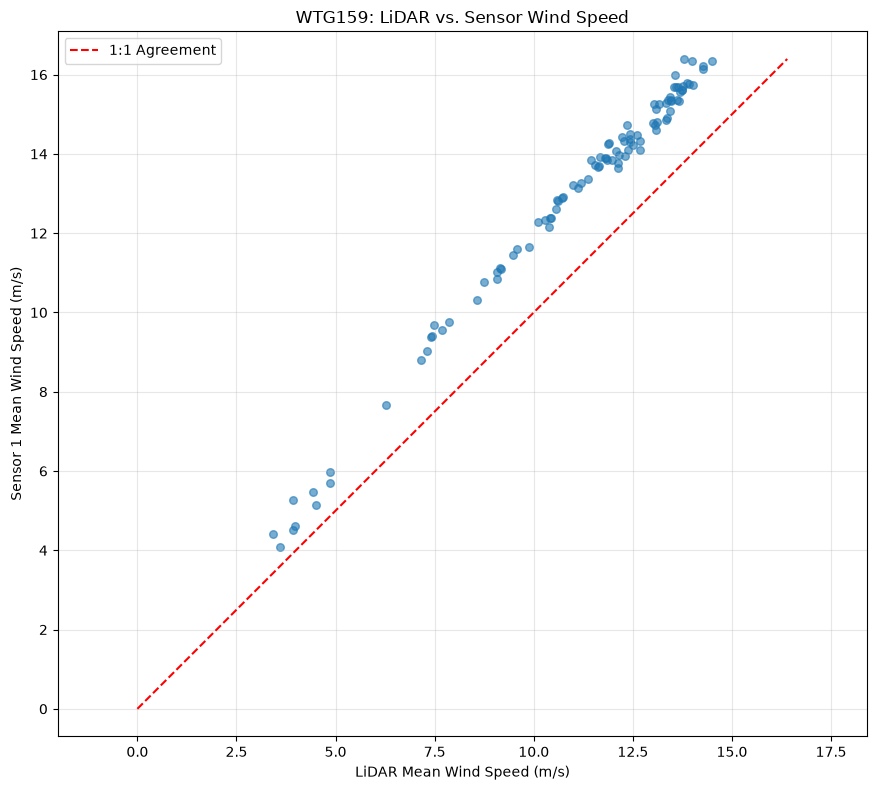

In [15]:
# ==========================================
# LIDAR VS SENSOR WIND SPEED
# ==========================================

comparison = lidar_10min.dropna(
    subset=["lidar_speed_mean", "sensor1_speed_mean"]
)

plt.figure(figsize=(9, 8))

plt.scatter(
    comparison["lidar_speed_mean"],
    comparison["sensor1_speed_mean"],
    alpha=0.6,
    s=30
)

# 1:1 reference line
max_speed = max(
    comparison["lidar_speed_mean"].max(),
    comparison["sensor1_speed_mean"].max()
)

plt.plot(
    [0, max_speed],
    [0, max_speed],
    "r--",
    label="1:1 Agreement"
)

plt.xlabel("LiDAR Mean Wind Speed (m/s)")
plt.ylabel("Sensor 1 Mean Wind Speed (m/s)")
plt.title("WTG159: LiDAR vs. Sensor Wind Speed")
plt.legend()
plt.grid(alpha=0.3)
plt.axis("equal")
plt.tight_layout()
plt.show()

WIND SPEED DIFFERENCE BY MODE:


,mode,observations,lidar_mean,sensor_mean,mean_difference,median_difference,difference_std
0,0,36396,9.770828,11.458244,1.687416,1.72,1.325938
1,1,36274,9.618528,11.305227,1.686699,1.72,1.310097


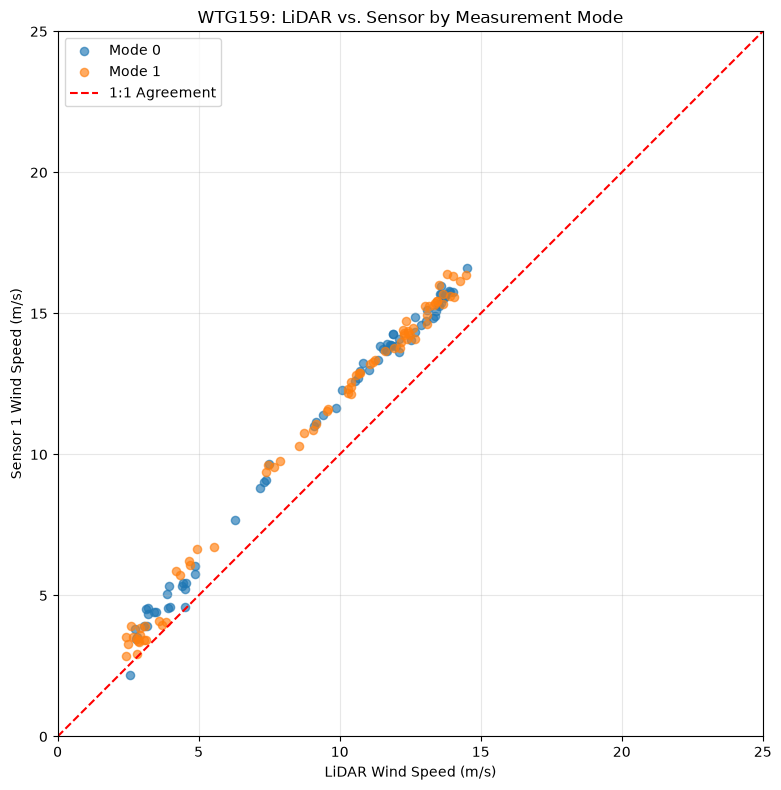

In [16]:
# ==========================================
# WTG159 - LIDAR VS SENSOR BY MODE
# ==========================================

# Start with original 1-second data
mode_data = lidar_sample.copy()

mode_data["timestamp"] = pd.to_datetime(
    mode_data["timestamp"]
)

# Keep simultaneous, valid wind-speed readings
mode_data = mode_data.dropna(
    subset=["lidar_wsp", "sensor1_wsp", "mode"]
)

mode_data = mode_data[
    mode_data["lidar_wsp"].between(0, 35) &
    mode_data["sensor1_wsp"].between(0, 35)
].copy()

# Sensor minus LiDAR difference
mode_data["wind_difference"] = (
    mode_data["sensor1_wsp"] -
    mode_data["lidar_wsp"]
)

# Summarize by measurement mode
mode_summary = (
    mode_data.groupby("mode")
    .agg(
        observations=("wind_difference", "count"),
        lidar_mean=("lidar_wsp", "mean"),
        sensor_mean=("sensor1_wsp", "mean"),
        mean_difference=("wind_difference", "mean"),
        median_difference=("wind_difference", "median"),
        difference_std=("wind_difference", "std")
    )
    .reset_index()
)

print("WIND SPEED DIFFERENCE BY MODE:")
display(mode_summary)

# Calculate 10-minute averages separately for each mode
mode_10min = (
    mode_data.groupby([
        pd.Grouper(key="timestamp", freq="10min"),
        "mode"
    ])
    .agg(
        lidar_mean=("lidar_wsp", "mean"),
        sensor_mean=("sensor1_wsp", "mean"),
        count=("lidar_wsp", "count")
    )
    .reset_index()
)

# Require at least 120 paired seconds per mode/bin
mode_10min = mode_10min[
    mode_10min["count"] >= 120
]

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

for mode, group in mode_10min.groupby("mode"):
    ax.scatter(
        group["lidar_mean"],
        group["sensor_mean"],
        alpha=0.65,
        s=35,
        label=f"Mode {mode}"
    )

ax.plot(
    [0, 25],
    [0, 25],
    "r--",
    label="1:1 Agreement"
)

ax.set_xlim(0, 25)
ax.set_ylim(0, 25)
ax.set_aspect("equal")

ax.set_xlabel("LiDAR Wind Speed (m/s)")
ax.set_ylabel("Sensor 1 Wind Speed (m/s)")
ax.set_title("WTG159: LiDAR vs. Sensor by Measurement Mode")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Linear Regression on Lidar and Sensor 1:
goal right now is to determine whether Sensor 1's higher wind-speed readings are explained by a relatively constant offset or a difference that increases with wind speed.

WTG159 - LIDAR VS SENSOR REGRESSION
10-minute observations: 100
Slope: 1.0813
Intercept: 0.9587 m/s
R-squared: 0.9902
Correlation: 0.9951

Mean difference: 1.8550 m/s
Median difference: 1.9352 m/s
MAE: 1.8550 m/s
RMSE: 1.8950 m/s
Relative mean difference: 16.82%


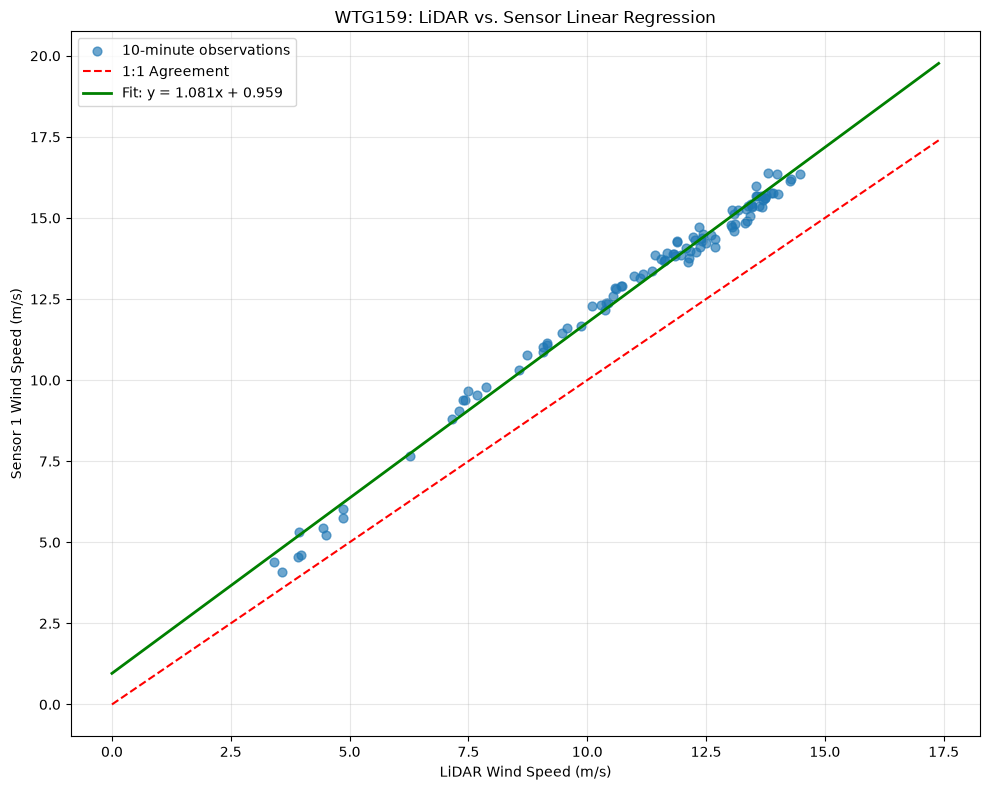

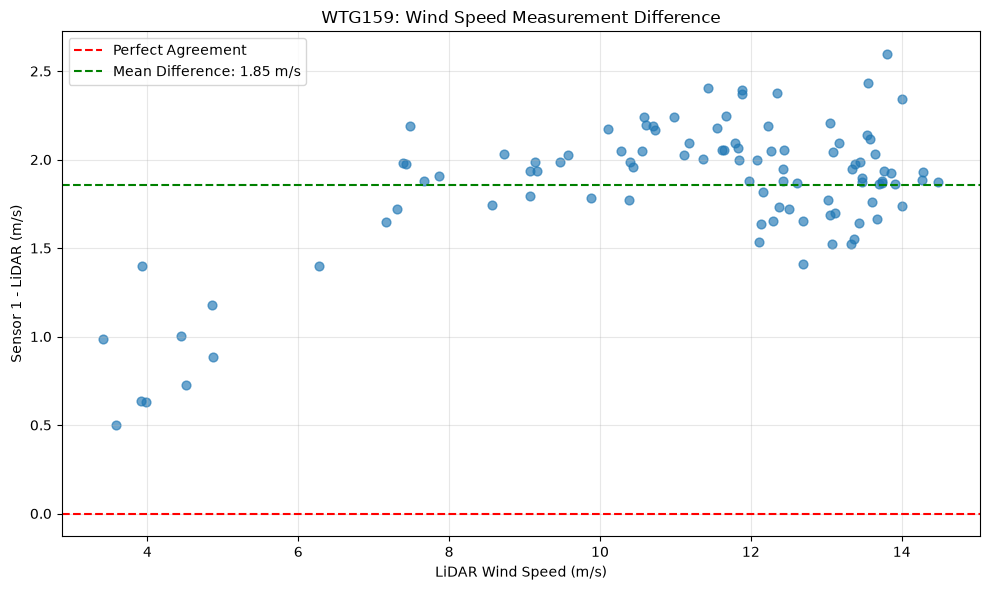

In [17]:
# ==========================================
# WTG159 - LIDAR VS SENSOR REGRESSION
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Start with original 1-second data
reg_data = lidar_sample.copy()

reg_data["timestamp"] = pd.to_datetime(
    reg_data["timestamp"]
)

# Keep valid, simultaneous measurements
reg_data = reg_data.dropna(
    subset=["timestamp", "lidar_wsp", "sensor1_wsp"]
)

reg_data = reg_data[
    reg_data["lidar_wsp"].between(0, 35) &
    reg_data["sensor1_wsp"].between(0, 35)
].copy()

# Aggregate paired observations into 10-minute intervals
reg_data["interval"] = reg_data["timestamp"].dt.floor("10min")

reg_10min = (
    reg_data.groupby("interval")
    .agg(
        lidar_mean=("lidar_wsp", "mean"),
        sensor_mean=("sensor1_wsp", "mean"),
        count=("lidar_wsp", "count")
    )
    .reset_index()
)

# Require at least 90% coverage
reg_10min = reg_10min[
    (reg_10min["count"] >= 540) &
    (reg_10min["lidar_mean"] >= 3)
].copy()

# ==========================================
# LINEAR REGRESSION
# ==========================================

x = reg_10min["lidar_mean"].to_numpy()
y = reg_10min["sensor_mean"].to_numpy()

if len(x) < 3 or np.std(x) == 0:
    raise ValueError("Not enough variation or observations for regression.")

# Fit y = slope*x + intercept
slope, intercept = np.polyfit(x, y, 1)

predicted = slope * x + intercept

# Regression statistics
r_squared = 1 - (
    np.sum((y - predicted)**2) /
    np.sum((y - y.mean())**2)
)

correlation = np.corrcoef(x, y)[0, 1]

# Sensor - LiDAR differences
difference = y - x

mean_bias = np.mean(difference)
median_bias = np.median(difference)
mae = np.mean(np.abs(difference))
rmse = np.sqrt(np.mean(difference**2))

percent_bias = 100 * mean_bias / np.mean(x)

# ==========================================
# DISPLAY RESULTS
# ==========================================

print("WTG159 - LIDAR VS SENSOR REGRESSION")
print("=" * 45)

print(f"10-minute observations: {len(x)}")
print(f"Slope: {slope:.4f}")
print(f"Intercept: {intercept:.4f} m/s")
print(f"R-squared: {r_squared:.4f}")
print(f"Correlation: {correlation:.4f}")

print(f"\nMean difference: {mean_bias:.4f} m/s")
print(f"Median difference: {median_bias:.4f} m/s")
print(f"MAE: {mae:.4f} m/s")
print(f"RMSE: {rmse:.4f} m/s")
print(f"Relative mean difference: {percent_bias:.2f}%")

# ==========================================
# PLOT 1 - REGRESSION COMPARISON
# ==========================================

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    x, y,
    alpha=0.65,
    s=40,
    label="10-minute observations"
)

line_x = np.linspace(0, max(x.max(), y.max()) + 1, 100)

# Perfect agreement
ax.plot(
    line_x, line_x,
    "r--",
    label="1:1 Agreement"
)

# Fitted regression
ax.plot(
    line_x,
    slope * line_x + intercept,
    color="green",
    linewidth=2,
    label=f"Fit: y = {slope:.3f}x + {intercept:.3f}"
)

ax.set_xlabel("LiDAR Wind Speed (m/s)")
ax.set_ylabel("Sensor 1 Wind Speed (m/s)")
ax.set_title("WTG159: LiDAR vs. Sensor Linear Regression")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# PLOT 2 - SENSOR MINUS LIDAR DIFFERENCE
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    x,
    difference,
    alpha=0.65,
    s=40
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    label="Perfect Agreement"
)

ax.axhline(
    mean_bias,
    color="green",
    linestyle="--",
    label=f"Mean Difference: {mean_bias:.2f} m/s"
)

ax.set_xlabel("LiDAR Wind Speed (m/s)")
ax.set_ylabel("Sensor 1 - LiDAR (m/s)")
ax.set_title("WTG159: Wind Speed Measurement Difference")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

WTG159 has a systematic LiDAR-versus-Sensor 1 discrepancy in the May 1 sample. We haven't yet established which measurement is more accurate or whether this represents an anemometer calibration issue.

##Lidar and SCADA Eval

In [18]:
# ==========================================
# WTG159 - MERGE LIDAR AND SCADA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PREPARE SCADA
# ==========================================

scada159 = scada[
    scada["turbine"].astype(str).str.strip() == "WTG159"
][
    ["utc", "turbine", "wind_speed",
     "real_power_ac", "air_density"]
].copy()

# Assume SCADA timestamps are UTC
scada159["utc"] = pd.to_datetime(
    scada159["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

scada159 = scada159.rename(
    columns={
        "utc": "timestamp",
        "wind_speed": "scada_wind_speed",
        "real_power_ac": "scada_power_kw"
    }
)

# ==========================================
# 2. PREPARE LIDAR
# ==========================================

# Use the 10-minute paired measurements from Option A
lidar159 = reg_10min.copy()

# Assumes LiDAR timestamps also represent UTC
lidar159["timestamp"] = pd.to_datetime(
    lidar159["interval"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

lidar159 = lidar159[
    ["timestamp", "lidar_mean", "sensor_mean", "count"]
].copy()

# ==========================================
# 3. CHECK FOR DUPLICATE TIMESTAMPS
# ==========================================

print("Duplicate LiDAR intervals:",
      lidar159["timestamp"].duplicated().sum())

print("Duplicate SCADA intervals:",
      scada159["timestamp"].duplicated().sum())

# ==========================================
# 4. MERGE ON TIMESTAMP
# ==========================================

wtg159_matched = pd.merge(
    lidar159,
    scada159,
    on="timestamp",
    how="inner",
    validate="one_to_one"
)

wtg159_matched = wtg159_matched.sort_values(
    "timestamp"
)

print("\nMATCHING RESULTS")
print("=" * 45)

print("LiDAR intervals:", len(lidar159))
print("Matched LiDAR-SCADA intervals:", len(wtg159_matched))

print("\nMATCHED DATA:")
display(wtg159_matched.head(10))

Duplicate LiDAR intervals: 0
Duplicate SCADA intervals: 0

MATCHING RESULTS
LiDAR intervals: 100
Matched LiDAR-SCADA intervals: 100

MATCHED DATA:


,timestamp,lidar_mean,sensor_mean,count,turbine,scada_wind_speed,scada_power_kw,air_density
0,2026-05-01 00:00:00,10.733200,12.902217,600,WTG159,11.900786,2407.250788,1.040845
1,2026-05-01 00:10:00,10.587100,12.826983,600,WTG159,11.851596,2370.778028,1.041188
2,2026-05-01 00:20:00,11.183383,13.277617,600,WTG159,12.308375,2530.708860,1.041615
3,2026-05-01 00:30:00,10.978333,13.217033,600,WTG159,12.245363,2481.838568,0.748542
4,2026-05-01 00:40:00,11.676067,13.924467,600,WTG159,13.069557,2630.292827,1.042130
5,2026-05-01 00:50:00,11.435683,13.842783,600,WTG159,12.969410,2633.763861,1.042016
6,2026-05-01 01:00:00,11.881250,14.254050,600,WTG159,13.484244,2723.095206,1.041688
7,2026-05-01 01:10:00,11.885483,14.276017,600,WTG159,13.459430,2620.853984,1.042072
8,2026-05-01 01:20:00,11.548083,13.725867,600,WTG159,12.900846,2589.985562,1.042147
9,2026-05-01 01:30:00,11.646483,13.702033,600,WTG159,12.789404,2638.767274,1.042796


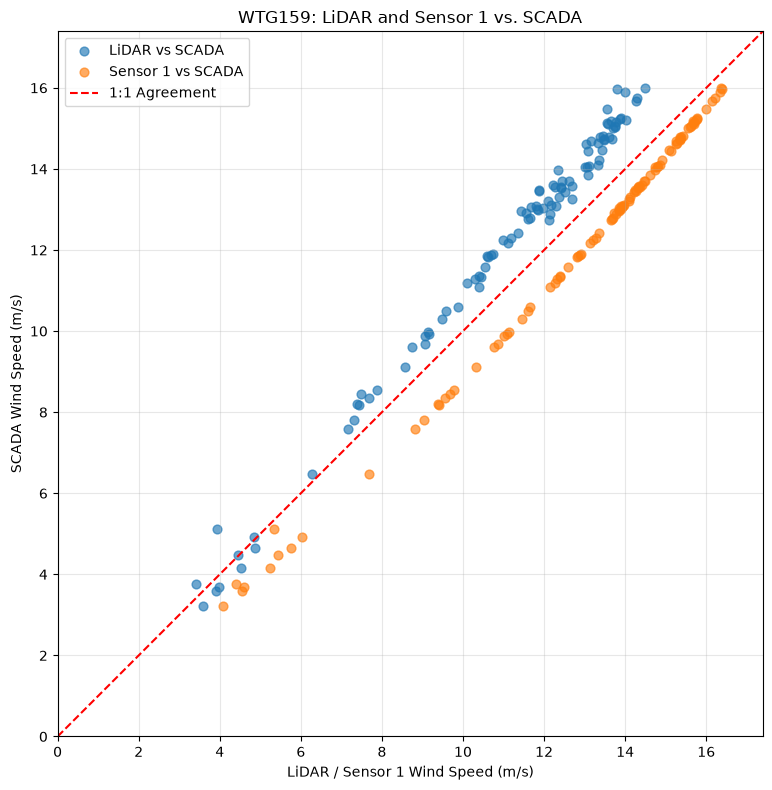

In [19]:
# ==========================================
# WTG159 - SCADA VS LIDAR AND SENSOR 1
# ==========================================

comparison = wtg159_matched.dropna(
    subset=[
        "lidar_mean",
        "sensor_mean",
        "scada_wind_speed"
    ]
).copy()

if comparison.empty:
    raise ValueError(
        "No complete matching observations. Check timestamps."
    )

fig, ax = plt.subplots(figsize=(10, 8))

# LiDAR vs SCADA
ax.scatter(
    comparison["lidar_mean"],
    comparison["scada_wind_speed"],
    alpha=0.65,
    s=40,
    label="LiDAR vs SCADA"
)

# Sensor 1 vs SCADA
ax.scatter(
    comparison["sensor_mean"],
    comparison["scada_wind_speed"],
    alpha=0.65,
    s=40,
    label="Sensor 1 vs SCADA"
)

# Perfect agreement line
limit = max(
    comparison[
        ["lidar_mean", "sensor_mean", "scada_wind_speed"]
    ].max()
) + 1

ax.plot(
    [0, limit],
    [0, limit],
    "r--",
    label="1:1 Agreement"
)

ax.set_xlabel("LiDAR / Sensor 1 Wind Speed (m/s)")
ax.set_ylabel("SCADA Wind Speed (m/s)")

ax.set_title(
    "WTG159: LiDAR and Sensor 1 vs. SCADA"
)

ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_aspect("equal")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
# ==========================================
# WTG159 - MEASUREMENT AGREEMENT
# ==========================================

# Differences relative to SCADA
comparison["lidar_scada_diff"] = (
    comparison["scada_wind_speed"] -
    comparison["lidar_mean"]
)

comparison["sensor_scada_diff"] = (
    comparison["scada_wind_speed"] -
    comparison["sensor_mean"]
)

results = pd.DataFrame({
    "Comparison": [
        "SCADA - LiDAR",
        "SCADA - Sensor 1"
    ],
    "Mean Difference (m/s)": [
        comparison["lidar_scada_diff"].mean(),
        comparison["sensor_scada_diff"].mean()
    ],
    "MAE (m/s)": [
        comparison["lidar_scada_diff"].abs().mean(),
        comparison["sensor_scada_diff"].abs().mean()
    ],
    "RMSE (m/s)": [
        np.sqrt(
            np.mean(comparison["lidar_scada_diff"]**2)
        ),
        np.sqrt(
            np.mean(comparison["sensor_scada_diff"]**2)
        )
    ]
})

display(results.round(4))

,Comparison,Mean Difference (m/s),MAE (m/s),RMSE (m/s)
0,SCADA - LiDAR,1.0178,1.0484,1.1239
1,SCADA - Sensor 1,-0.8372,0.8372,0.8702


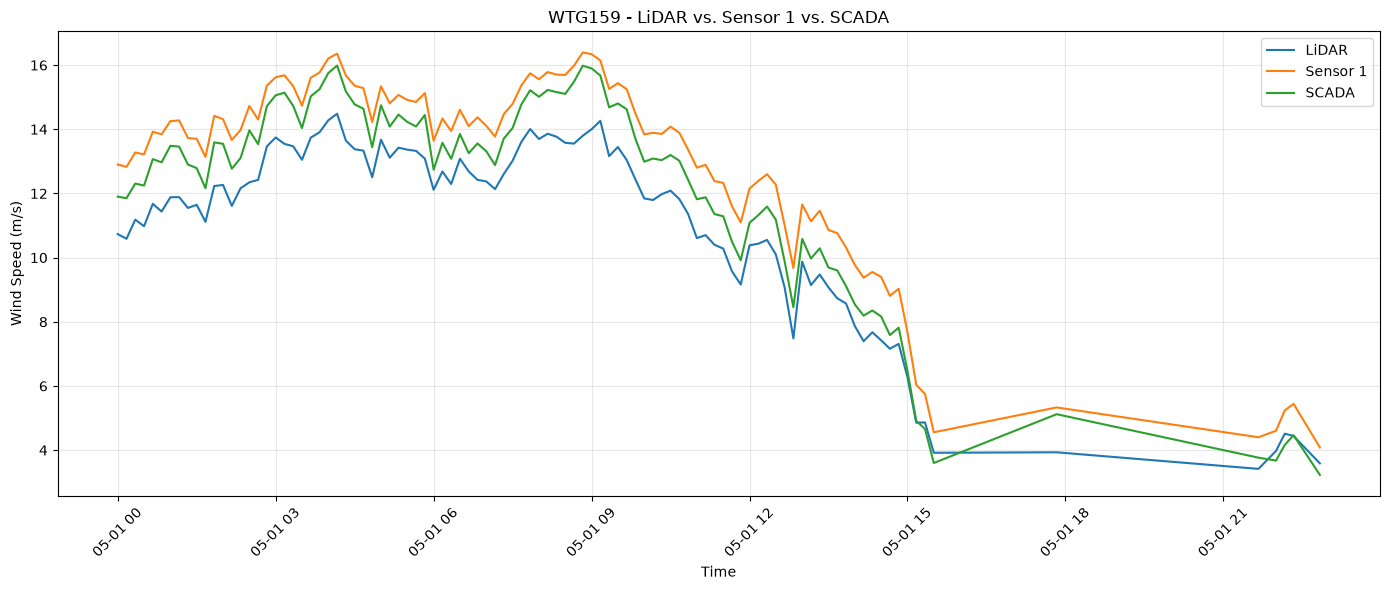

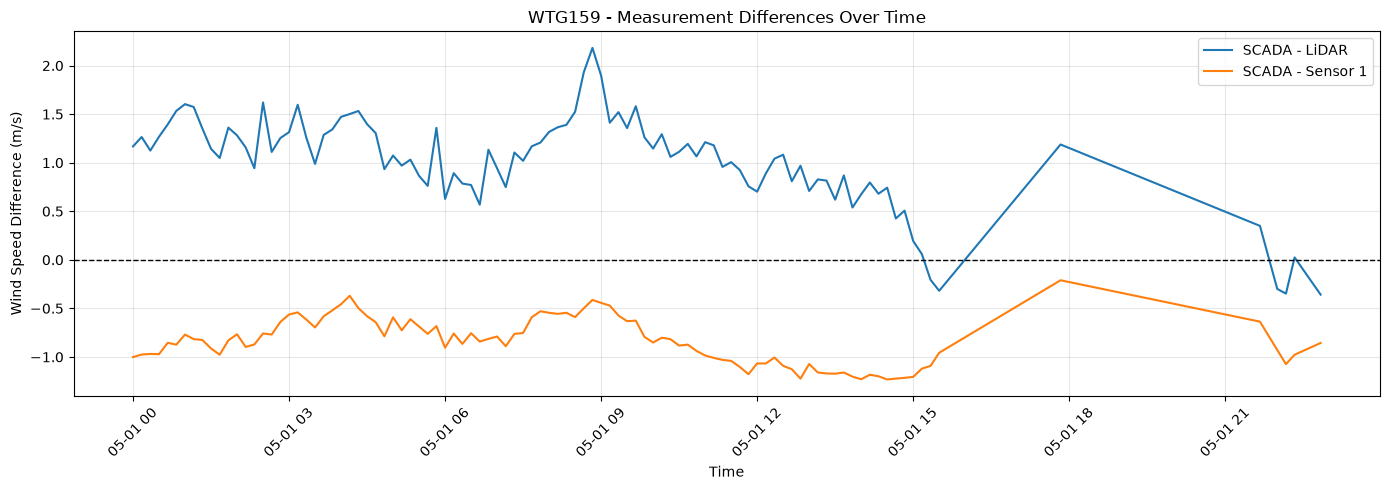

In [21]:
# ==========================================
# WTG159 - WIND SPEED COMPARISON OVER TIME
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# Use our merged LiDAR + SCADA dataset
time_data = wtg159_matched.copy()

time_data["timestamp"] = pd.to_datetime(
    time_data["timestamp"]
)

time_data = time_data.sort_values("timestamp")

# Calculate measurement differences
time_data["scada_lidar_diff"] = (
    time_data["scada_wind_speed"] -
    time_data["lidar_mean"]
)

time_data["scada_sensor_diff"] = (
    time_data["scada_wind_speed"] -
    time_data["sensor_mean"]
)

# ==========================================
# GRAPH 1: WIND SPEED OVER TIME
# ==========================================

plt.figure(figsize=(14, 6))

plt.plot(
    time_data["timestamp"],
    time_data["lidar_mean"],
    label="LiDAR",
    linewidth=1.5
)

plt.plot(
    time_data["timestamp"],
    time_data["sensor_mean"],
    label="Sensor 1",
    linewidth=1.5
)

plt.plot(
    time_data["timestamp"],
    time_data["scada_wind_speed"],
    label="SCADA",
    linewidth=1.5
)

plt.xlabel("Time")
plt.ylabel("Wind Speed (m/s)")
plt.title("WTG159 - LiDAR vs. Sensor 1 vs. SCADA")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==========================================
# GRAPH 2: MEASUREMENT DIFFERENCES
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(
    time_data["timestamp"],
    time_data["scada_lidar_diff"],
    label="SCADA - LiDAR"
)

plt.plot(
    time_data["timestamp"],
    time_data["scada_sensor_diff"],
    label="SCADA - Sensor 1"
)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.xlabel("Time")
plt.ylabel("Wind Speed Difference (m/s)")
plt.title("WTG159 - Measurement Differences Over Time")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

WTG159 - DATA COVERAGE
Matched observations: 100
Expected observations for a full day: 144
Missing intervals: 44

GAPS GREATER THAN 10 MINUTES:


,timestamp,time_difference
94,2026-05-01 17:50:00,0 days 02:20:00
95,2026-05-01 21:40:00,0 days 03:50:00
96,2026-05-01 22:00:00,0 days 00:20:00
99,2026-05-01 22:50:00,0 days 00:30:00


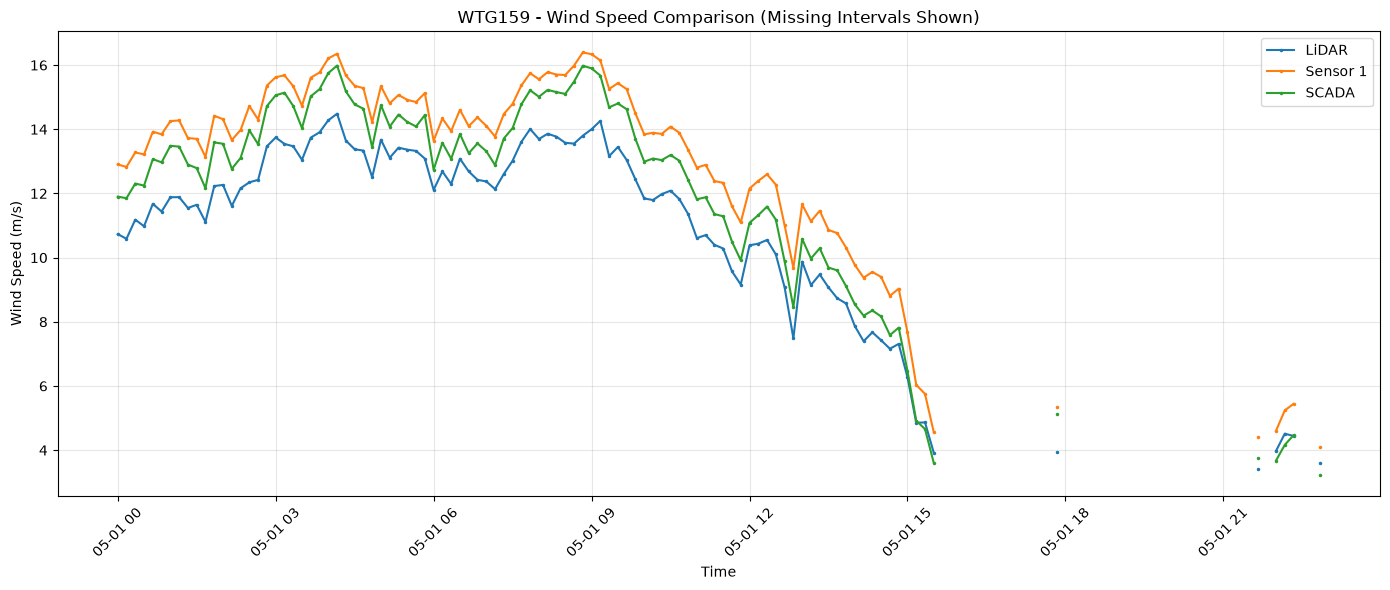

In [22]:
# ==========================================
# WTG159 - CHECK MISSING TIME INTERVALS
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt

# Use our previously merged dataset
check_data = wtg159_matched.copy()

check_data["timestamp"] = pd.to_datetime(
    check_data["timestamp"]
)

check_data = check_data.sort_values("timestamp")

# Calculate time gaps
check_data["time_difference"] = (
    check_data["timestamp"].diff()
)

# Identify gaps greater than 10 minutes
gaps = check_data[
    check_data["time_difference"] > pd.Timedelta(minutes=10)
]

print("WTG159 - DATA COVERAGE")
print("=" * 45)

print("Matched observations:", len(check_data))

print("Expected observations for a full day:", 144)

print("Missing intervals:", 144 - len(check_data))

print("\nGAPS GREATER THAN 10 MINUTES:")
display(
    gaps[["timestamp", "time_difference"]]
)

# ==========================================
# RECREATE GRAPH WITHOUT CONNECTING GAPS
# ==========================================

plot_data = check_data.set_index("timestamp")

# Generate complete 10-minute timeline
full_index = pd.date_range(
    start=plot_data.index.min().normalize(),
    periods=144,
    freq="10min"
)

# Missing intervals become NaN
plot_data = plot_data.reindex(full_index)

plt.figure(figsize=(14, 6))

for col, label in [
    ("lidar_mean", "LiDAR"),
    ("sensor_mean", "Sensor 1"),
    ("scada_wind_speed", "SCADA")
]:

    plt.plot(
        plot_data.index,
        plot_data[col],
        marker=".",
        markersize=3,
        linewidth=1.5,
        label=label
    )

plt.title("WTG159 - Wind Speed Comparison (Missing Intervals Shown)")
plt.xlabel("Time")
plt.ylabel("Wind Speed (m/s)")

plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
# ==========================================
# ALTA10 - ESTIMATE TURBULENCE INTENSITY
# WTG159 - 1 SECOND LIDAR DATA
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Copy original 1-second LiDAR data
ti_data = lidar_sample.copy()

# Convert timestamps
ti_data["timestamp"] = pd.to_datetime(
    ti_data["timestamp"]
)

# Check duplicate timestamps
print(
    "Duplicate timestamps:",
    ti_data["timestamp"].duplicated().sum()
)

# Remove duplicates for aggregation
ti_data = ti_data.drop_duplicates(
    subset="timestamp"
)

# Remove invalid wind speeds
ti_data.loc[
    ~ti_data["lidar_wsp"].between(0, 35),
    "lidar_wsp"
] = np.nan

# Set timestamp index
ti_data = ti_data.set_index("timestamp")

# ==========================================
# CALCULATE 10-MINUTE STATISTICS
# ==========================================

ti_10min = ti_data.resample("10min").agg(
    mean_speed=("lidar_wsp", "mean"),
    std_speed=("lidar_wsp", "std"),
    observations=("lidar_wsp", "count")
)

# Require at least 540 valid samples (90%)
ti_10min = ti_10min[
    (ti_10min["observations"] >= 540) &
    (ti_10min["mean_speed"] >= 3)
].copy()

# Turbulence intensity estimate
ti_10min["TI"] = (
    ti_10min["std_speed"] /
    ti_10min["mean_speed"]
)

# Preliminary Jensen wake decay estimate
ti_10min["estimated_k"] = (
    0.5 * ti_10min["TI"]
)

# ==========================================
# SUMMARY STATISTICS
# ==========================================

print("WTG159 - ESTIMATED TURBULENCE INTENSITY")
print("=" * 48)

print(f"Valid intervals: {len(ti_10min)}")

print(
    f"Mean TI: {ti_10min['TI'].mean():.2%}"
)

print(
    f"Median TI: {ti_10min['TI'].median():.2%}"
)

print(
    f"Median estimated k: "
    f"{ti_10min['estimated_k'].median():.4f}"
)

print(
    f"Current placeholder k: 0.0500"
)

display(ti_10min.head(10))

Duplicate timestamps: 0
WTG159 - ESTIMATED TURBULENCE INTENSITY
Valid intervals: 100
Mean TI: 10.96%
Median TI: 9.96%
Median estimated k: 0.0498
Current placeholder k: 0.0500


,mean_speed,std_speed,observations,TI,estimated_k
timestamp,,,,,
2026-05-01 00:00:00,10.733200,0.819579,600,0.076359,0.038180
2026-05-01 00:10:00,10.587100,0.846627,600,0.079968,0.039984
2026-05-01 00:20:00,11.183383,0.916572,600,0.081958,0.040979
2026-05-01 00:30:00,10.978333,1.118183,600,0.101854,0.050927
2026-05-01 00:40:00,11.676067,1.318999,600,0.112966,0.056483
2026-05-01 00:50:00,11.435683,0.884665,600,0.077360,0.038680
2026-05-01 01:00:00,11.881250,1.040278,600,0.087556,0.043778
2026-05-01 01:10:00,11.885483,1.577866,600,0.132756,0.066378
2026-05-01 01:20:00,11.548083,1.295838,600,0.112212,0.056106


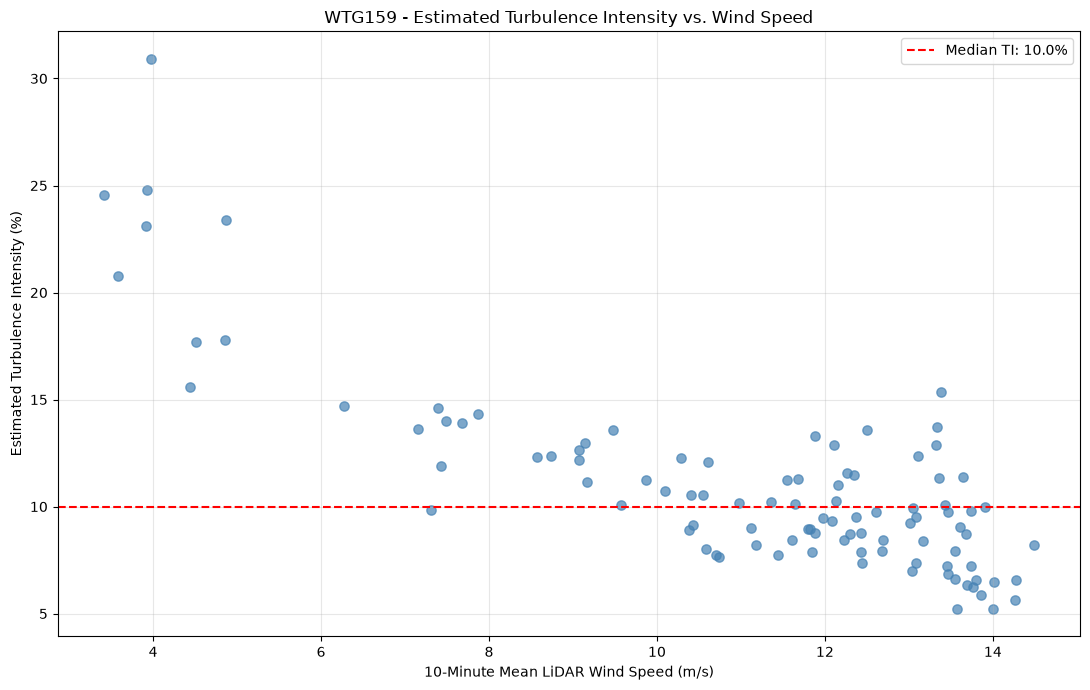

In [24]:
# ==========================================
# TURBULENCE INTENSITY VS WIND SPEED
# ==========================================

plt.figure(figsize=(11, 7))

plt.scatter(
    ti_10min["mean_speed"],
    ti_10min["TI"] * 100,
    alpha=0.7,
    s=45,
    color="steelblue"
)

plt.axhline(
    ti_10min["TI"].median() * 100,
    color="red",
    linestyle="--",
    label=(
        f"Median TI: "
        f"{ti_10min['TI'].median():.1%}"
    )
)

plt.xlabel("10-Minute Mean LiDAR Wind Speed (m/s)")
plt.ylabel("Estimated Turbulence Intensity (%)")

plt.title(
    "WTG159 - Estimated Turbulence Intensity "
    "vs. Wind Speed"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# ==========================================
# WTG159 - LIDAR DATA QUALITY CHECK
# ==========================================

quality = lidar_sample.copy()

quality["timestamp"] = pd.to_datetime(
    quality["timestamp"]
)

# Keep only physically plausible wind speeds
quality["valid_speed"] = quality["lidar_wsp"].where(
    quality["lidar_wsp"].between(0, 35)
)

# Aggregate all intervals, without dropping any
quality_10min = (
    quality.set_index("timestamp")
    .resample("10min")
    .agg(
        total_records=("lidar_wsp", "size"),
        valid_records=("valid_speed", "count"),
        mean_speed=("valid_speed", "mean")
    )
)

# Identify why intervals were excluded
quality_10min["low_coverage"] = (
    quality_10min["valid_records"] < 540
)

quality_10min["low_wind_speed"] = (
    quality_10min["mean_speed"] < 3
)

quality_10min["included"] = (
    ~quality_10min["low_coverage"] &
    ~quality_10min["low_wind_speed"]
)

print("TOTAL INTERVALS:", len(quality_10min))
print("VALID INTERVALS:", quality_10min["included"].sum())

print("\nLow coverage intervals:",
      quality_10min["low_coverage"].sum())

print("Low wind speed intervals:",
      quality_10min["low_wind_speed"].sum())

print("\nEXCLUDED INTERVALS:")
display(
    quality_10min[
        ~quality_10min["included"]
    ].head(20)
)

TOTAL INTERVALS: 144
VALID INTERVALS: 100

Low coverage intervals: 44
Low wind speed intervals: 20

EXCLUDED INTERVALS:


,total_records,valid_records,mean_speed,low_coverage,low_wind_speed,included
timestamp,,,,,,
2026-05-01 15:40:00,600,525,3.329390,True,False,False
2026-05-01 15:50:00,600,410,2.884024,True,True,False
2026-05-01 16:00:00,600,496,2.843629,True,True,False
2026-05-01 16:10:00,600,372,2.905430,True,True,False
2026-05-01 16:20:00,600,96,2.141875,True,True,False
2026-05-01 16:30:00,600,6,1.600000,True,True,False
2026-05-01 16:40:00,600,37,1.878378,True,True,False
2026-05-01 16:50:00,600,58,1.906207,True,True,False
2026-05-01 17:00:00,600,458,2.830611,True,True,False


our existing filters:
- At least 540 valid 1-second measurements per 10-minute interval (90% coverage).
- Mean wind speed of at least 3 m/s.
- Wind-speed readings between 0 and 35 m/s.

In [26]:
# ==============================================
# ALTA10 - MULTI-TURBINE LIDAR ANALYSIS
# Estimate Turbulence Intensity and Jensen k
# ==============================================

import pandas as pd
import numpy as np
from pathlib import Path

# ----------------------------------------------
# 1. PROJECT DIRECTORY
# ----------------------------------------------

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

lidar_path = project_path / "data" / "raw" / "lidar_data"

# LiDAR turbines
lidar_turbines = [
    "159",
    "170",
    "171",
    "173",
    "180",
    "184"
]

# ----------------------------------------------
# 2. ANALYSIS PARAMETERS
# ----------------------------------------------

min_valid_records = 540    # 90% of 600 seconds
min_wind_speed = 3.0       # m/s
max_wind_speed = 35.0      # m/s

# Preliminary empirical relationship
k_factor = 0.5

# Store 10-minute results
all_intervals = []
file_counts = []

# ----------------------------------------------
# 3. PROCESS EACH TURBINE
# ----------------------------------------------

for turbine_id in lidar_turbines:

    folder = lidar_path / f"WTG_T{turbine_id}"

    files = sorted(folder.glob("*.csv"))

    print(f"\nProcessing WTG{turbine_id}")
    print(f"Files found: {len(files)}")

    processed_files = 0

    for file in files:

        # Read only columns needed for TI
        df = pd.read_csv(
            file,
            usecols=["timestamp", "lidar_wsp"]
        )

        # Convert timestamps and speeds
        df["timestamp"] = pd.to_datetime(
            df["timestamp"],
            errors="coerce"
        )

        df["lidar_wsp"] = pd.to_numeric(
            df["lidar_wsp"],
            errors="coerce"
        )

        df = df.dropna(subset=["timestamp"])

        # Avoid duplicate measurements
        df = df.drop_duplicates(
            subset="timestamp"
        )

        # Replace invalid speeds with NaN
        df["valid_speed"] = df["lidar_wsp"].where(
            df["lidar_wsp"].between(
                0, max_wind_speed
            )
        )

        # --------------------------------------
        # 4. CALCULATE 10-MINUTE STATISTICS
        # --------------------------------------

        daily = (
            df.set_index("timestamp")
            .resample("10min")
            .agg(
                total_records=("lidar_wsp", "size"),
                valid_records=("valid_speed", "count"),
                mean_speed=("valid_speed", "mean"),
                std_speed=("valid_speed", "std")
            )
        )

        # Include all 144 expected daily intervals
        file_date = pd.Timestamp(file.stem)

        full_day = pd.date_range(
            start=file_date,
            periods=144,
            freq="10min"
        )

        daily = daily.reindex(full_day)

        daily.index.name = "timestamp"

        daily["total_records"] = (
            daily["total_records"].fillna(0)
        )

        daily["valid_records"] = (
            daily["valid_records"].fillna(0)
        )

        # Apply quality requirements
        daily["valid_interval"] = (
            (daily["valid_records"] >= min_valid_records) &
            (daily["mean_speed"] >= min_wind_speed)
        )

        # --------------------------------------
        # 5. CALCULATE TI AND ESTIMATED k
        # --------------------------------------

        daily["TI"] = (
            daily["std_speed"] /
            daily["mean_speed"]
        )

        daily["estimated_k"] = (
            k_factor * daily["TI"]
        )

        # Exclude invalid intervals from statistics
        daily.loc[
            ~daily["valid_interval"],
            ["TI", "estimated_k"]
        ] = np.nan

        # Add turbine identifier
        daily["turbine"] = f"WTG{turbine_id}"

        daily = daily.reset_index()

        all_intervals.append(daily)

        processed_files += 1

    file_counts.append({
        "turbine": f"WTG{turbine_id}",
        "files_processed": processed_files
    })

    print("Completed.")

# ----------------------------------------------
# 6. COMBINE ALL TURBINE RESULTS
# ----------------------------------------------

lidar_ti_all = pd.concat(
    all_intervals,
    ignore_index=True
)

file_counts = pd.DataFrame(file_counts)

# ----------------------------------------------
# 7. CREATE SUMMARY TABLE
# ----------------------------------------------

ti_summary = (
    lidar_ti_all.groupby("turbine")
    .agg(
        total_intervals=("valid_interval", "size"),
        valid_intervals=("valid_interval", "sum"),
        mean_TI=("TI", "mean"),
        median_TI=("TI", "median"),
        mean_k=("estimated_k", "mean"),
        median_k=("estimated_k", "median")
    )
    .reset_index()
)

# Mean wind speed using only valid intervals
valid_data = lidar_ti_all[
    lidar_ti_all["valid_interval"]
].copy()

speed_summary = (
    valid_data.groupby("turbine")["mean_speed"]
    .mean()
    .rename("mean_wind_speed")
    .reset_index()
)

ti_summary = ti_summary.merge(
    speed_summary,
    on="turbine",
    how="left"
)

ti_summary = ti_summary.merge(
    file_counts,
    on="turbine",
    how="left"
)

# Percentage of intervals passing quality checks
ti_summary["valid_pct"] = (
    ti_summary["valid_intervals"] /
    ti_summary["total_intervals"] * 100
)

# Convert TI to percentage for presentation
ti_summary["mean_TI_pct"] = (
    ti_summary["mean_TI"] * 100
)

ti_summary["median_TI_pct"] = (
    ti_summary["median_TI"] * 100
)

# ----------------------------------------------
# 8. DISPLAY FINAL SUMMARY
# ----------------------------------------------

summary_display = ti_summary[
    [
        "turbine",
        "files_processed",
        "valid_intervals",
        "valid_pct",
        "mean_wind_speed",
        "mean_TI_pct",
        "median_TI_pct",
        "mean_k",
        "median_k"
    ]
].copy()

summary_display = summary_display.sort_values(
    "median_k",
    ascending=False
)

print("\nALTA10 - MULTI-TURBINE LIDAR SUMMARY")
print("=" * 55)

display(summary_display.round(4))


Processing WTG159
Files found: 134
Completed.

Processing WTG170
Files found: 133
Completed.

Processing WTG171
Files found: 134
Completed.

Processing WTG173
Files found: 134
Completed.

Processing WTG180
Files found: 133
Completed.

Processing WTG184
Files found: 134
Completed.

ALTA10 - MULTI-TURBINE LIDAR SUMMARY


,turbine,files_processed,valid_intervals,valid_pct,mean_wind_speed,mean_TI_pct,median_TI_pct,mean_k,median_k
3,WTG173,134,14551,75.4094,8.9574,15.6054,15.5892,0.0780,0.0779
2,WTG171,134,14965,77.5549,8.8352,15.5892,14.9416,0.0779,0.0747
5,WTG184,134,14675,76.0520,8.8604,14.7642,14.3444,0.0738,0.0717
1,WTG170,133,14866,77.6211,9.3547,14.5378,13.5327,0.0727,0.0677
4,WTG180,133,15189,79.3076,10.7603,13.2170,11.6411,0.0661,0.0582
0,WTG159,134,15165,78.5914,10.2995,11.3871,10.0075,0.0569,0.0500



A critical distinction: These are six LiDAR-based turbulence proxies converted using \(k=0.5TI\), not six independently measured or calibrated Jensen coefficients. Before deciding whether to use different coefficients in the wake models, we should control for wind speed, wind direction, instrument quality, and wake exposure.

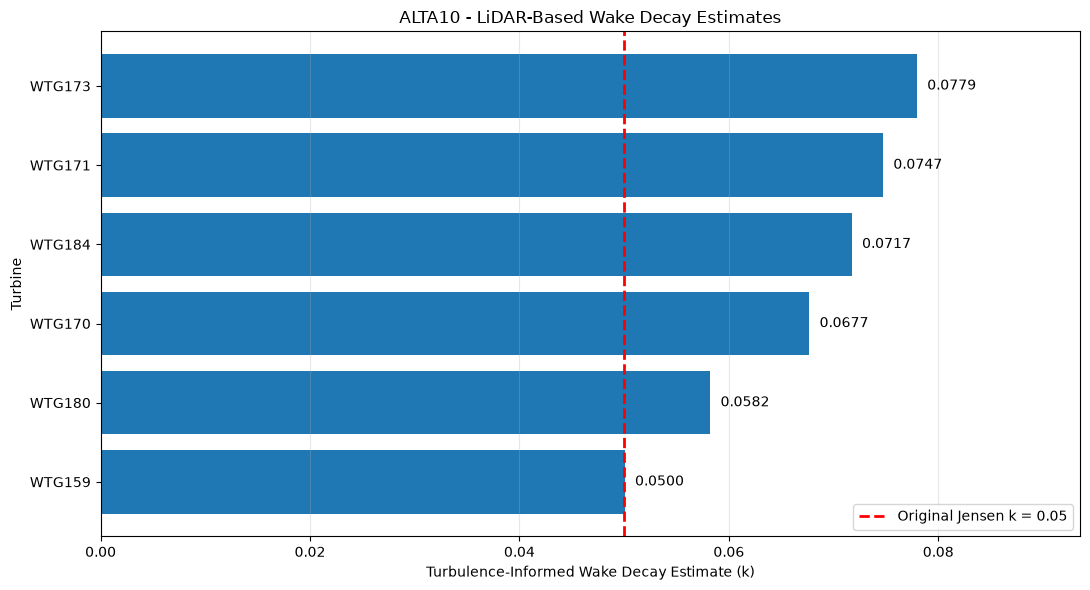

In [27]:
# ==========================================
# VISUAL 1 - ESTIMATED WAKE DECAY COMPARISON
# ==========================================

import matplotlib.pyplot as plt

plot_data = summary_display.sort_values(
    "median_k", ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["turbine"],
    plot_data["median_k"]
)

# Original wake decay assumption
ax.axvline(
    0.05,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Original Jensen k = 0.05"
)

for bar, value in zip(bars, plot_data["median_k"]):
    ax.text(
        value + 0.001,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center"
    )

ax.set_xlim(0, plot_data["median_k"].max() * 1.2)

ax.set_xlabel("Turbulence-Informed Wake Decay Estimate (k)")
ax.set_ylabel("Turbine")
ax.set_title("ALTA10 - LiDAR-Based Wake Decay Estimates")

ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

LiDAR turbines mapped: 6


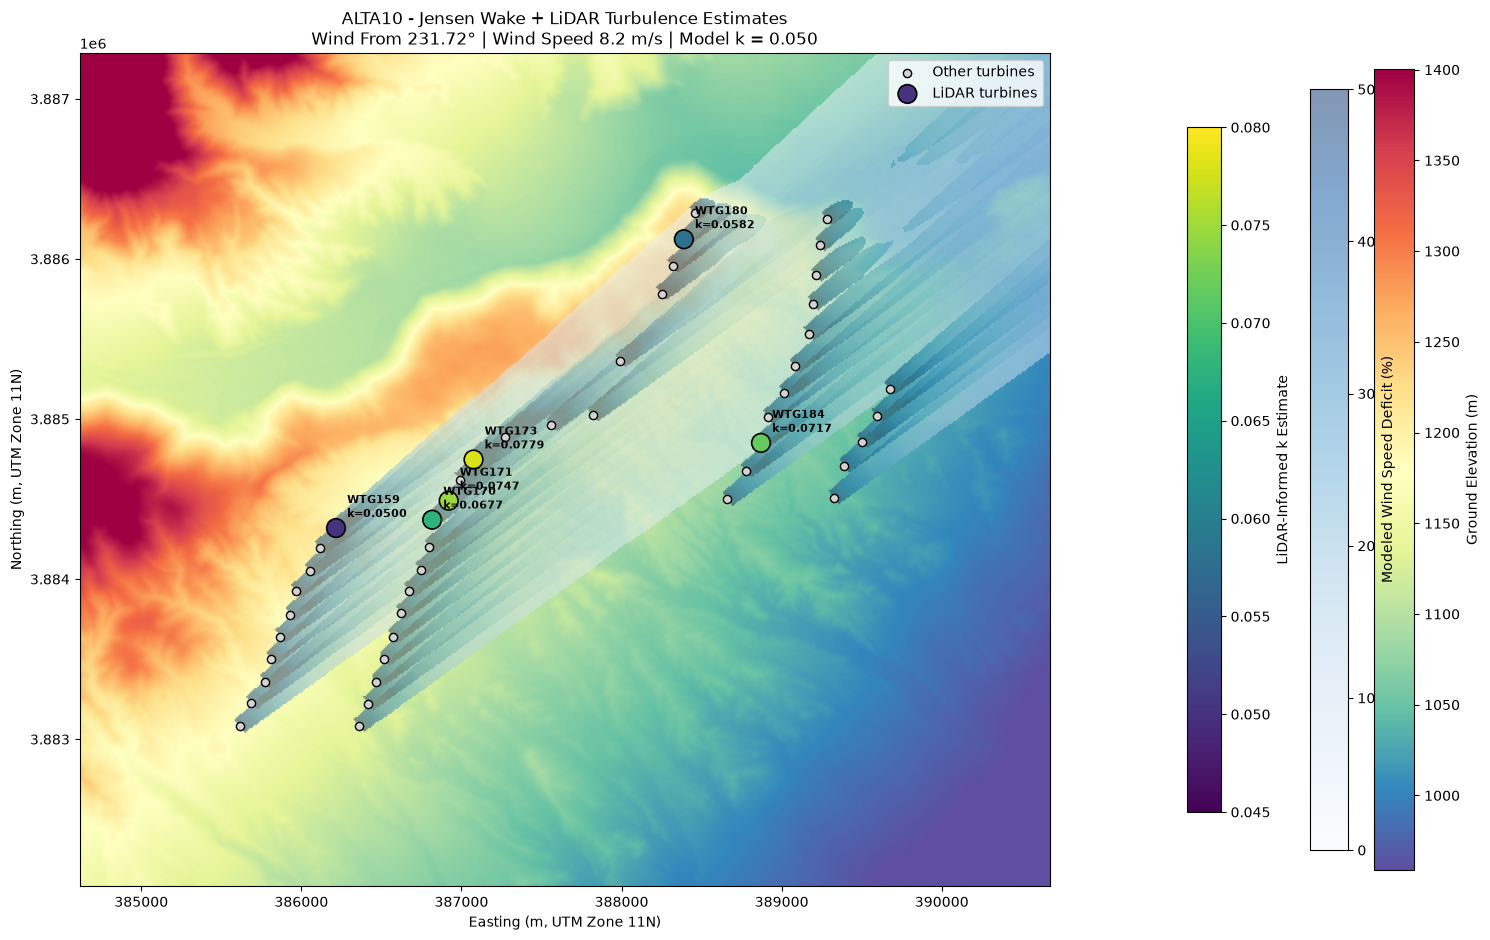

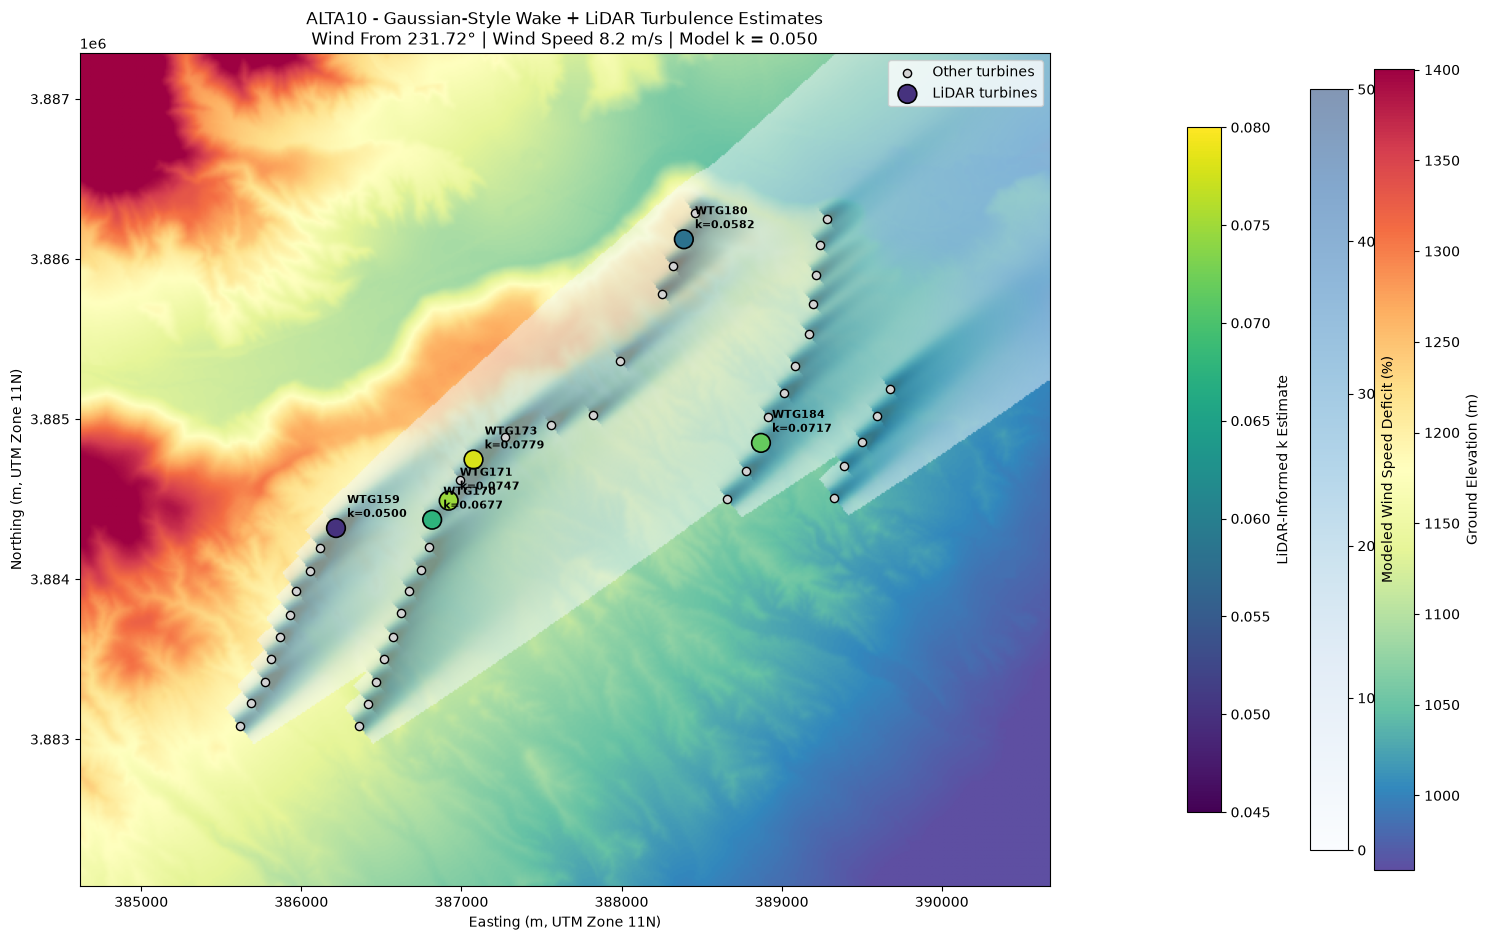

In [30]:
# ==============================================
# ALTA10 - TERRAIN + WAKE + LIDAR k MAP
# ==============================================

import numpy as np
import matplotlib.pyplot as plt

# Join LiDAR estimates with turbine coordinates
k_locations = farm[
    ["turbine", "x", "y"]
].merge(
    ti_summary[
        ["turbine", "median_k", "median_TI_pct"]
    ],
    on="turbine",
    how="inner",
    validate="one_to_one"
)

print(f"LiDAR turbines mapped: {len(k_locations)}")

def plot_k_wake_map(deficit, model_name):

    fig, ax = plt.subplots(figsize=(15, 10))

    # 1. TERRAIN BACKGROUND
    elevation_img = ax.imshow(
        terrain,
        extent=extent,
        origin="upper",
        cmap="Spectral_r",
        vmin=np.nanpercentile(terrain, 2),
        vmax=np.nanpercentile(terrain, 98),
        zorder=1
    )

    # 2. WAKE DEFICIT OVERLAY
    wake_masked = np.ma.masked_where(
        (deficit < 0.01) | ~np.isfinite(terrain),
        deficit * 100
    )

    wake_img = ax.imshow(
        wake_masked,
        extent=extent,
        origin="upper",
        cmap="Blues",
        vmin=0,
        vmax=50,
        alpha=0.5,
        zorder=2
    )

    # 3. ALL TURBINE LOCATIONS
    ax.scatter(
        farm["x"],
        farm["y"],
        c="lightgray",
        edgecolors="black",
        s=35,
        zorder=4,
        label="Other turbines"
    )

    # 4. SIX LIDAR TURBINES COLORED BY k
    k_points = ax.scatter(
        k_locations["x"],
        k_locations["y"],
        c=k_locations["median_k"],
        cmap="viridis",
        vmin=0.045,
        vmax=0.080,
        s=180,
        edgecolors="black",
        linewidths=1.2,
        zorder=6,
        label="LiDAR turbines"
    )

    # 5. LABEL LIDAR TURBINES
    for _, row in k_locations.iterrows():

        ax.annotate(
            f'{row["turbine"]}\nk={row["median_k"]:.4f}',
            (row["x"], row["y"]),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold",
            zorder=7
        )

    # 6. COLORBARS
    cbar1 = fig.colorbar(
        elevation_img, ax=ax,
        fraction=0.03, pad=0.02
    )
    cbar1.set_label("Ground Elevation (m)")

    cbar2 = fig.colorbar(
        wake_img, ax=ax,
        fraction=0.03, pad=0.07
    )
    cbar2.set_label("Modeled Wind Speed Deficit (%)")

    cbar3 = fig.colorbar(
        k_points, ax=ax,
        fraction=0.03, pad=0.12
    )
    cbar3.set_label("LiDAR-Informed k Estimate")

    ax.set_title(
        f"ALTA10 - {model_name}\n"
        f"Wind From {wind_from_deg:.2f}° | "
        f"Wind Speed {free_stream_speed:.1f} m/s | "
        f"Model k = {wake_decay:.3f}"
    )

    ax.set_xlabel("Easting (m, UTM Zone 11N)")
    ax.set_ylabel("Northing (m, UTM Zone 11N)")
    ax.set_aspect("equal")

    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()


# ==============================================
# CREATE BOTH MAPS
# ==============================================

plot_k_wake_map(
    jensen_deficit,
    "Jensen Wake + LiDAR Turbulence Estimates"
)

plot_k_wake_map(
    gaussian_deficit,
    "Gaussian-Style Wake + LiDAR Turbulence Estimates"
)

Intervals with all six turbines: 8387
Intervals with all six at 7-13 m/s: 2509


,median_TI_pct,mean_TI_pct,median_k_proxy,observations
turbine,,,,
WTG173,14.6330,14.1521,0.0732,2509
WTG171,12.2194,12.6600,0.0611,2509
WTG184,12.1319,12.4783,0.0607,2509
WTG180,10.5945,11.2793,0.0530,2509
WTG170,10.4180,10.8599,0.0521,2509
WTG159,9.4746,10.0242,0.0474,2509


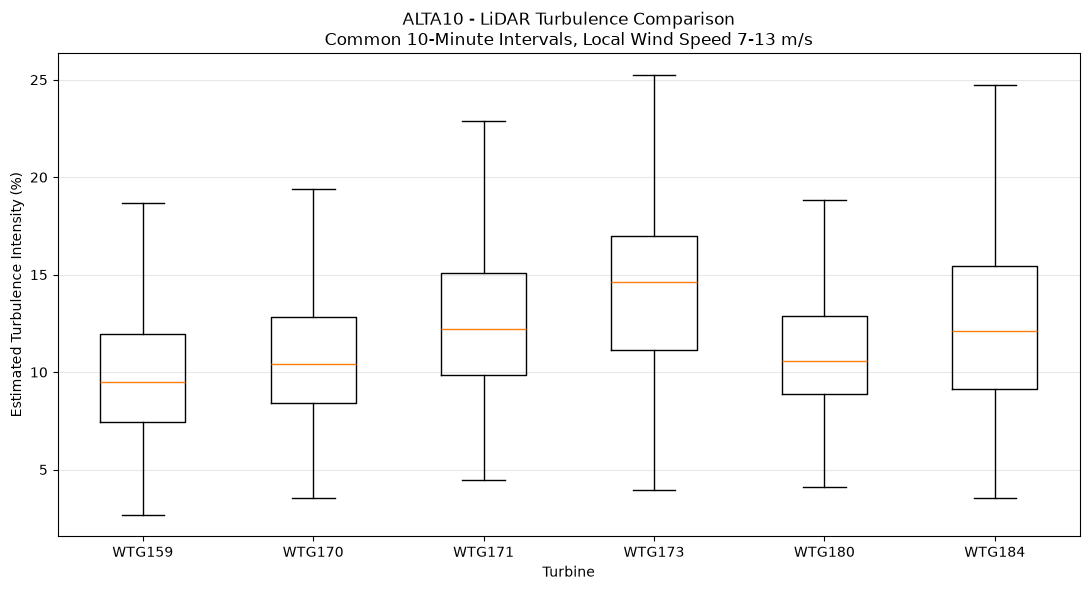

In [31]:
# ==========================================
# ALTA10 - MATCHED LIDAR TURBULENCE COMPARISON
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

# Use previously calculated 10-minute data
matched_data = lidar_ti_all[
    lidar_ti_all["valid_interval"]
].copy()

matched_data["timestamp"] = pd.to_datetime(
    matched_data["timestamp"]
)

# Verify that each turbine/timestamp is unique
if matched_data.duplicated(
    ["timestamp", "turbine"]
).any():
    raise ValueError("Duplicate turbine/timestamp records found.")

# Create a common timeline for all six turbines
speed = matched_data.pivot(
    index="timestamp",
    columns="turbine",
    values="mean_speed"
).reindex(columns=turbines)

ti = matched_data.pivot(
    index="timestamp",
    columns="turbine",
    values="TI"
).reindex(columns=turbines)

# Identify intervals where all six have valid data
common = speed.notna().all(axis=1) & ti.notna().all(axis=1)

# Further restrict to comparable LOCAL wind speeds
speed_filter = (
    speed.ge(7) & speed.le(13)
).all(axis=1)

selected = common & speed_filter

matched_ti = ti.loc[selected]

print("Intervals with all six turbines:", common.sum())
print("Intervals with all six at 7-13 m/s:", selected.sum())

if matched_ti.empty:
    print("No qualifying intervals. Try a wider wind-speed range.")

else:
    # Summarize observations under matched conditions
    comparison_summary = pd.DataFrame({
        "median_TI_pct": matched_ti.median() * 100,
        "mean_TI_pct": matched_ti.mean() * 100,
        "median_k_proxy": matched_ti.median() * 0.5,
        "observations": matched_ti.count()
    })

    comparison_summary.index.name = "turbine"

    display(
        comparison_summary.sort_values(
            "median_TI_pct",
            ascending=False
        ).round(4)
    )

    # Plot distribution of TI across matched intervals
    fig, ax = plt.subplots(figsize=(11, 6))

    ax.boxplot(
        [
            matched_ti[t].dropna().values * 100
            for t in turbines
        ],
        tick_labels=turbines,
        showfliers=False
    )

    ax.set_ylabel("Estimated Turbulence Intensity (%)")
    ax.set_xlabel("Turbine")
    ax.set_title(
        "ALTA10 - LiDAR Turbulence Comparison\n"
        "Common 10-Minute Intervals, Local Wind Speed 7-13 m/s"
    )

    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

In [33]:
# =============================================
# ALTA10 - INVESTIGATE LIDAR PHI CONVENTION
# WTG159: MAY 1, 2026
# =============================================

import numpy as np
import pandas as pd

phi_cols = ["lidar_phi", "sensor1_phi", "wtg1_phi"]

# Original 1-second LiDAR file
phi_data = lidar_sample[
    ["timestamp"] + phi_cols
].copy()

phi_data["timestamp"] = pd.to_datetime(
    phi_data["timestamp"]
)

print("ORIGINAL ANGLE RANGES")
display(phi_data[phi_cols].describe().round(2))

# Circular mean: avoids incorrect averages near 0/360
for col in phi_cols:
    angles = pd.to_numeric(phi_data[col], errors="coerce")
    angles = angles.where(angles.between(-360, 360))

    radians = np.deg2rad(angles)

    phi_data[col + "_sin"] = np.sin(radians)
    phi_data[col + "_cos"] = np.cos(radians)

phi_data["timestamp"] = phi_data["timestamp"].dt.floor("10min")

agg_cols = {
    col + suffix: "mean"
    for col in phi_cols
    for suffix in ["_sin", "_cos"]
}

phi_10min = (
    phi_data.groupby("timestamp")
    .agg(agg_cols)
    .reset_index()
)

for col in phi_cols:
    phi_10min[col + "_mean"] = (
        np.degrees(
            np.arctan2(
                phi_10min[col + "_sin"],
                phi_10min[col + "_cos"]
            )
        ) % 360
    )

# SCADA comparison
scada_dir = scada.loc[
    scada["turbine"].astype(str).str.strip() == "WTG159",
    ["utc", "wind_direction",
     "wind_direction_relative", "nacelle_pos"]
].copy()

scada_dir["timestamp"] = pd.to_datetime(
    scada_dir["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

# Stop if repeated timestamps would make the comparison ambiguous
if scada_dir["timestamp"].duplicated().any():
    raise ValueError("Duplicate SCADA timestamps found.")

direction_check = phi_10min.merge(
    scada_dir.drop(columns="utc"),
    on="timestamp",
    how="inner",
    validate="one_to_one"
)

print("\nMATCHED DIRECTION MEASUREMENTS:")
display(
    direction_check[
        [
            "timestamp",
            "lidar_phi_mean",
            "sensor1_phi_mean",
            "wtg1_phi_mean",
            "wind_direction",
            "wind_direction_relative",
            "nacelle_pos"
        ]
    ].head(10).round(2)
)

# Circular angular difference, in degrees
def angular_difference(a, b):
    return (a - b + 180) % 360 - 180

# Evaluate possible reference conventions
p = direction_check["lidar_phi_mean"]
yaw = direction_check["nacelle_pos"]
reference = direction_check["wind_direction"]

candidates = {
    "LiDAR phi as absolute": p,
    "LiDAR phi + 180": p + 180,
    "Nacelle + LiDAR phi": yaw + p,
    "Nacelle - LiDAR phi": yaw - p,
    "Nacelle + LiDAR phi + 180": yaw + p + 180,
    "Nacelle - LiDAR phi + 180": yaw - p + 180
}

results = []

for name, candidate in candidates.items():
    error = angular_difference(candidate, reference)

    results.append({
        "interpretation": name,
        "median_absolute_error_deg": np.nanmedian(np.abs(error)),
        "mean_absolute_error_deg": np.nanmean(np.abs(error))
    })

direction_results = pd.DataFrame(results).sort_values(
    "median_absolute_error_deg"
)

print("\nCANDIDATE DIRECTION CONVENTIONS:")
display(direction_results.round(2))

# Compare raw LiDAR angle to reported relative direction
relative_error = angular_difference(
    direction_check["lidar_phi_mean"],
    direction_check["wind_direction_relative"]
)

print(
    "\nMedian absolute difference from SCADA relative direction:",
    f"{np.nanmedian(np.abs(relative_error)):.2f} degrees"
)

ORIGINAL ANGLE RANGES


,lidar_phi,sensor1_phi,wtg1_phi
count,71782.00,86400.00,44170.00
mean,-0.29,2.07,62.08
std,12.17,63.52,140.46
min,-45.00,-180.00,-180.00
25%,-7.20,-15.00,-74.00
50%,0.20,-4.00,157.60
75%,7.00,4.50,172.75
max,46.00,180.00,180.00



MATCHED DIRECTION MEASUREMENTS:


C:\Users\alex-\AppData\Local\Temp\ipykernel_16024\2620544574.py:93: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(2)


,timestamp,lidar_phi_mean,sensor1_phi_mean,wtg1_phi_mean,wind_direction,wind_direction_relative,nacelle_pos
0,2026-05-01 00:00:00,1.93,353.97,172.01,28.27,-7.64,37.00
1,2026-05-01 00:10:00,0.96,353.68,171.76,27.68,-7.45,35.50
2,2026-05-01 00:20:00,3.74,354.92,172.68,27.31,-6.95,31.33
3,2026-05-01 00:30:00,3.08,356.68,175.91,29.45,-4.29,34.86
4,2026-05-01 00:40:00,1.07,352.69,NaN,30.37,-6.92,36.50
5,2026-05-01 00:50:00,0.26,351.98,NaN,32.45,-7.44,38.50
6,2026-05-01 01:00:00,2.42,355.03,NaN,34.36,-4.80,40.65
7,2026-05-01 01:10:00,0.78,353.76,NaN,33.15,-5.99,41.00
8,2026-05-01 01:20:00,0.43,349.65,NaN,30.21,-10.22,40.48
9,2026-05-01 01:30:00,358.84,349.10,NaN,33.03,-11.03,43.50



CANDIDATE DIRECTION CONVENTIONS:


,interpretation,median_absolute_error_deg,mean_absolute_error_deg
3,Nacelle - LiDAR phi,7.34,10.86
2,Nacelle + LiDAR phi,7.85,10.43
0,LiDAR phi as absolute,36.33,56.64
1,LiDAR phi + 180,143.67,123.36
4,Nacelle + LiDAR phi + 180,172.15,169.57
5,Nacelle - LiDAR phi + 180,172.66,169.14



Median absolute difference from SCADA relative direction: 8.22 degrees


MATCHED LIDAR-SCADA OBSERVATIONS: 15012

DIRECTIONAL TURBULENCE SUMMARY:


,turbine,sector_center,median_TI,mean_TI,observations,median_TI_pct
0,WTG159,15.0,0.105,0.113,486,10.529
1,WTG159,45.0,0.099,0.102,611,9.858
2,WTG159,75.0,0.107,0.116,18,NaN
3,WTG159,105.0,0.105,0.104,73,10.513
4,WTG159,135.0,0.092,0.097,410,9.163
5,WTG159,165.0,0.075,0.079,108,7.516
6,WTG159,195.0,0.122,0.118,4,NaN
7,WTG159,225.0,0.090,0.095,535,9.040
8,WTG159,255.0,0.086,0.089,164,8.556
9,WTG159,285.0,0.123,0.126,9,NaN


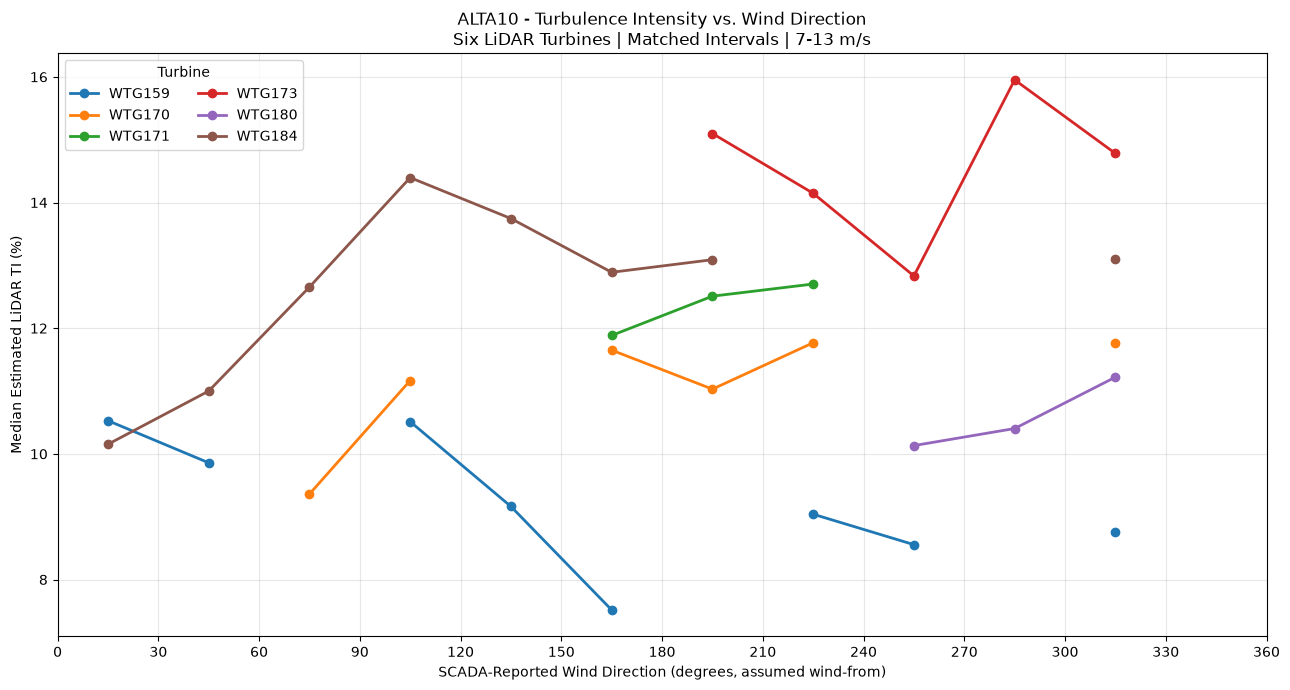

In [34]:
# ==============================================
# ALTA10 - TURBULENCE INTENSITY VS WIND DIRECTION
# ALL SIX LIDAR TURBINES
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

# ----------------------------------------------
# 1. PREPARE LIDAR TI
# ----------------------------------------------

direction_ti = lidar_ti_all[
    lidar_ti_all["valid_interval"] &
    lidar_ti_all["turbine"].isin(turbines)
][
    ["timestamp", "turbine", "TI", "mean_speed"]
].copy()

direction_ti["timestamp"] = pd.to_datetime(
    direction_ti["timestamp"]
)

# Use common timestamps and the 7-13 m/s filter
# from the previous matched comparison
use_matched_periods = True

if use_matched_periods:
    direction_ti = direction_ti[
        direction_ti["timestamp"].isin(matched_ti.index)
    ].copy()

# ----------------------------------------------
# 2. PREPARE SCADA WIND DIRECTION
# ----------------------------------------------

scada_direction = scada.loc[
    scada["turbine"].astype(str).str.strip().isin(turbines),
    ["utc", "turbine", "wind_direction"]
].copy()

scada_direction["timestamp"] = pd.to_datetime(
    scada_direction["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

scada_direction["wind_direction"] = pd.to_numeric(
    scada_direction["wind_direction"],
    errors="coerce"
)

scada_direction["turbine"] = (
    scada_direction["turbine"].astype(str).str.strip()
)

if scada_direction.duplicated(
    ["timestamp", "turbine"]
).any():
    raise ValueError("Duplicate SCADA turbine/timestamp records.")

# ----------------------------------------------
# 3. MERGE LIDAR WITH SCADA DIRECTION
# ----------------------------------------------

direction_ti = direction_ti.merge(
    scada_direction[
        ["timestamp", "turbine", "wind_direction"]
    ],
    on=["timestamp", "turbine"],
    how="inner",
    validate="one_to_one"
)

direction_ti = direction_ti.dropna(
    subset=["TI", "wind_direction"]
)

# Keep physically plausible direction readings
direction_ti = direction_ti[
    direction_ti["wind_direction"].between(0, 360)
].copy()

direction_ti["direction_deg"] = (
    direction_ti["wind_direction"] % 360
)

# ----------------------------------------------
# 4. CREATE 30-DEGREE DIRECTION SECTORS
# ----------------------------------------------

bin_width = 30

direction_ti["sector"] = (
    np.floor(direction_ti["direction_deg"] / bin_width)
    .astype(int)
)

direction_ti["sector_center"] = (
    direction_ti["sector"] * bin_width + bin_width / 2
)

# ----------------------------------------------
# 5. CALCULATE MEDIAN TI BY DIRECTION
# ----------------------------------------------

direction_summary = (
    direction_ti.groupby(["turbine", "sector_center"])
    .agg(
        median_TI=("TI", "median"),
        mean_TI=("TI", "mean"),
        observations=("TI", "count")
    )
    .reset_index()
)

direction_summary["median_TI_pct"] = (
    direction_summary["median_TI"] * 100
)

# Avoid drawing conclusions from sparse sectors
min_observations = 20

direction_summary.loc[
    direction_summary["observations"] < min_observations,
    "median_TI_pct"
] = np.nan

print("MATCHED LIDAR-SCADA OBSERVATIONS:",
      len(direction_ti))

print("\nDIRECTIONAL TURBULENCE SUMMARY:")
display(direction_summary.round(3))

# ----------------------------------------------
# 6. CREATE DIRECTIONAL TURBULENCE GRAPH
# ----------------------------------------------

fig, ax = plt.subplots(figsize=(13, 7))

sector_centers = np.arange(15, 360, 30)

for turbine in turbines:

    turbine_data = (
        direction_summary[
            direction_summary["turbine"] == turbine
        ]
        .set_index("sector_center")
        .reindex(sector_centers)
    )

    ax.plot(
        sector_centers,
        turbine_data["median_TI_pct"],
        marker="o",
        linewidth=2,
        label=turbine
    )

ax.set_xticks(np.arange(0, 361, 30))
ax.set_xlim(0, 360)

ax.set_xlabel(
    "SCADA-Reported Wind Direction (degrees, assumed wind-from)"
)

ax.set_ylabel("Median Estimated LiDAR TI (%)")

ax.set_title(
    "ALTA10 - Turbulence Intensity vs. Wind Direction\n"
    "Six LiDAR Turbines | Matched Intervals | 7-13 m/s"
)

ax.grid(alpha=0.3)
ax.legend(title="Turbine", ncol=2)

plt.tight_layout()
plt.show()

In [35]:
# ==============================================
# ALTA10 - CROSS-TURBINE DIRECTION VERIFICATION
# ==============================================

import pandas as pd
import numpy as np

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

# Select SCADA direction measurements
direction_check = scada[
    [
        "utc",
        "turbine",
        "wind_direction",
        "wind_direction_relative",
        "nacelle_pos"
    ]
].copy()

direction_check["turbine"] = (
    direction_check["turbine"].astype(str).str.strip()
)

direction_check = direction_check[
    direction_check["turbine"].isin(turbines)
].copy()

direction_check["timestamp"] = pd.to_datetime(
    direction_check["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

# Convert angle columns to numerical values
angle_cols = [
    "wind_direction",
    "wind_direction_relative",
    "nacelle_pos"
]

for col in angle_cols:
    direction_check[col] = pd.to_numeric(
        direction_check[col],
        errors="coerce"
    )

# Only use the common observation periods
direction_check = direction_check[
    direction_check["timestamp"].isin(matched_ti.index)
].copy()

# Circular angular difference
def angular_diff(a, b):
    return (a - b + 180) % 360 - 180

# ==============================================
# TEST 1 - INTERNAL DIRECTION CONSISTENCY
# ==============================================

# Check whether reported wind direction approximately
# equals nacelle position + relative wind direction

direction_check["reconstructed_direction"] = (
    direction_check["nacelle_pos"] +
    direction_check["wind_direction_relative"]
) % 360

direction_check["reconstruction_error"] = angular_diff(
    direction_check["wind_direction"],
    direction_check["reconstructed_direction"]
)

reconstruction_summary = (
    direction_check.groupby("turbine")["reconstruction_error"]
    .agg(
        observations="count",
        median_absolute_error=lambda x: np.median(np.abs(x.dropna())),
        mean_absolute_error=lambda x: np.mean(np.abs(x.dropna()))
    )
)

print("DIRECTION RECONSTRUCTION CHECK:")
display(reconstruction_summary.round(2))

# ==============================================
# TEST 2 - COMPARE DIRECTIONS AT SAME TIMESTAMPS
# ==============================================

if direction_check.duplicated(
    ["timestamp", "turbine"]
).any():
    raise ValueError("Duplicate turbine/timestamp observations.")

direction_pivot = direction_check.pivot(
    index="timestamp",
    columns="turbine",
    values="wind_direction"
).reindex(columns=turbines)

# Only timestamps with all six directions
direction_pivot = direction_pivot.dropna()

print("\nSIMULTANEOUS WIND DIRECTION MEASUREMENTS:")
display(direction_pivot.head(15).round(2))

# Compare each turbine with WTG159 at identical times
reference = direction_pivot["WTG159"]

results = []

for turbine in turbines:

    differences = angular_diff(
        direction_pivot[turbine],
        reference
    )

    results.append({
        "turbine": turbine,
        "median_absolute_difference_deg":
            np.median(np.abs(differences)),
        "mean_absolute_difference_deg":
            np.mean(np.abs(differences))
    })

direction_comparison = pd.DataFrame(results)

print("\nANGULAR DIFFERENCES RELATIVE TO WTG159:")
display(direction_comparison.round(2))

print("\nComplete simultaneous timestamps:",
      len(direction_pivot))

DIRECTION RECONSTRUCTION CHECK:


,observations,median_absolute_error,mean_absolute_error
turbine,,,
WTG159,2152,0.97,1.65
WTG170,2186,0.97,1.33
WTG171,2364,1.26,1.65
WTG173,2314,1.33,1.96
WTG180,2384,1.50,2.26
WTG184,2393,1.55,4.77



SIMULTANEOUS WIND DIRECTION MEASUREMENTS:


turbine,WTG159,WTG170,WTG171,WTG173,WTG180,WTG184
timestamp,,,,,,
2026-05-01 00:00:00,28.27,204.29,198.39,240.04,318.44,195.38
2026-05-01 00:10:00,27.68,204.78,202.31,241.80,320.74,194.52
2026-05-01 00:20:00,27.31,203.64,200.58,248.29,322.22,196.97
2026-05-01 00:30:00,29.45,205.71,202.86,249.95,321.74,203.93
2026-05-01 00:40:00,30.37,199.41,199.65,242.88,322.71,202.16
2026-05-01 00:50:00,32.45,204.59,203.13,241.14,326.18,202.91
2026-05-01 01:00:00,34.36,207.59,203.91,241.72,326.86,202.74
2026-05-01 01:10:00,33.15,205.28,208.73,239.67,325.74,201.78
2026-05-01 01:20:00,30.21,207.67,200.74,248.91,327.32,201.36



ANGULAR DIFFERENCES RELATIVE TO WTG159:


,turbine,median_absolute_difference_deg,mean_absolute_difference_deg
0,WTG159,0.00,0.00
1,WTG170,138.96,111.89
2,WTG171,75.56,99.61
3,WTG173,78.60,69.93
4,WTG180,89.40,90.38
5,WTG184,115.64,108.07



Complete simultaneous timestamps: 2486


ALTA10 - DIRECTION OFFSET SUMMARY


,turbine,mean_offset_deg,direction_consistency_R,median_residual_deg,observations
0,WTG159,0.000,1.000,0.000,2486
1,WTG170,-145.740,0.313,48.009,2486
2,WTG171,158.088,0.088,95.641,2486
3,WTG173,-41.884,0.336,52.336,2486
4,WTG180,-91.381,0.095,87.274,2486
5,WTG184,135.974,0.327,53.329,2486


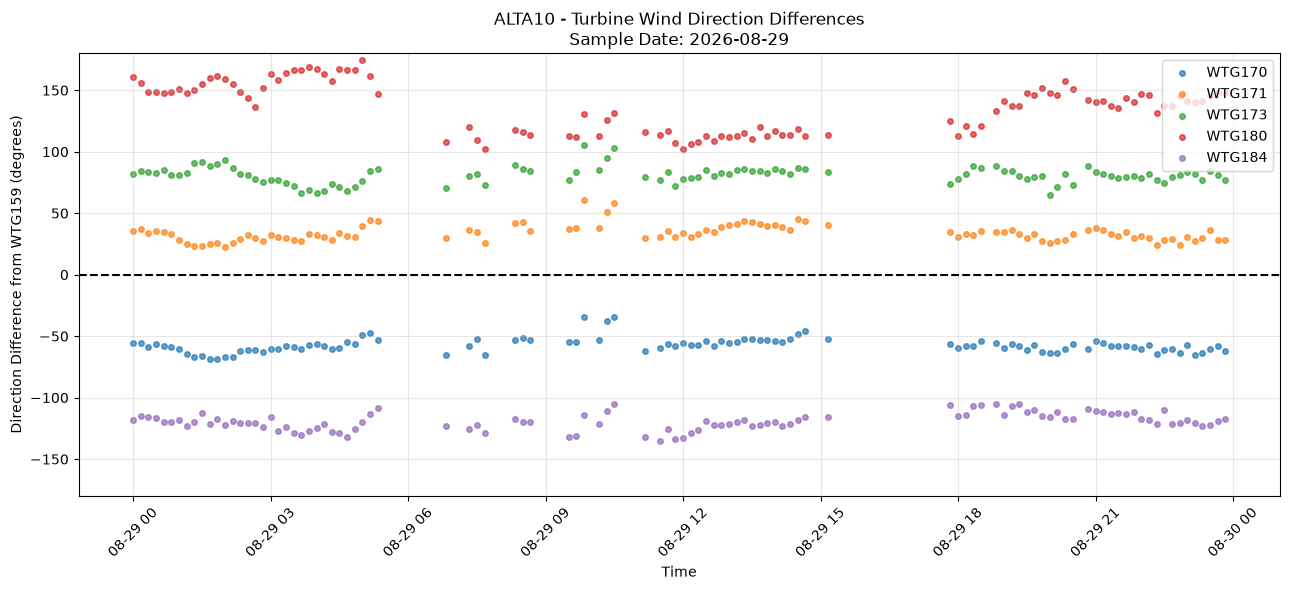

In [36]:
# ==============================================
# ALTA10 - TURBINE WIND DIRECTION OFFSET ANALYSIS
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reuse our simultaneous wind-direction measurements
directions = direction_pivot.copy()

reference_turbine = "WTG159"

# Circular angle difference (-180 to 180)
def angle_difference(a, b):
    return (a - b + 180) % 360 - 180

results = []
direction_offsets = pd.DataFrame(index=directions.index)

for turbine in directions.columns:

    # Direction difference relative to WTG159
    diff = angle_difference(
        directions[turbine],
        directions[reference_turbine]
    )

    direction_offsets[turbine] = diff

    # Circular mean difference
    radians = np.deg2rad(diff)

    mean_sin = np.mean(np.sin(radians))
    mean_cos = np.mean(np.cos(radians))

    mean_offset = np.degrees(
        np.arctan2(mean_sin, mean_cos)
    )

    # R close to 1 means differences are concentrated
    R = np.hypot(mean_sin, mean_cos)

    # Remaining disagreement after removing mean offset
    residual = angle_difference(diff, mean_offset)

    results.append({
        "turbine": turbine,
        "mean_offset_deg": mean_offset,
        "direction_consistency_R": R,
        "median_residual_deg": np.median(
            np.abs(residual)
        ),
        "observations": len(diff)
    })

offset_summary = pd.DataFrame(results)

print("ALTA10 - DIRECTION OFFSET SUMMARY")
display(offset_summary.round(3))

# ==============================================
# VISUALIZE DIFFERENCES ON A SAMPLE DAY
# ==============================================

# Select day with the most complete observations
day_counts = (
    direction_offsets.groupby(
        direction_offsets.index.normalize()
    ).size()
)

sample_day = day_counts.idxmax()

sample = direction_offsets.loc[
    direction_offsets.index.normalize() == sample_day
]

fig, ax = plt.subplots(figsize=(13, 6))

for turbine in directions.columns:

    if turbine != reference_turbine:

        ax.scatter(
            sample.index,
            sample[turbine],
            s=16,
            alpha=0.7,
            label=turbine
        )

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Time")
ax.set_ylabel("Direction Difference from WTG159 (degrees)")

ax.set_title(
    f"ALTA10 - Turbine Wind Direction Differences\n"
    f"Sample Date: {sample_day.date()}"
)

ax.set_ylim(-180, 180)
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

DAILY DIRECTION OFFSET SUMMARY:


C:\Users\alex-\AppData\Local\Temp\ipykernel_16024\409472971.py:66: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(daily_offsets.head(12).round(3))


,date,turbine,daily_offset_deg,daily_R,observations
0,2026-05-01,WTG170,176.068,0.998,17
1,2026-05-04,WTG170,175.755,0.997,21
2,2026-05-05,WTG170,-179.961,0.999,13
3,2026-05-07,WTG170,179.087,0.997,29
4,2026-05-08,WTG170,175.430,0.999,27
5,2026-05-10,WTG170,175.315,0.999,12
6,2026-05-11,WTG170,178.656,0.999,15
7,2026-05-12,WTG170,-178.575,0.998,12
8,2026-05-24,WTG170,81.767,0.998,12
9,2026-05-27,WTG170,-31.482,0.995,24


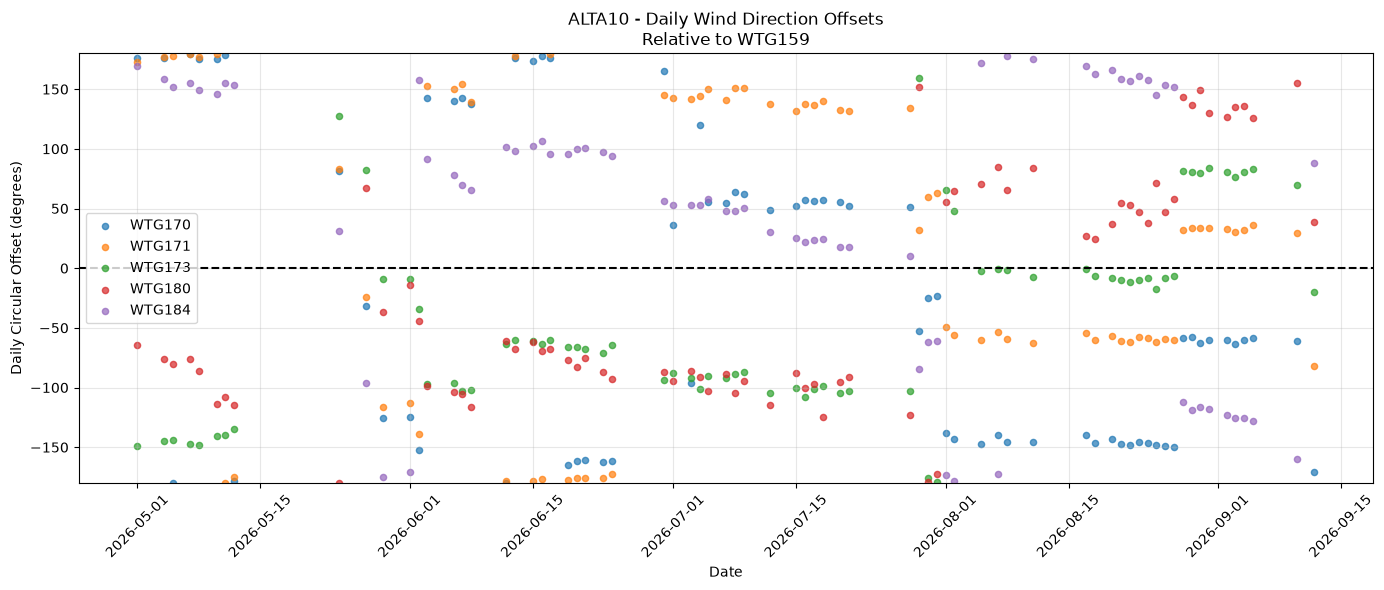

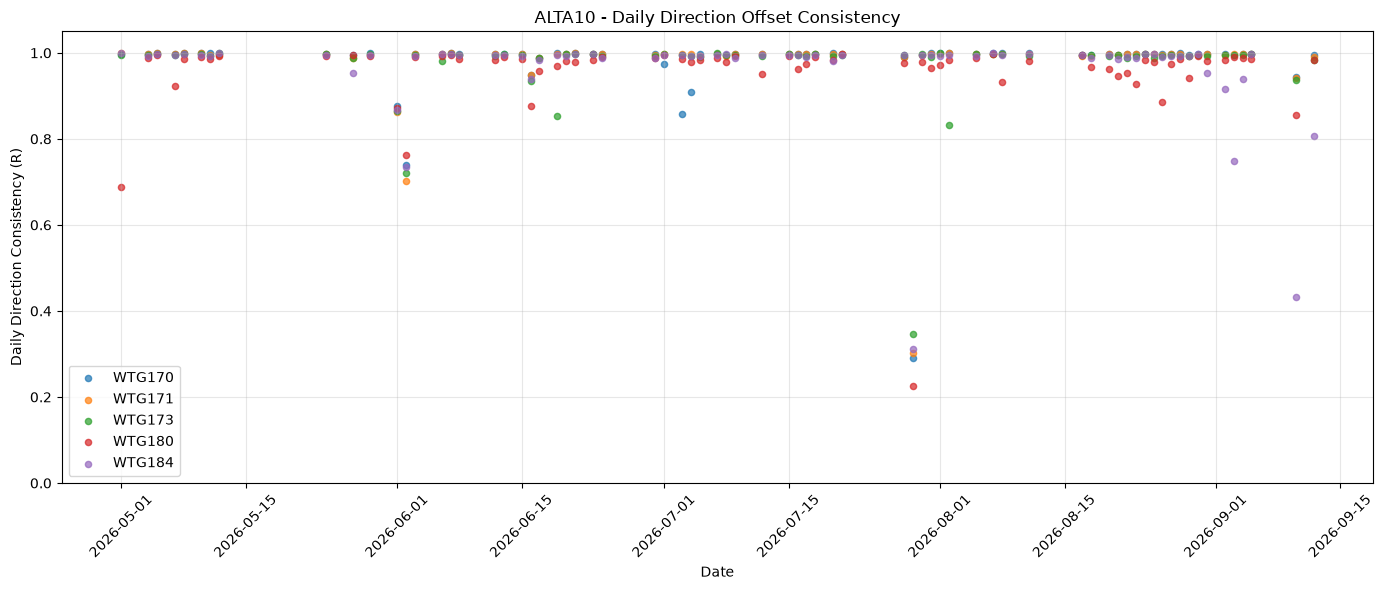

In [37]:
# ==============================================
# ALTA10 - DAILY WIND DIRECTION OFFSET ANALYSIS
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Previously created simultaneous direction data
directions = direction_pivot.copy()

reference_turbine = "WTG159"

def angular_difference(a, b):
    return (a - b + 180) % 360 - 180

daily_results = []

for turbine in directions.columns:

    if turbine == reference_turbine:
        continue

    differences = angular_difference(
        directions[turbine],
        directions[reference_turbine]
    )

    data = pd.DataFrame({
        "timestamp": directions.index,
        "difference": differences
    }).dropna()

    data["date"] = data["timestamp"].dt.normalize()

    for date, group in data.groupby("date"):

        # Require at least 12 common intervals
        if len(group) < 12:
            continue

        radians = np.deg2rad(group["difference"])

        mean_sin = np.mean(np.sin(radians))
        mean_cos = np.mean(np.cos(radians))

        # Daily circular mean difference
        mean_offset = np.degrees(
            np.arctan2(mean_sin, mean_cos)
        )

        # Daily directional consistency
        R = np.hypot(mean_sin, mean_cos)

        daily_results.append({
            "date": date,
            "turbine": turbine,
            "daily_offset_deg": mean_offset,
            "daily_R": R,
            "observations": len(group)
        })

daily_offsets = pd.DataFrame(daily_results)

print("DAILY DIRECTION OFFSET SUMMARY:")
display(daily_offsets.head(12).round(3))

# ==============================================
# PLOT 1 - DAILY DIRECTION OFFSETS
# ==============================================

fig, ax = plt.subplots(figsize=(14, 6))

for turbine, group in daily_offsets.groupby("turbine"):

    ax.scatter(
        group["date"],
        group["daily_offset_deg"],
        s=20,
        alpha=0.7,
        label=turbine
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_xlabel("Date")
ax.set_ylabel("Daily Circular Offset (degrees)")

ax.set_title(
    "ALTA10 - Daily Wind Direction Offsets\n"
    "Relative to WTG159"
)

ax.set_ylim(-180, 180)
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==============================================
# PLOT 2 - DAILY DIRECTION CONSISTENCY
# ==============================================

fig, ax = plt.subplots(figsize=(14, 6))

for turbine, group in daily_offsets.groupby("turbine"):

    ax.scatter(
        group["date"],
        group["daily_R"],
        s=20,
        alpha=0.7,
        label=turbine
    )

ax.set_xlabel("Date")
ax.set_ylabel("Daily Direction Consistency (R)")

ax.set_title(
    "ALTA10 - Daily Direction Offset Consistency"
)

ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
# ==============================================
# ALTA10 - WIND DIRECTION VS OPERATING STATE
# ==============================================

import pandas as pd
import numpy as np

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

reference = "WTG159"
min_power = 500  # kW; exploratory operating threshold

# ----------------------------------------------
# 1. LOAD ALL AVAILABLE SCADA OBSERVATIONS
# ----------------------------------------------

df = scada[
    scada["turbine"].astype(str).str.strip().isin(turbines)
].copy()

df["turbine"] = df["turbine"].astype(str).str.strip()

df["timestamp"] = pd.to_datetime(
    df["utc"], errors="coerce", utc=True
).dt.tz_localize(None)

cols = [
    "wind_direction",
    "wind_direction_relative",
    "nacelle_pos",
    "real_power_ac"
]

for col in cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["timestamp"])

if df.duplicated(["timestamp", "turbine"]).any():
    raise ValueError("Duplicate SCADA turbine/timestamp records.")

# ----------------------------------------------
# 2. CREATE MATCHED TURBINE MATRICES
# ----------------------------------------------

def make_matrix(column):
    return df.pivot(
        index="timestamp",
        columns="turbine",
        values=column
    ).reindex(columns=turbines)

direction = make_matrix("wind_direction")
nacelle = make_matrix("nacelle_pos")
relative = make_matrix("wind_direction_relative")
power = make_matrix("real_power_ac")

# Circular difference
def angle_diff(a, b):
    return (a - b + 180) % 360 - 180

# ----------------------------------------------
# 3. COMPARE OPERATING CONDITIONS
# ----------------------------------------------

results = []

for turbine in turbines:

    if turbine == reference:
        continue

    valid = (
        direction[turbine].notna() &
        direction[reference].notna()
    )

    both_generating = (
        (power[turbine] >= min_power) &
        (power[reference] >= min_power)
    )

    conditions = {
        "Both generating": valid & both_generating,
        "One/both below threshold": valid & ~both_generating
    }

    for condition, mask in conditions.items():

        if mask.sum() == 0:
            continue

        direction_diff = angle_diff(
            direction.loc[mask, turbine],
            direction.loc[mask, reference]
        )

        nacelle_diff = angle_diff(
            nacelle.loc[mask, turbine],
            nacelle.loc[mask, reference]
        )

        relative_diff = angle_diff(
            relative.loc[mask, turbine],
            relative.loc[mask, reference]
        )

        radians = np.deg2rad(direction_diff)

        R = np.hypot(
            np.mean(np.sin(radians)),
            np.mean(np.cos(radians))
        )

        results.append({
            "turbine": turbine,
            "condition": condition,
            "observations": int(mask.sum()),
            "median_direction_diff_deg":
                np.median(np.abs(direction_diff)),
            "median_nacelle_diff_deg":
                np.nanmedian(np.abs(nacelle_diff)),
            "median_relative_diff_deg":
                np.nanmedian(np.abs(relative_diff)),
            "direction_consistency_R": R,
            "within_20deg_pct":
                100 * np.mean(np.abs(direction_diff) <= 20)
        })

operating_summary = pd.DataFrame(results)

print("WIND DIRECTION VS TURBINE OPERATING STATE")
display(operating_summary.round(2))

print("\nTotal SCADA timestamps:", len(direction))

print(
    "Timestamps where all six produce at least 500 kW:",
    int((power >= min_power).all(axis=1).sum())
)

WIND DIRECTION VS TURBINE OPERATING STATE


,turbine,condition,observations,median_direction_diff_deg,median_nacelle_diff_deg,median_relative_diff_deg,direction_consistency_R,within_20deg_pct
0,WTG170,Both generating,11460,146.73,146.96,1.87,0.47,0.47
1,WTG170,One/both below threshold,25746,143.64,148.43,5.03,0.45,3.62
2,WTG171,Both generating,13608,142.49,141.64,2.48,0.36,0.59
3,WTG171,One/both below threshold,22793,139.07,143.00,5.39,0.36,3.76
4,WTG173,Both generating,11844,89.00,88.17,2.18,0.28,15.72
5,WTG173,One/both below threshold,25037,121.60,119.73,5.10,0.31,12.34
6,WTG180,Both generating,13176,85.83,86.25,2.07,0.33,5.19
7,WTG180,One/both below threshold,23966,95.50,94.10,4.97,0.34,6.95
8,WTG184,Both generating,12324,128.66,129.76,3.64,0.41,4.22
9,WTG184,One/both below threshold,24872,128.07,132.96,6.16,0.31,6.70



Total SCADA timestamps: 39018
Timestamps where all six produce at least 500 kW: 6383


In [39]:
# ==============================================
# ALTA10 - SIX TURBINE LIDAR VS SCADA COMPARISON
# ==============================================

import pandas as pd
import numpy as np

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

# Prepare LiDAR observations
lidar_compare = lidar_ti_all[
    lidar_ti_all["valid_interval"]
][
    ["timestamp", "turbine", "mean_speed", "TI"]
].copy()

lidar_compare = lidar_compare.rename(
    columns={"mean_speed": "lidar_speed"}
)

# Prepare SCADA observations
scada_compare = scada[
    ["utc", "turbine", "wind_speed", "real_power_ac"]
].copy()

scada_compare["timestamp"] = pd.to_datetime(
    scada_compare["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

scada_compare["turbine"] = (
    scada_compare["turbine"].astype(str).str.strip()
)

scada_compare = scada_compare.rename(
    columns={
        "wind_speed": "scada_speed",
        "real_power_ac": "power_kw"
    }
)

# Match timestamp and turbine
all_matched = lidar_compare.merge(
    scada_compare[
        ["timestamp", "turbine", "scada_speed", "power_kw"]
    ],
    on=["timestamp", "turbine"],
    how="inner",
    validate="one_to_one"
)

# Keep plausible measured wind speeds
all_matched = all_matched.dropna(
    subset=["lidar_speed", "scada_speed"]
)

all_matched = all_matched[
    all_matched["scada_speed"].between(0, 35)
].copy()

# Difference: SCADA minus LiDAR
all_matched["difference"] = (
    all_matched["scada_speed"] -
    all_matched["lidar_speed"]
)

# Summary
six_turbine_summary = (
    all_matched.groupby("turbine")
    .agg(
        observations=("difference", "count"),
        mean_lidar=("lidar_speed", "mean"),
        mean_scada=("scada_speed", "mean"),
        mean_difference=("difference", "mean"),
        median_difference=("difference", "median"),
        MAE=("difference", lambda x: x.abs().mean()),
        RMSE=("difference", lambda x: np.sqrt(np.mean(x**2)))
    )
    .reset_index()
)

display(six_turbine_summary.round(4))

print("Total matched intervals:", len(all_matched))

,turbine,observations,mean_lidar,mean_scada,mean_difference,median_difference,MAE,RMSE
0,WTG159,15018,10.2949,12.0048,1.7099,1.3102,1.7517,2.8113
1,WTG170,14791,9.3586,9.8967,0.5381,0.4726,0.6200,0.9389
2,WTG171,14782,8.8268,9.2145,0.3877,0.4680,0.6584,0.8300
3,WTG173,14480,8.9681,9.2742,0.3061,0.1945,0.5934,1.1476
4,WTG180,15188,10.7598,10.6515,-0.1083,-0.0317,0.5094,0.7262
5,WTG184,14675,8.8604,9.3711,0.5108,0.5126,0.6378,0.7828


Total matched intervals: 88934


MONTHLY WIND SPEED DIFFERENCES:


,turbine,month,observations,mean_difference,median_difference,difference_std
0,WTG159,2026-05,3009,2.068,1.335,3.055
1,WTG159,2026-06,3679,2.464,1.505,3.066
2,WTG159,2026-07,2968,1.393,1.313,0.932
3,WTG159,2026-08,3613,1.117,1.202,0.888
4,WTG159,2026-09,1749,1.271,1.179,1.156
5,WTG170,2026-05,3094,0.602,0.407,0.811
6,WTG170,2026-06,3482,0.522,0.441,1.051
7,WTG170,2026-07,2775,0.663,0.565,0.750
8,WTG170,2026-08,3748,0.453,0.494,0.365
9,WTG170,2026-09,1692,0.439,0.448,0.650


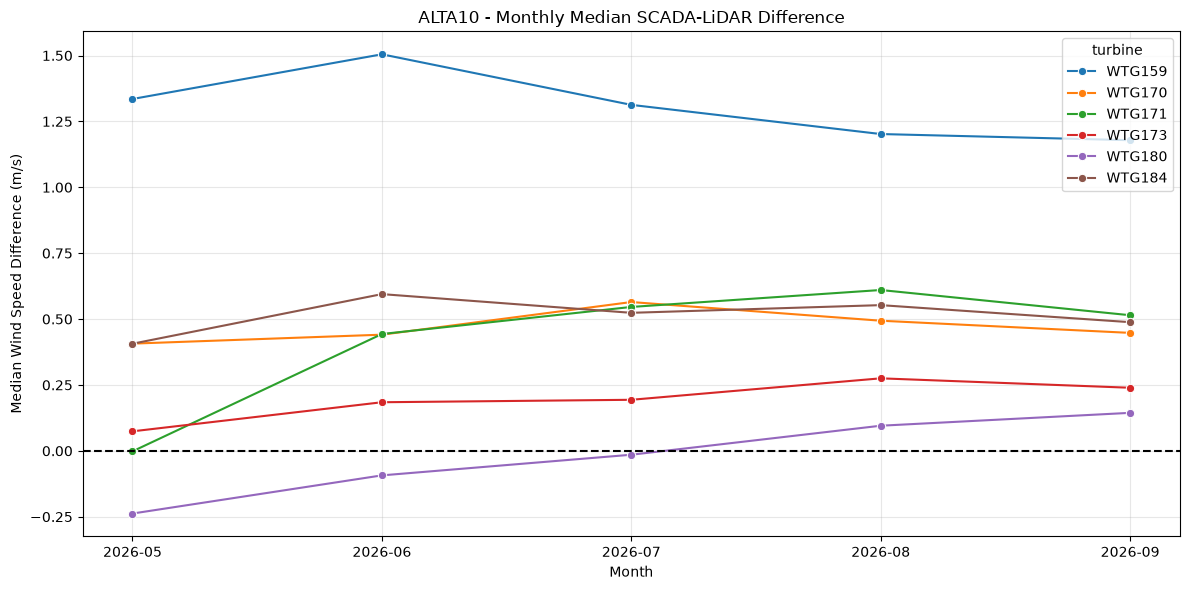

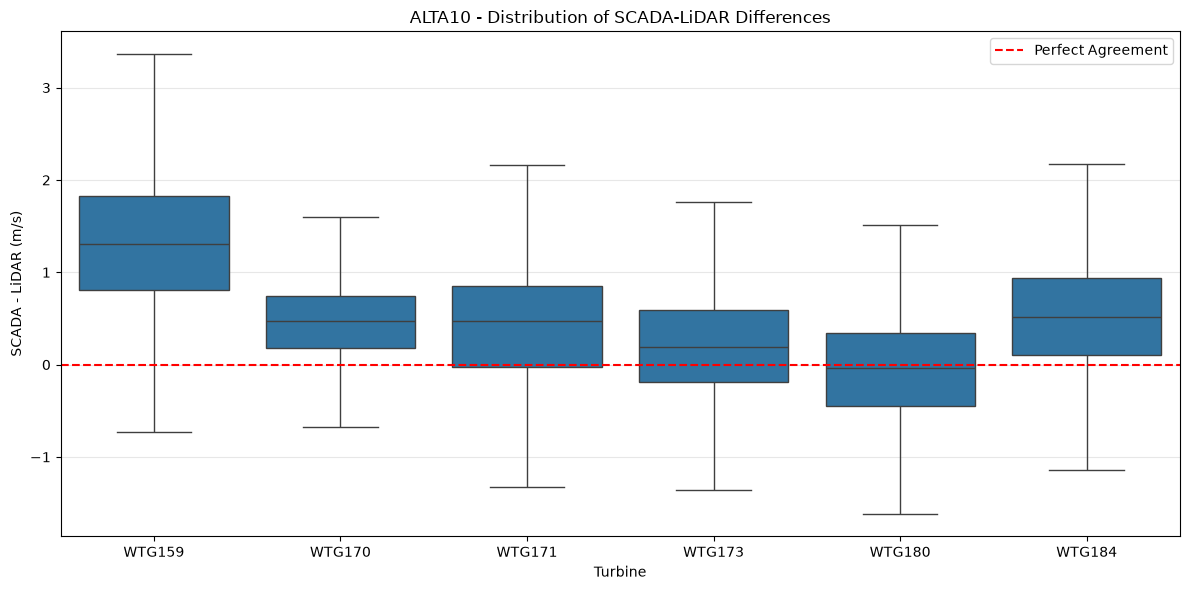


WTG159 DIFFERENCE DISTRIBUTION:


count    15018.000
mean         1.710
std          2.232
min         -2.944
1%          -0.584
5%          -0.081
25%          0.806
50%          1.310
75%          1.828
95%          4.757
99%         12.043
max         31.694
Name: difference, dtype: float64


WTG159 - 10 LARGEST ABSOLUTE DIFFERENCES:


C:\Users\alex-\AppData\Local\Temp\ipykernel_16024\2581736338.py:137: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,timestamp,lidar_speed,scada_speed,difference,power_kw
1678,2026-05-17 00:00:00,3.181,34.875,31.694,NaN
1679,2026-05-17 00:10:00,3.197,34.464,31.267,NaN
1680,2026-05-17 00:20:00,3.640,34.352,30.712,NaN
1699,2026-05-17 03:30:00,3.862,33.394,29.531,NaN
1684,2026-05-17 01:00:00,5.200,34.532,29.332,NaN
1677,2026-05-16 23:50:00,3.529,32.777,29.248,NaN
1687,2026-05-17 01:30:00,4.370,33.272,28.902,NaN
1698,2026-05-17 03:20:00,5.268,34.084,28.816,NaN
1676,2026-05-16 23:40:00,3.444,31.962,28.519,NaN
1693,2026-05-17 02:30:00,4.705,32.959,28.255,NaN


In [40]:
# ==============================================
# ALTA10 - LIDAR VS SCADA BIAS EXPLORATION
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use the matched LiDAR and SCADA dataset
bias_data = all_matched.copy()

bias_data["timestamp"] = pd.to_datetime(
    bias_data["timestamp"]
)

# SCADA minus LiDAR
bias_data["difference"] = (
    bias_data["scada_speed"] -
    bias_data["lidar_speed"]
)

# Create month variable
bias_data["month"] = (
    bias_data["timestamp"].dt.to_period("M").astype(str)
)

# ==============================================
# 1. MONTHLY SUMMARY
# ==============================================

monthly_summary = (
    bias_data.groupby(["turbine", "month"])
    .agg(
        observations=("difference", "count"),
        mean_difference=("difference", "mean"),
        median_difference=("difference", "median"),
        difference_std=("difference", "std")
    )
    .reset_index()
)

print("MONTHLY WIND SPEED DIFFERENCES:")
display(monthly_summary.round(3))

# ==============================================
# 2. MONTHLY MEDIAN COMPARISON
# ==============================================

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="median_difference",
    hue="turbine",
    marker="o"
)

plt.axhline(
    0, color="black", linestyle="--"
)

plt.title(
    "ALTA10 - Monthly Median SCADA-LiDAR Difference"
)

plt.xlabel("Month")
plt.ylabel("Median Wind Speed Difference (m/s)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==============================================
# 3. DIFFERENCE DISTRIBUTION BY TURBINE
# ==============================================

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=bias_data,
    x="turbine",
    y="difference",
    showfliers=False
)

plt.axhline(
    0, color="red", linestyle="--",
    label="Perfect Agreement"
)

plt.title(
    "ALTA10 - Distribution of SCADA-LiDAR Differences"
)

plt.xlabel("Turbine")
plt.ylabel("SCADA - LiDAR (m/s)")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ==============================================
# 4. INVESTIGATE EXTREME WTG159 DIFFERENCES
# ==============================================

wtg159 = bias_data[
    bias_data["turbine"] == "WTG159"
].copy()

print("\nWTG159 DIFFERENCE DISTRIBUTION:")
display(
    wtg159["difference"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.5,
                     0.75, 0.95, 0.99]
    ).round(3)
)

print("\nWTG159 - 10 LARGEST ABSOLUTE DIFFERENCES:")

extreme = wtg159.assign(
    absolute_difference=wtg159["difference"].abs()
).nlargest(10, "absolute_difference")

display(
    extreme[
        [
            "timestamp",
            "lidar_speed",
            "scada_speed",
            "difference",
            "power_kw"
        ]
    ].round(3)
)

SCADA QUALITY FLAGS BY TURBINE:


,turbine,total_intervals,above_cutout,missing_power,large_disagreement,generation_screened
0,WTG159,15018,293,2879,667,11602
1,WTG170,14791,5,1398,38,12882
2,WTG171,14782,2,1277,20,13070
3,WTG173,14480,19,1435,113,12612
4,WTG180,15188,42,275,14,14271
5,WTG184,14675,1,384,3,13665



ORIGINAL VS GENERATION-SCREENED:


,turbine,sample,observations,mean_difference,median_difference,RMSE
0,WTG159,All observations,15018,1.710,1.310,2.811
1,WTG159,Generation-screened,11602,1.207,1.216,1.394
2,WTG170,All observations,14791,0.538,0.473,0.939
3,WTG170,Generation-screened,12882,0.407,0.446,0.574
4,WTG171,All observations,14782,0.388,0.468,0.830
5,WTG171,Generation-screened,13070,0.492,0.545,0.749
6,WTG173,All observations,14480,0.306,0.195,1.148
7,WTG173,Generation-screened,12612,0.140,0.157,0.550
8,WTG180,All observations,15188,-0.108,-0.032,0.726
9,WTG180,Generation-screened,14271,-0.064,0.006,0.657



WTG159 - LARGEST DISCREPANCIES:


C:\Users\alex-\AppData\Local\Temp\ipykernel_16024\2484832780.py:113: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(20).round(3)


,timestamp,lidar_speed,scada_speed,power_kw,difference,above_cutout,missing_power
1678,2026-05-17 00:00:00,3.181,34.875,NaN,31.694,True,True
1679,2026-05-17 00:10:00,3.197,34.464,NaN,31.267,True,True
1680,2026-05-17 00:20:00,3.640,34.352,NaN,30.712,True,True
1699,2026-05-17 03:30:00,3.862,33.394,NaN,29.531,True,True
1684,2026-05-17 01:00:00,5.200,34.532,NaN,29.332,True,True
1677,2026-05-16 23:50:00,3.529,32.777,NaN,29.248,True,True
1687,2026-05-17 01:30:00,4.370,33.272,NaN,28.902,True,True
1698,2026-05-17 03:20:00,5.268,34.084,NaN,28.816,True,True
1676,2026-05-16 23:40:00,3.444,31.962,NaN,28.519,True,True
1693,2026-05-17 02:30:00,4.705,32.959,NaN,28.255,True,True


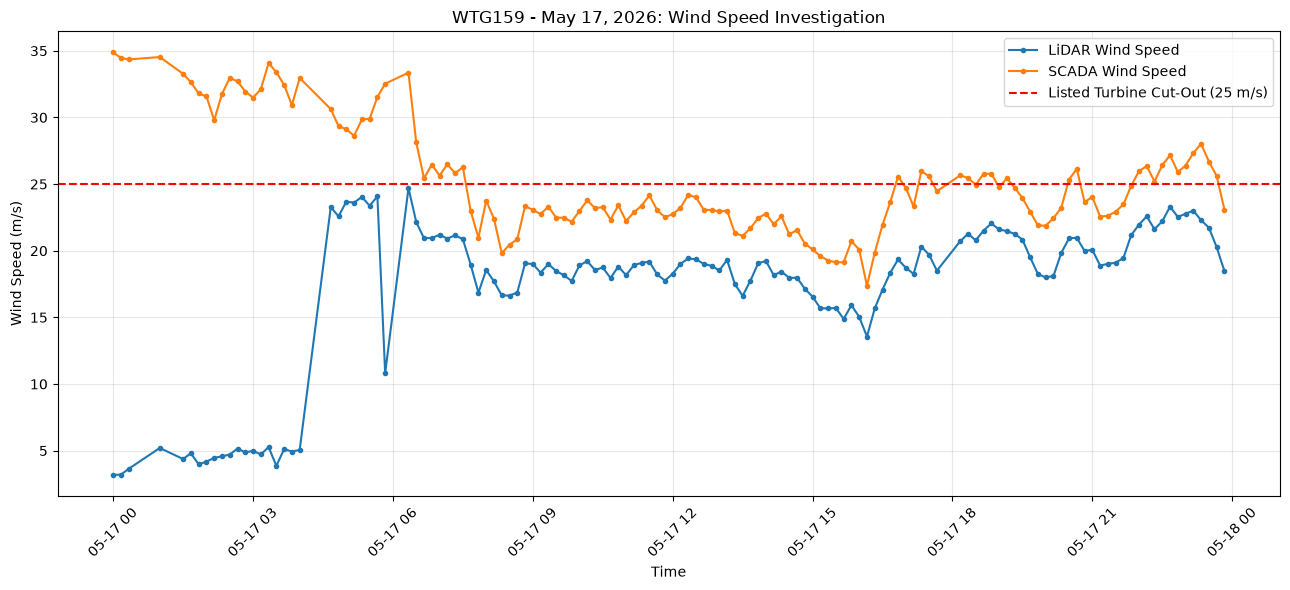

In [41]:
# ==============================================
# ALTA10 - SCADA / LIDAR QUALITY INVESTIGATION
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

qc = all_matched.copy()

qc["difference"] = (
    qc["scada_speed"] - qc["lidar_speed"]
)

# ----------------------------------------------
# 1. FLAG SUSPICIOUS CONDITIONS
# ----------------------------------------------

qc["above_cutout"] = qc["scada_speed"] >= 25

qc["missing_power"] = qc["power_kw"].isna()

qc["large_disagreement"] = (
    qc["difference"].abs() > 5
)

# Exploratory generation screen:
# not a verified normal-operation classification
qc["generation_screened"] = (
    qc["scada_speed"].ge(4) &
    qc["scada_speed"].lt(25) &
    qc["lidar_speed"].between(3, 25) &
    qc["power_kw"].between(100, 2850 * 1.05)
)

# ----------------------------------------------
# 2. COUNT FLAGS BY TURBINE
# ----------------------------------------------

quality_summary = (
    qc.groupby("turbine")
    .agg(
        total_intervals=("difference", "size"),
        above_cutout=("above_cutout", "sum"),
        missing_power=("missing_power", "sum"),
        large_disagreement=("large_disagreement", "sum"),
        generation_screened=("generation_screened", "sum")
    )
    .reset_index()
)

print("SCADA QUALITY FLAGS BY TURBINE:")
display(quality_summary)

# ----------------------------------------------
# 3. COMPARE ORIGINAL VS SCREENED DIFFERENCES
# ----------------------------------------------

results = []

for turbine, group in qc.groupby("turbine"):

    subsets = {
        "All observations": group,
        "Generation-screened": group[
            group["generation_screened"]
        ]
    }

    for subset_name, sample in subsets.items():

        d = sample["difference"].dropna()

        if len(d) == 0:
            continue

        results.append({
            "turbine": turbine,
            "sample": subset_name,
            "observations": len(d),
            "mean_difference": d.mean(),
            "median_difference": d.median(),
            "RMSE": np.sqrt(np.mean(d**2))
        })

screened_summary = pd.DataFrame(results)

print("\nORIGINAL VS GENERATION-SCREENED:")
display(screened_summary.round(3))

# ----------------------------------------------
# 4. INVESTIGATE WTG159 EXTREME OBSERVATIONS
# ----------------------------------------------

wtg159_qc = qc[qc["turbine"] == "WTG159"].copy()

flagged = wtg159_qc[
    wtg159_qc["large_disagreement"]
].sort_values("difference", ascending=False)

print("\nWTG159 - LARGEST DISCREPANCIES:")
display(
    flagged[
        [
            "timestamp",
            "lidar_speed",
            "scada_speed",
            "power_kw",
            "difference",
            "above_cutout",
            "missing_power"
        ]
    ].head(20).round(3)
)

# ----------------------------------------------
# 5. PLOT MAY 17 ANOMALIES
# ----------------------------------------------

may17 = wtg159_qc[
    wtg159_qc["timestamp"].dt.date ==
    pd.Timestamp("2026-05-17").date()
].sort_values("timestamp")

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    may17["timestamp"],
    may17["lidar_speed"],
    marker=".",
    label="LiDAR Wind Speed"
)

ax.plot(
    may17["timestamp"],
    may17["scada_speed"],
    marker=".",
    label="SCADA Wind Speed"
)

ax.axhline(
    25,
    color="red",
    linestyle="--",
    label="Listed Turbine Cut-Out (25 m/s)"
)

ax.set_title(
    "WTG159 - May 17, 2026: Wind Speed Investigation"
)

ax.set_xlabel("Time")
ax.set_ylabel("Wind Speed (m/s)")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

MAY 17 WIND SPEED COMPARISON:


,WTG158,WTG159,WTG170,WTG171,lidar_speed,power_kw
timestamp,,,,,,
2026-05-16 21:00:00,20.706,22.775,13.508,14.946,NaN,NaN
2026-05-16 21:10:00,22.740,26.194,14.086,15.100,NaN,NaN
2026-05-16 21:20:00,26.949,30.209,15.722,18.443,NaN,NaN
2026-05-16 21:30:00,26.655,31.341,18.680,20.738,NaN,NaN
2026-05-16 21:40:00,28.294,32.423,19.409,19.102,NaN,NaN
2026-05-16 21:50:00,29.726,33.305,17.926,21.315,NaN,NaN
2026-05-16 22:00:00,28.786,32.200,17.596,24.892,5.240,NaN
2026-05-16 22:10:00,28.839,32.895,18.949,23.000,5.339,NaN
2026-05-16 22:20:00,29.013,33.129,17.958,23.846,5.355,NaN


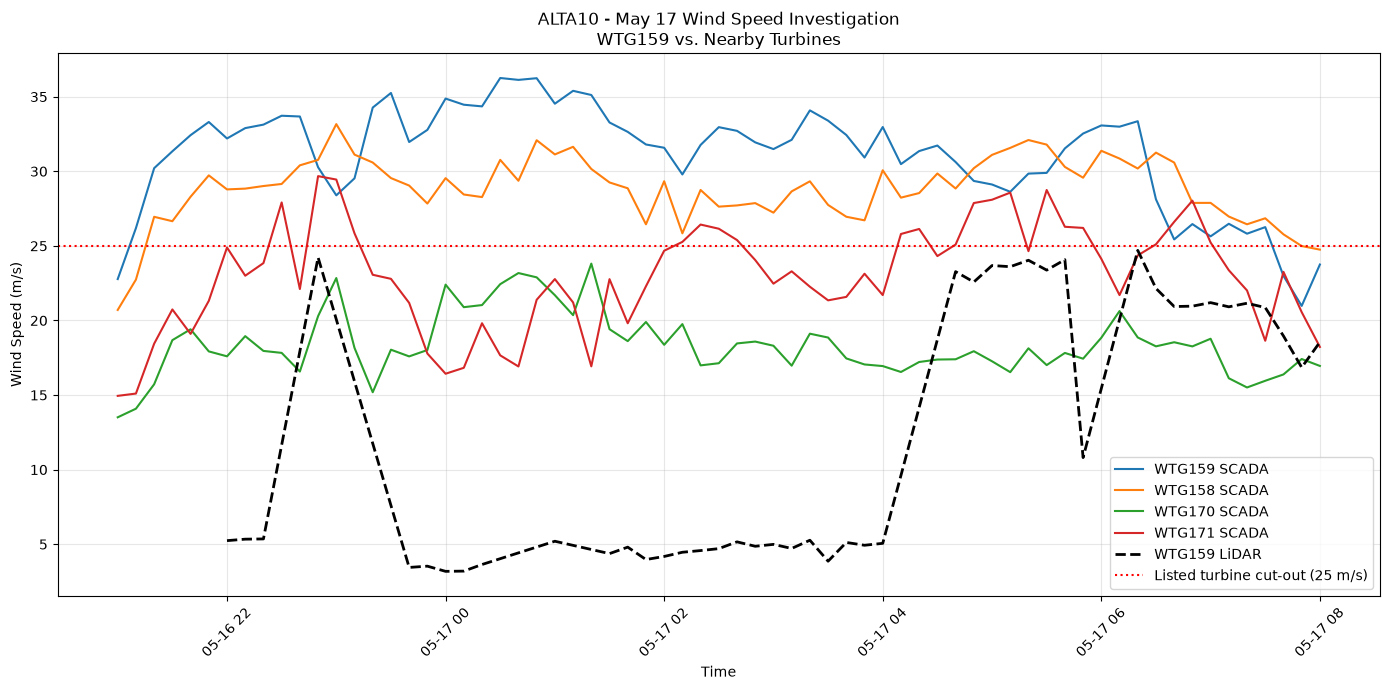

In [42]:
# ==============================================
# ALTA10 - MAY 17 WIND SPEED INVESTIGATION
# ==============================================

import pandas as pd
import matplotlib.pyplot as plt

# Select neighboring turbines for comparison
selected_turbines = [
    "WTG159",
    "WTG158",
    "WTG170",
    "WTG171"
]

# Prepare SCADA observations
neighbor_data = scada[
    scada["turbine"].astype(str).str.strip().isin(
        selected_turbines
    )
][
    ["utc", "turbine", "wind_speed", "real_power_ac"]
].copy()

neighbor_data["timestamp"] = pd.to_datetime(
    neighbor_data["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

neighbor_data["turbine"] = (
    neighbor_data["turbine"].astype(str).str.strip()
)

# Restrict to the event
start = pd.Timestamp("2026-05-16 21:00:00")
end = pd.Timestamp("2026-05-17 08:00:00")

neighbor_data = neighbor_data[
    neighbor_data["timestamp"].between(start, end)
].copy()

# Pivot into one column per turbine
neighbor_pivot = neighbor_data.pivot_table(
    index="timestamp",
    columns="turbine",
    values="wind_speed",
    aggfunc="mean"
)

# WTG159 LiDAR observations from existing dataset
lidar_event = all_matched[
    (all_matched["turbine"] == "WTG159") &
    (all_matched["timestamp"].between(start, end))
].copy()

# Display simultaneous measurements
event_table = neighbor_pivot.join(
    lidar_event.set_index("timestamp")[
        ["lidar_speed", "power_kw"]
    ],
    how="outer"
).sort_index()

print("MAY 17 WIND SPEED COMPARISON:")
display(event_table.round(3).head(30))

# Create time-series comparison
fig, ax = plt.subplots(figsize=(14, 7))

for turbine in selected_turbines:
    if turbine in neighbor_pivot.columns:
        ax.plot(
            neighbor_pivot.index,
            neighbor_pivot[turbine],
            label=f"{turbine} SCADA",
            linewidth=1.5
        )

ax.plot(
    lidar_event["timestamp"],
    lidar_event["lidar_speed"],
    color="black",
    linestyle="--",
    linewidth=2,
    label="WTG159 LiDAR"
)

ax.axhline(
    25,
    color="red",
    linestyle=":",
    label="Listed turbine cut-out (25 m/s)"
)

ax.set_title(
    "ALTA10 - May 17 Wind Speed Investigation\n"
    "WTG159 vs. Nearby Turbines"
)

ax.set_xlabel("Time")
ax.set_ylabel("Wind Speed (m/s)")

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

MEASUREMENT MODES:
mode
0    20346
1    19255
Name: count, dtype: int64

EXTREME DISAGREEMENT INTERVALS:


,lidar_mean,sensor1_mean,wtg1_mean,scada_speed,coverage_pct,mode1_fraction
timestamp,,,,,,
2026-05-16 22:00:00,5.240,27.590,NaN,32.200,97.000,0.000
2026-05-16 22:10:00,5.339,28.083,NaN,32.895,99.667,0.000
2026-05-16 22:20:00,5.355,28.260,NaN,33.129,99.833,0.000
2026-05-16 22:30:00,5.319,28.857,NaN,33.725,32.333,0.000
2026-05-16 23:20:00,5.235,29.287,29.287,34.271,68.000,1.000
2026-05-16 23:30:00,4.504,30.120,30.118,35.251,99.167,0.997
2026-05-16 23:40:00,3.444,27.263,27.263,31.962,99.333,1.000
2026-05-16 23:50:00,3.529,28.036,28.036,32.777,97.500,1.000
2026-05-17 00:00:00,3.181,29.817,30.173,34.875,99.167,0.100


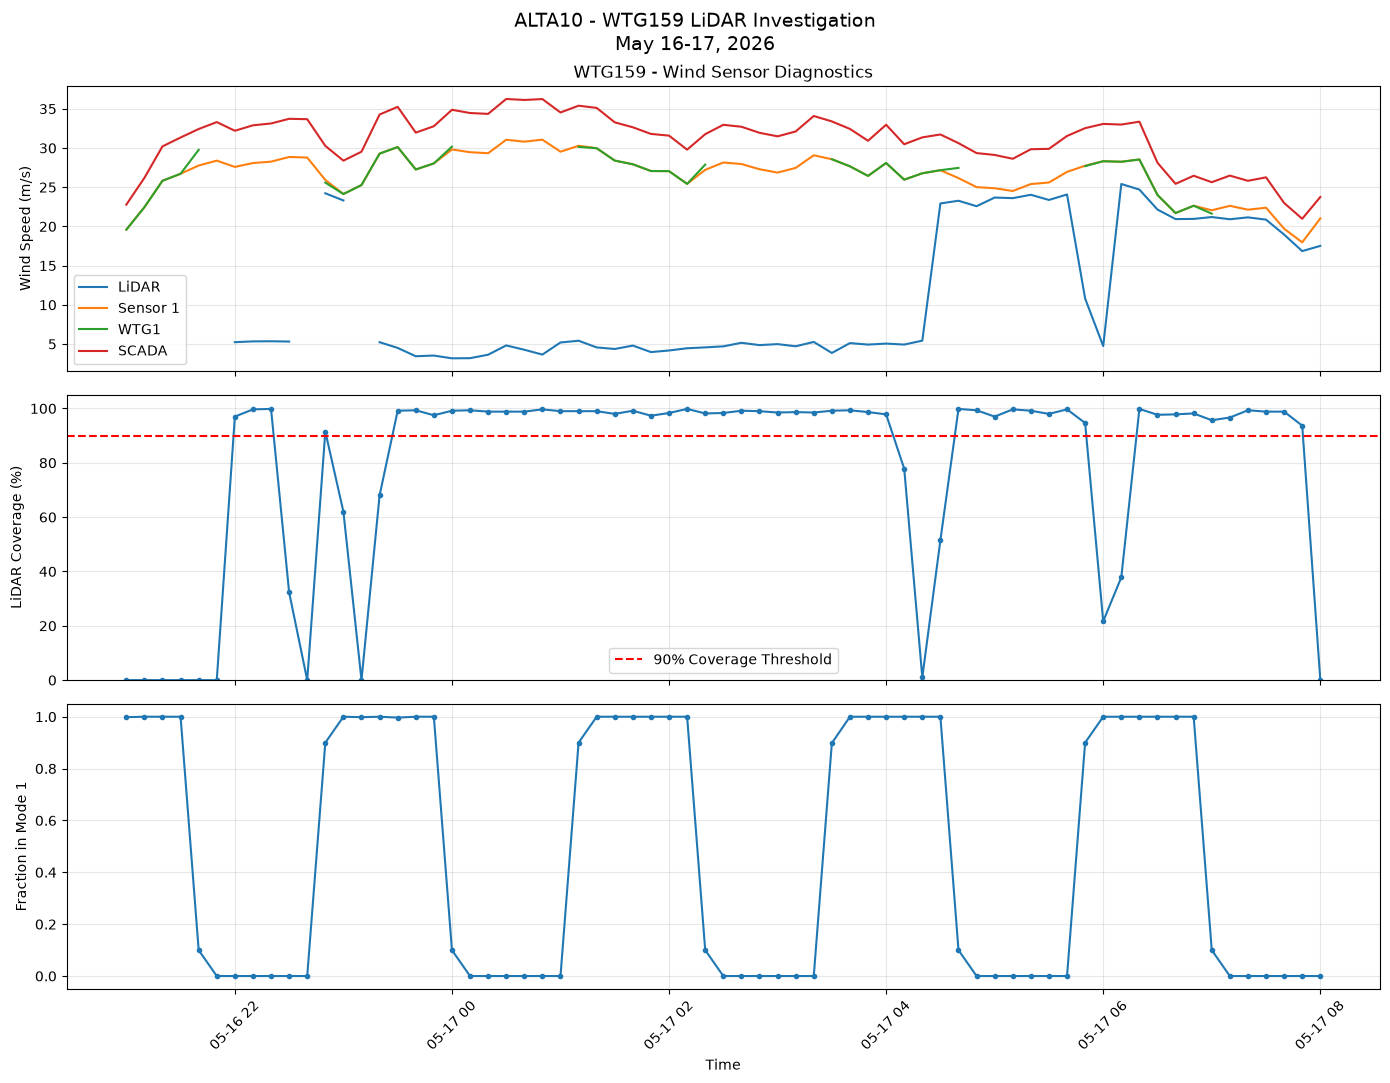

In [43]:
# ==============================================
# WTG159 - LIDAR INSTRUMENT DIAGNOSTICS
# MAY 16-17, 2026
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

folder = project_path / "data/raw/lidar_data/WTG_T159"

# Load both days at 1-second resolution
files = [
    folder / "2026-05-16.csv",
    folder / "2026-05-17.csv"
]

raw = pd.concat(
    [pd.read_csv(f, parse_dates=["timestamp"]) for f in files],
    ignore_index=True
)

raw = raw.sort_values("timestamp")

# Examine the event window
start = pd.Timestamp("2026-05-16 21:00")
end = pd.Timestamp("2026-05-17 08:00")

raw = raw[raw["timestamp"].between(start, end)].copy()

# Convert measurement columns
speed_cols = [
    "lidar_wsp", "sensor1_wsp",
    "wtg1_wsp", "Vlos1", "Vlos2"
]

for col in speed_cols:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")

# Exploratory plausible range; preserve original data
raw["lidar_usable"] = raw["lidar_wsp"].where(
    raw["lidar_wsp"].between(0, 50)
)

raw["mode1"] = raw["mode"].eq(1).astype(float)

# ==============================================
# AGGREGATE INTO 10-MINUTE INTERVALS
# ==============================================

diagnostic = (
    raw.set_index("timestamp")
    .resample("10min")
    .agg(
        lidar_mean=("lidar_usable", "mean"),
        sensor1_mean=("sensor1_wsp", "mean"),
        wtg1_mean=("wtg1_wsp", "mean"),
        lidar_count=("lidar_usable", "count"),
        total_records=("mode", "size"),
        mode1_fraction=("mode1", "mean")
    )
)

diagnostic["coverage_pct"] = (
    diagnostic["lidar_count"] / 600 * 100
)

# Add WTG159 SCADA observations
scada_event = scada[
    scada["turbine"].astype(str).str.strip() == "WTG159"
][["utc", "wind_speed"]].copy()

scada_event["timestamp"] = pd.to_datetime(
    scada_event["utc"], errors="coerce", utc=True
).dt.tz_localize(None)

scada_event = scada_event.set_index("timestamp")

if scada_event.index.duplicated().any():
    raise ValueError("Duplicate SCADA timestamps found.")

diagnostic = diagnostic.join(
    scada_event["wind_speed"].rename("scada_speed"),
    how="left"
)

# ==============================================
# FLAG EXTREME DISAGREEMENTS
# ==============================================

diagnostic["extreme_disagreement"] = (
    (diagnostic["lidar_mean"] < 8) &
    (diagnostic["scada_speed"] > 25)
)

print("MEASUREMENT MODES:")
print(raw["mode"].value_counts(dropna=False))

print("\nEXTREME DISAGREEMENT INTERVALS:")

display(
    diagnostic.loc[
        diagnostic["extreme_disagreement"],
        [
            "lidar_mean", "sensor1_mean",
            "wtg1_mean", "scada_speed",
            "coverage_pct", "mode1_fraction"
        ]
    ].round(3)
)

# ==============================================
# VISUALIZE INSTRUMENT BEHAVIOR
# ==============================================

fig, axes = plt.subplots(
    3, 1, figsize=(14, 11), sharex=True
)

# Graph 1: Wind measurements
for col, label in [
    ("lidar_mean", "LiDAR"),
    ("sensor1_mean", "Sensor 1"),
    ("wtg1_mean", "WTG1"),
    ("scada_speed", "SCADA")
]:
    axes[0].plot(
        diagnostic.index,
        diagnostic[col],
        label=label
    )

axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].set_title("WTG159 - Wind Sensor Diagnostics")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graph 2: LiDAR valid measurement coverage
axes[1].plot(
    diagnostic.index,
    diagnostic["coverage_pct"],
    marker="."
)

axes[1].axhline(
    90, color="red", linestyle="--",
    label="90% Coverage Threshold"
)

axes[1].set_ylabel("LiDAR Coverage (%)")
axes[1].set_ylim(0, 105)
axes[1].legend()
axes[1].grid(alpha=0.3)

# Graph 3: Proportion of Mode 1 measurements
axes[2].plot(
    diagnostic.index,
    diagnostic["mode1_fraction"],
    marker="."
)

axes[2].set_ylabel("Fraction in Mode 1")
axes[2].set_xlabel("Time")
axes[2].set_ylim(-0.05, 1.05)
axes[2].grid(alpha=0.3)

plt.suptitle(
    "ALTA10 - WTG159 LiDAR Investigation\n"
    "May 16-17, 2026",
    fontsize=14
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

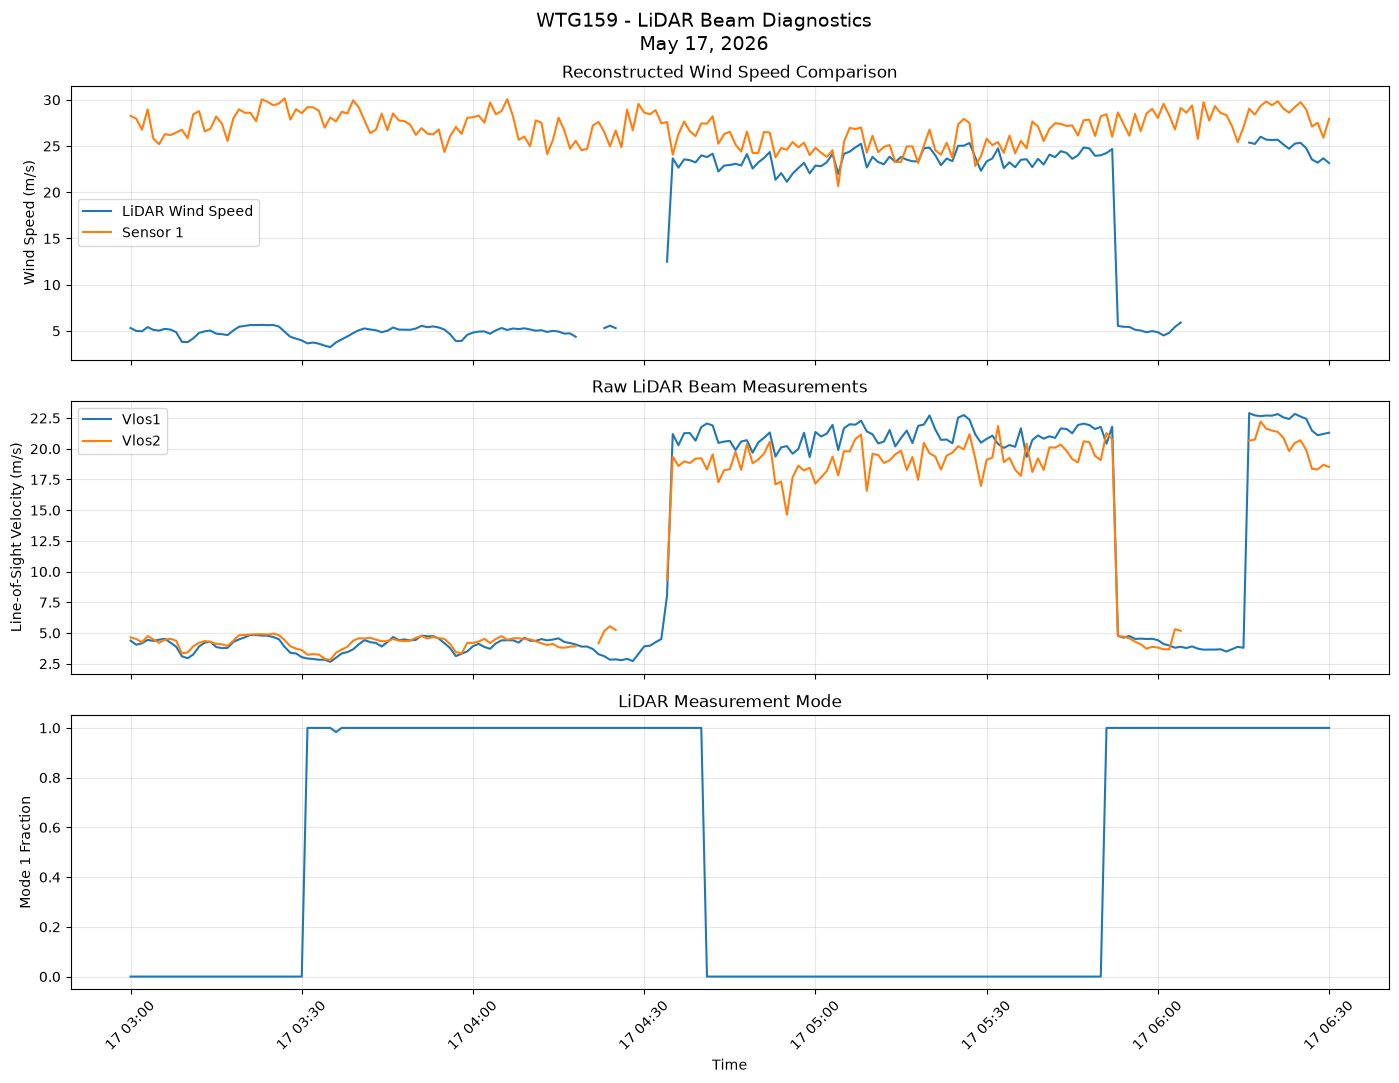

In [44]:
# ==============================================
# WTG159 - RAW LIDAR BEAM INVESTIGATION
# May 17, 2026
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reuse the raw LiDAR data loaded earlier
beam_data = raw.copy()

beam_data["timestamp"] = pd.to_datetime(
    beam_data["timestamp"]
)

# Focus on the unusual transition
start = "2026-05-17 03:00:00"
end = "2026-05-17 06:30:00"

beam_data = beam_data[
    beam_data["timestamp"].between(start, end)
].copy()

# Convert measurement columns to numeric
columns = [
    "lidar_wsp",
    "sensor1_wsp",
    "Vlos1",
    "Vlos2",
    "mode"
]

for col in columns:
    beam_data[col] = pd.to_numeric(
        beam_data[col],
        errors="coerce"
    )

# ==============================================
# AGGREGATE TO 1-MINUTE INTERVALS
# ==============================================

beam_data["mode1"] = (
    beam_data["mode"] == 1
).astype(float)

beam_minute = (
    beam_data.set_index("timestamp")
    .resample("1min")
    .agg(
        lidar=("lidar_wsp", "mean"),
        sensor=("sensor1_wsp", "mean"),
        vlos1=("Vlos1", "mean"),
        vlos2=("Vlos2", "mean"),
        mode1_fraction=("mode1", "mean")
    )
)

# ==============================================
# CREATE DIAGNOSTIC GRAPH
# ==============================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

# Graph 1: Reconstructed wind speeds
axes[0].plot(
    beam_minute.index,
    beam_minute["lidar"],
    label="LiDAR Wind Speed"
)

axes[0].plot(
    beam_minute.index,
    beam_minute["sensor"],
    label="Sensor 1"
)

axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].set_title("Reconstructed Wind Speed Comparison")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graph 2: Line-of-sight velocities
axes[1].plot(
    beam_minute.index,
    beam_minute["vlos1"],
    label="Vlos1"
)

axes[1].plot(
    beam_minute.index,
    beam_minute["vlos2"],
    label="Vlos2"
)

axes[1].set_ylabel("Line-of-Sight Velocity (m/s)")
axes[1].set_title("Raw LiDAR Beam Measurements")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Graph 3: Instrument mode
axes[2].plot(
    beam_minute.index,
    beam_minute["mode1_fraction"]
)

axes[2].set_ylabel("Mode 1 Fraction")
axes[2].set_xlabel("Time")
axes[2].set_ylim(-0.05, 1.05)
axes[2].set_title("LiDAR Measurement Mode")
axes[2].grid(alpha=0.3)

plt.suptitle(
    "WTG159 - LiDAR Beam Diagnostics\n"
    "May 17, 2026",
    fontsize=14
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [45]:
# ==========================================
# WTG159 - LIDAR STATE INVESTIGATION
# ==========================================

import pandas as pd
import numpy as np

state_data = raw.copy()

# Convert columns to numeric
cols = [
    "lidar_wsp",
    "sensor1_wsp",
    "Vlos1",
    "Vlos2",
    "mode"
]

for col in cols:
    state_data[col] = pd.to_numeric(
        state_data[col], errors="coerce"
    )

# Keep simultaneous, nonmissing wind measurements
state_data = state_data.dropna(
    subset=["lidar_wsp", "sensor1_wsp", "mode"]
).copy()

# Difference between instruments
state_data["difference"] = (
    state_data["sensor1_wsp"] -
    state_data["lidar_wsp"]
)

# Exploratory discrepancy flag
# Not a confirmed instrument fault classification
state_data["suspicious"] = (
    (state_data["sensor1_wsp"] > 20) &
    (state_data["lidar_wsp"] < 8)
)

# Summary by measurement mode
mode_diagnostics = (
    state_data.groupby("mode")
    .agg(
        observations=("difference", "count"),
        mean_lidar=("lidar_wsp", "mean"),
        mean_sensor=("sensor1_wsp", "mean"),
        median_difference=("difference", "median"),
        suspicious_count=("suspicious", "sum"),
        suspicious_pct=("suspicious", lambda x: x.mean() * 100),
        vlos1_available=("Vlos1", lambda x: x.notna().mean() * 100),
        vlos2_available=("Vlos2", lambda x: x.notna().mean() * 100)
    )
)

print("LIDAR MEASUREMENT STATE ANALYSIS")
display(mode_diagnostics.round(3))

# Compare the low and high LiDAR states
state_data["state"] = np.where(
    state_data["suspicious"],
    "Large low-LiDAR discrepancy",
    "Other observations"
)

state_summary = (
    state_data.groupby("state")
    .agg(
        observations=("lidar_wsp", "count"),
        lidar_mean=("lidar_wsp", "mean"),
        sensor_mean=("sensor1_wsp", "mean"),
        vlos1_mean=("Vlos1", "mean"),
        vlos2_mean=("Vlos2", "mean")
    )
)

print("\nLIDAR STATE COMPARISON")
display(state_summary.round(3))

LIDAR MEASUREMENT STATE ANALYSIS


,observations,mean_lidar,mean_sensor,median_difference,suspicious_count,suspicious_pct,vlos1_available,vlos2_available
mode,,,,,,,,
0,17888,11.984,26.563,20.86,10249,57.295,100.0,100.0
1,13731,9.911,27.084,22.04,9627,70.111,100.0,100.0



LIDAR STATE COMPARISON


,observations,lidar_mean,sensor_mean,vlos1_mean,vlos2_mean
state,,,,,
Large low-LiDAR discrepancy,19876,4.575,28.436,3.842,3.942
Other observations,11743,22.100,24.003,19.791,17.685


ALTA10 - LIDAR STATE COMPARISON


,turbine,total_records,paired_records,high_sensor_records,suspicious_records,suspicious_pct_high_wind
0,WTG159,39601,31619,29466,19876,67.45
1,WTG170,39601,34901,9158,1,0.01
2,WTG171,39601,26488,16229,71,0.44
3,WTG173,39601,35895,12890,0,0.00
4,WTG180,39601,34659,28819,0,0.00
5,WTG184,39601,34825,18812,0,0.00



STATE COMPARISON BY MEASUREMENT MODE


,turbine,mode,high_sensor_records,suspicious_records,suspicious_pct_high_wind
0,WTG159,0,16415,10249,62.44
1,WTG159,1,13051,9627,73.76
2,WTG170,0,4720,1,0.02
3,WTG170,1,4438,0,0.00
4,WTG171,0,7093,3,0.04
5,WTG171,1,9136,68,0.74
6,WTG173,0,6234,0,0.00
7,WTG173,1,6656,0,0.00
8,WTG180,0,14346,0,0.00
9,WTG180,1,14473,0,0.00


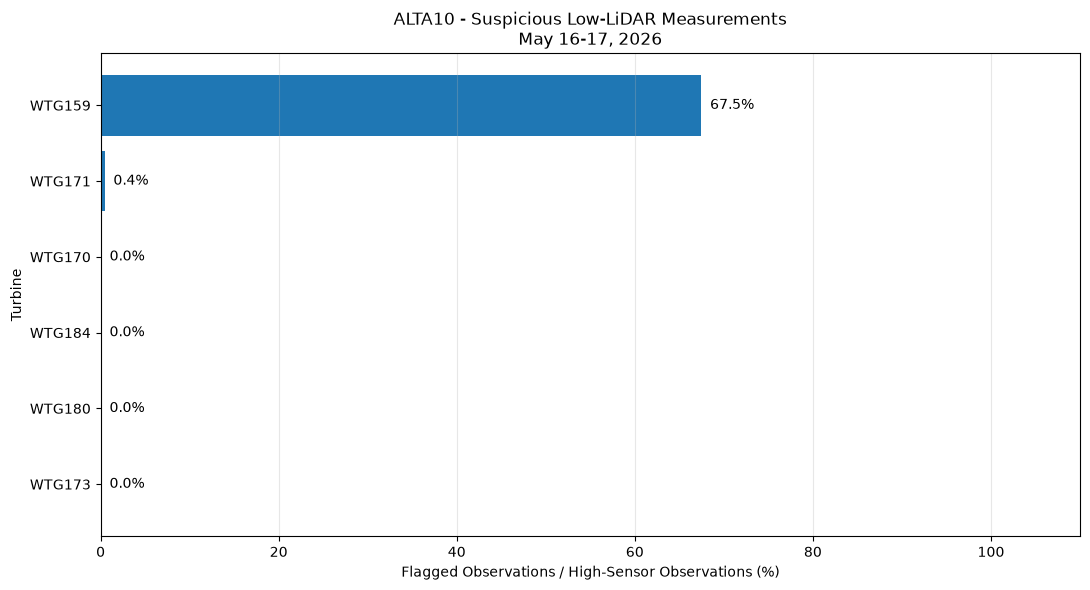

In [46]:
# =================================================
# ALTA10 - MULTI-TURBINE LIDAR STATE INVESTIGATION
# MAY 16-17, 2026
# =================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

lidar_path = project_path / "data/raw/lidar_data"

turbines = [
    "159", "170", "171",
    "173", "180", "184"
]

# Same event window used for WTG159
start = pd.Timestamp("2026-05-16 21:00")
end = pd.Timestamp("2026-05-17 08:00")

summary_results = []
mode_results = []

for turbine in turbines:

    folder = lidar_path / f"WTG_T{turbine}"

    files = [
        folder / "2026-05-16.csv",
        folder / "2026-05-17.csv"
    ]

    daily_data = []

    for file in files:

        if not file.exists():
            print(f"Missing file: {file}")
            continue

        df = pd.read_csv(
            file,
            usecols=[
                "timestamp",
                "lidar_wsp",
                "sensor1_wsp",
                "mode"
            ],
            parse_dates=["timestamp"]
        )

        daily_data.append(df)

    if not daily_data:
        continue

    data = pd.concat(
        daily_data,
        ignore_index=True
    )

    # Filter event window
    data = data[
        data["timestamp"].between(start, end)
    ].copy()

    total_records = len(data)

    # Convert measurements
    for col in ["lidar_wsp", "sensor1_wsp", "mode"]:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

    # Keep plausible, paired measurements
    data = data.dropna(
        subset=["lidar_wsp", "sensor1_wsp"]
    )

    data = data[
        data["lidar_wsp"].between(0, 50) &
        data["sensor1_wsp"].between(0, 50)
    ].copy()

    # Same exploratory condition as WTG159
    data["high_sensor"] = (
        data["sensor1_wsp"] > 20
    )

    data["suspicious"] = (
        data["high_sensor"] &
        (data["lidar_wsp"] < 8)
    )

    high_count = int(data["high_sensor"].sum())
    suspicious_count = int(data["suspicious"].sum())

    # Normalize by high-wind observations
    suspicious_pct = (
        100 * suspicious_count / high_count
        if high_count > 0 else np.nan
    )

    summary_results.append({
        "turbine": f"WTG{turbine}",
        "total_records": total_records,
        "paired_records": len(data),
        "high_sensor_records": high_count,
        "suspicious_records": suspicious_count,
        "suspicious_pct_high_wind": suspicious_pct
    })

    # Compare modes within each turbine
    for mode, group in data.groupby("mode"):

        eligible = group["high_sensor"].sum()
        flagged = group["suspicious"].sum()

        mode_results.append({
            "turbine": f"WTG{turbine}",
            "mode": mode,
            "high_sensor_records": eligible,
            "suspicious_records": flagged,
            "suspicious_pct_high_wind":
                100 * flagged / eligible
                if eligible > 0 else np.nan
        })

# ===============================================
# CREATE SUMMARY TABLES
# ===============================================

lidar_state_summary = pd.DataFrame(
    summary_results
)

lidar_mode_summary = pd.DataFrame(
    mode_results
)

print("ALTA10 - LIDAR STATE COMPARISON")
display(
    lidar_state_summary.round(2)
)

print("\nSTATE COMPARISON BY MEASUREMENT MODE")
display(
    lidar_mode_summary.round(2)
)

# ===============================================
# VISUALIZE THE RESULTS
# ===============================================

plot_data = lidar_state_summary.sort_values(
    "suspicious_pct_high_wind"
)

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    plot_data["turbine"],
    plot_data["suspicious_pct_high_wind"]
)

for bar, value in zip(
    bars,
    plot_data["suspicious_pct_high_wind"]
):
    if pd.notna(value):
        ax.text(
            value + 1,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center"
        )

ax.set_xlim(0, 110)

ax.set_xlabel(
    "Flagged Observations / High-Sensor Observations (%)"
)

ax.set_ylabel("Turbine")

ax.set_title(
    "ALTA10 - Suspicious Low-LiDAR Measurements\n"
    "May 16-17, 2026"
)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

WTG159 - DAILY LIDAR QUALITY SUMMARY
Days analyzed: 134
Total flagged seconds: 51794

TOP 15 DAYS BY FLAGGED PERCENTAGE:


C:\Users\alex-\AppData\Local\Temp\ipykernel_16024\2013976167.py:82: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(2)


,date,paired_records,high_wind_records,flagged_records,flagged_pct
38,2026-06-08,80782,25776,24273,94.17
30,2026-05-31,31587,1536,1380,89.84
16,2026-05-17,83541,52374,15750,30.07
15,2026-05-16,49178,44643,7959,17.83
57,2026-06-27,82838,14418,588,4.08
37,2026-06-07,85388,15213,289,1.90
39,2026-06-09,83036,34226,501,1.46
13,2026-05-14,80748,25803,159,0.62
59,2026-06-29,71372,13863,83,0.60
14,2026-05-15,78452,33142,164,0.49



MONTHLY ANOMALY SUMMARY:


,high_wind_records,flagged_records,flagged_pct
month,,,
2026-05,256601,25500,9.94
2026-06,205655,26277,12.78
2026-07,55844,4,0.01
2026-08,5262,11,0.21
2026-09,46315,2,0.00


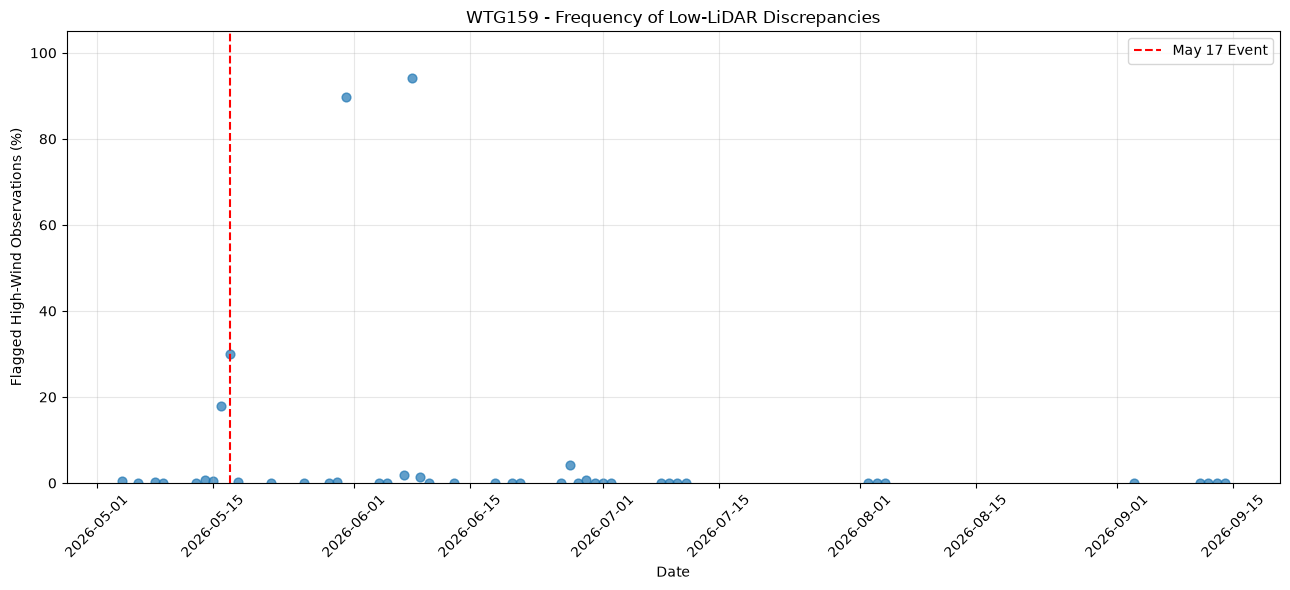

In [47]:
# ==============================================
# WTG159 - LIDAR ANOMALY FREQUENCY
# FULL AVAILABLE DATASET
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = (
    project_path / "data" / "raw"
    / "lidar_data" / "WTG_T159"
)

results = []

for file in sorted(folder.glob("*.csv")):

    df = pd.read_csv(
        file,
        usecols=["lidar_wsp", "sensor1_wsp"]
    )

    lidar = pd.to_numeric(
        df["lidar_wsp"], errors="coerce"
    )

    sensor = pd.to_numeric(
        df["sensor1_wsp"], errors="coerce"
    )

    # Require paired, plausible readings
    valid = (
        lidar.between(0, 50) &
        sensor.between(0, 50)
    )

    # High-wind condition
    high_wind = valid & (sensor > 20)

    # Exploratory low-LiDAR discrepancy
    flagged = high_wind & (lidar < 8)

    n_high = int(high_wind.sum())
    n_flagged = int(flagged.sum())

    results.append({
        "date": pd.to_datetime(file.stem),
        "paired_records": int(valid.sum()),
        "high_wind_records": n_high,
        "flagged_records": n_flagged,
        "flagged_pct": (
            100 * n_flagged / n_high
            if n_high > 0 else np.nan
        )
    })

daily_qc = pd.DataFrame(results).sort_values("date")

# ==============================================
# DAILY SUMMARY
# ==============================================

print("WTG159 - DAILY LIDAR QUALITY SUMMARY")

print("Days analyzed:", len(daily_qc))

print("Total flagged seconds:",
      daily_qc["flagged_records"].sum())

# Require at least 10 minutes of high-wind data
eligible_days = daily_qc[
    daily_qc["high_wind_records"] >= 600
].copy()

print("\nTOP 15 DAYS BY FLAGGED PERCENTAGE:")

display(
    eligible_days.nlargest(
        15, "flagged_pct"
    ).round(2)
)

# ==============================================
# MONTHLY SUMMARY
# ==============================================

daily_qc["month"] = (
    daily_qc["date"].dt.to_period("M")
)

monthly_qc = (
    daily_qc.groupby("month")
    .agg(
        high_wind_records=("high_wind_records", "sum"),
        flagged_records=("flagged_records", "sum")
    )
)

monthly_qc["flagged_pct"] = (
    100 * monthly_qc["flagged_records"] /
    monthly_qc["high_wind_records"].replace(0, np.nan)
)

print("\nMONTHLY ANOMALY SUMMARY:")
display(monthly_qc.round(2))

# ==============================================
# VISUALIZE DAILY ANOMALY FREQUENCY
# ==============================================

fig, ax = plt.subplots(figsize=(13, 6))

ax.scatter(
    eligible_days["date"],
    eligible_days["flagged_pct"],
    s=40,
    alpha=0.7
)

ax.axvline(
    pd.Timestamp("2026-05-17"),
    color="red",
    linestyle="--",
    label="May 17 Event"
)

ax.set_title(
    "WTG159 - Frequency of Low-LiDAR Discrepancies"
)

ax.set_xlabel("Date")
ax.set_ylabel(
    "Flagged High-Wind Observations (%)"
)

ax.set_ylim(0, 105)
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

JUNE 8 - SIX TURBINE COMPARISON


,turbine,paired_seconds,high_wind_seconds,flagged_seconds,flagged_pct
0,WTG159,80782,25776,24273,94.17
1,WTG170,75013,560,2,0.36
2,WTG171,45041,3038,0,0.00
3,WTG173,83922,1244,0,0.00
4,WTG180,82391,18705,4,0.02
5,WTG184,84214,2402,0,0.00


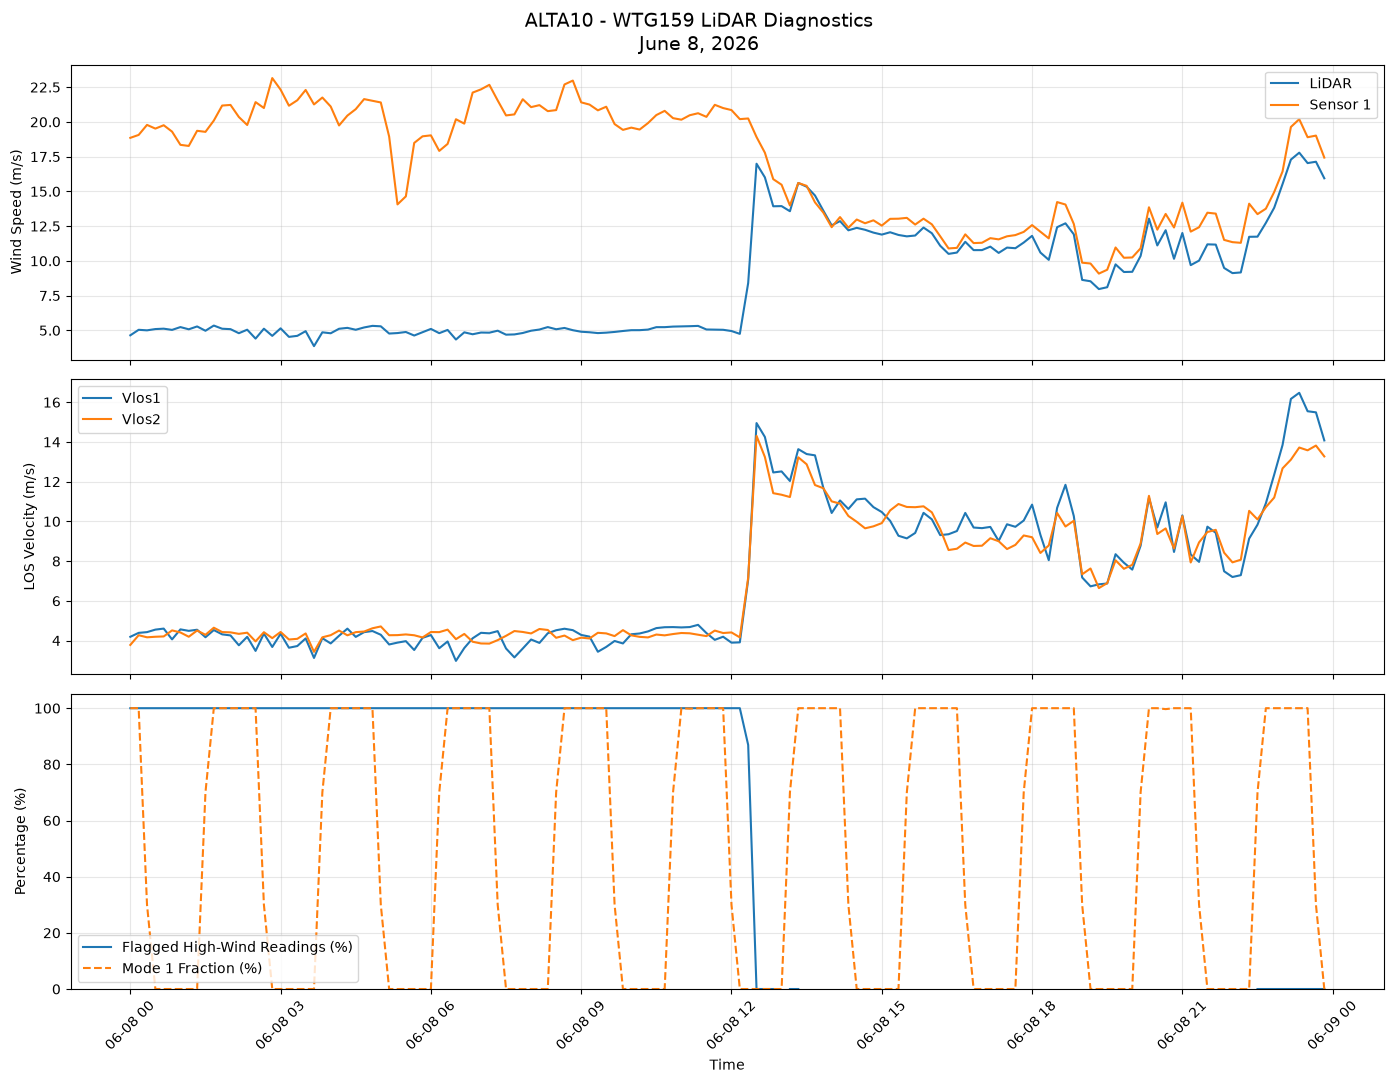

In [49]:
# ===================================================
# ALTA10 - JUNE 8 LIDAR EVENT INVESTIGATION
# ===================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

lidar_path = project_path / "data/raw/lidar_data"

turbines = ["159", "170", "171", "173", "180", "184"]
event_date = "2026-06-08"

results = []

# ==========================================
# 1. COMPARE ALL SIX LIDAR TURBINES
# ==========================================

for turbine in turbines:

    file = lidar_path / f"WTG_T{turbine}" / f"{event_date}.csv"

    if not file.exists():
        print(f"Missing: {file}")
        continue

    df = pd.read_csv(
        file,
        usecols=["lidar_wsp", "sensor1_wsp"]
    )

    valid = (
        df["lidar_wsp"].between(0, 50) &
        df["sensor1_wsp"].between(0, 50)
    )

    high_wind = valid & (df["sensor1_wsp"] > 20)

    flagged = high_wind & (df["lidar_wsp"] < 8)

    n_high = int(high_wind.sum())

    results.append({
        "turbine": f"WTG{turbine}",
        "paired_seconds": int(valid.sum()),
        "high_wind_seconds": n_high,
        "flagged_seconds": int(flagged.sum()),
        "flagged_pct": (
            flagged.sum() / n_high * 100
            if n_high > 0 else np.nan
        )
    })

june8_summary = pd.DataFrame(results)

print("JUNE 8 - SIX TURBINE COMPARISON")
display(june8_summary.round(2))

# ==========================================
# 2. LOAD WTG159 RAW BEAM DATA
# ==========================================

file159 = lidar_path / "WTG_T159" / f"{event_date}.csv"

raw159 = pd.read_csv(
    file159,
    parse_dates=["timestamp"]
)

raw159 = raw159.sort_values("timestamp")

valid = (
    raw159["lidar_wsp"].between(0, 50) &
    raw159["sensor1_wsp"].between(0, 50)
)

raw159["high_wind"] = (
    valid & (raw159["sensor1_wsp"] > 20)
).astype(int)

raw159["flagged"] = (
    valid &
    (raw159["sensor1_wsp"] > 20) &
    (raw159["lidar_wsp"] < 8)
).astype(int)

raw159["mode1"] = raw159["mode"].eq(1).astype(int)

# ==========================================
# 3. AGGREGATE INTO 10-MINUTE INTERVALS
# ==========================================

june8_10min = (
    raw159.set_index("timestamp")
    .resample("10min")
    .agg(
        lidar=("lidar_wsp", "mean"),
        sensor=("sensor1_wsp", "mean"),
        vlos1=("Vlos1", "mean"),
        vlos2=("Vlos2", "mean"),
        high_wind_count=("high_wind", "sum"),
        flagged_count=("flagged", "sum"),
        mode1_fraction=("mode1", "mean")
    )
)

june8_10min["flagged_pct"] = (
    100 * june8_10min["flagged_count"] /
    june8_10min["high_wind_count"].replace(0, np.nan)
)

# ==========================================
# 4. DIAGNOSTIC VISUALIZATION
# ==========================================

fig, axes = plt.subplots(
    3, 1, figsize=(14, 11), sharex=True
)

# Wind speed
axes[0].plot(
    june8_10min.index,
    june8_10min["lidar"],
    label="LiDAR"
)

axes[0].plot(
    june8_10min.index,
    june8_10min["sensor"],
    label="Sensor 1"
)

axes[0].set_ylabel("Wind Speed (m/s)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Beam velocities
axes[1].plot(
    june8_10min.index,
    june8_10min["vlos1"],
    label="Vlos1"
)

axes[1].plot(
    june8_10min.index,
    june8_10min["vlos2"],
    label="Vlos2"
)

axes[1].set_ylabel("LOS Velocity (m/s)")
axes[1].legend()
axes[1].grid(alpha=0.3)

# Flagged observations and mode
axes[2].plot(
    june8_10min.index,
    june8_10min["flagged_pct"],
    label="Flagged High-Wind Readings (%)"
)

axes[2].plot(
    june8_10min.index,
    june8_10min["mode1_fraction"] * 100,
    linestyle="--",
    label="Mode 1 Fraction (%)"
)

axes[2].set_ylabel("Percentage (%)")
axes[2].set_xlabel("Time")
axes[2].set_ylim(0, 105)
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.suptitle(
    "ALTA10 - WTG159 LiDAR Diagnostics\n"
    "June 8, 2026",
    fontsize=14
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [50]:
# ==================================================
# ALTA10 - WTG159 LIDAR QUALITY SENSITIVITY ANALYSIS
# ==================================================

import pandas as pd
import numpy as np
from pathlib import Path

folder = (
    project_path / "data" / "raw" /
    "lidar_data" / "WTG_T159"
)

qc_intervals = []

# ==========================================
# 1. IDENTIFY SUSPICIOUS 10-MINUTE INTERVALS
# ==========================================

for file in sorted(folder.glob("*.csv")):

    df = pd.read_csv(
        file,
        usecols=[
            "timestamp",
            "lidar_wsp",
            "sensor1_wsp"
        ]
    )

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], errors="coerce"
    )

    df = df.dropna(subset=["timestamp"])

    lidar_speed = pd.to_numeric(
        df["lidar_wsp"], errors="coerce"
    )

    sensor_speed = pd.to_numeric(
        df["sensor1_wsp"], errors="coerce"
    )

    valid = (
        lidar_speed.between(0, 50) &
        sensor_speed.between(0, 50)
    )

    # Same exploratory anomaly definition
    high_wind = valid & (sensor_speed > 20)

    suspicious = high_wind & (lidar_speed < 8)

    df["high_wind"] = high_wind.astype(int)
    df["suspicious"] = suspicious.astype(int)

    interval = (
        df.set_index("timestamp")
        .resample("10min")
        .agg(
            high_wind_count=("high_wind", "sum"),
            suspicious_count=("suspicious", "sum")
        )
        .reset_index()
    )

    qc_intervals.append(interval)

qc_10min = pd.concat(
    qc_intervals, ignore_index=True
)

# Calculate fraction of high-wind observations flagged
qc_10min["suspicious_fraction"] = (
    qc_10min["suspicious_count"] /
    qc_10min["high_wind_count"].replace(0, np.nan)
)

# Flag intervals with at least 120 eligible seconds
# AND at least 50% suspicious measurements
qc_10min["flagged_interval"] = (
    (qc_10min["high_wind_count"] >= 120) &
    (qc_10min["suspicious_fraction"] >= 0.50)
)

# ==========================================
# 2. MERGE FLAGS WITH PREVIOUS TI CALCULATIONS
# ==========================================

wtg159_ti = lidar_ti_all[
    (lidar_ti_all["turbine"] == "WTG159") &
    (lidar_ti_all["valid_interval"])
].copy()

wtg159_ti["timestamp"] = pd.to_datetime(
    wtg159_ti["timestamp"]
)

wtg159_ti = wtg159_ti.merge(
    qc_10min[
        ["timestamp", "flagged_interval"]
    ],
    on="timestamp",
    how="left",
    validate="one_to_one"
)

wtg159_ti["flagged_interval"] = (
    wtg159_ti["flagged_interval"]
    .fillna(False)
    .astype(bool)
)

# Preserve original data
original = wtg159_ti.copy()

# Sensitivity scenario: exclude flagged intervals
screened = wtg159_ti[
    ~wtg159_ti["flagged_interval"]
].copy()

# ==========================================
# 3. COMPARE BEFORE AND AFTER
# ==========================================

results = []

for label, data in [
    ("Original", original),
    ("Sensitivity-screened", screened)
]:

    results.append({
        "dataset": label,
        "valid_intervals": len(data),
        "mean_TI_pct": data["TI"].mean() * 100,
        "median_TI_pct": data["TI"].median() * 100,
        "mean_k_proxy": data["estimated_k"].mean(),
        "median_k_proxy": data["estimated_k"].median()
    })

qc_comparison = pd.DataFrame(results)

print("WTG159 - TURBULENCE SENSITIVITY ANALYSIS")
display(qc_comparison.round(4))

print(
    "\nExcluded intervals:",
    len(original) - len(screened)
)

# Show dates with most flagged intervals
flagged_dates = (
    original.loc[original["flagged_interval"]]
    .assign(date=lambda x: x["timestamp"].dt.date)
    .groupby("date")
    .size()
    .sort_values(ascending=False)
)

print("\nDATES WITH MOST FLAGGED INTERVALS:")
display(flagged_dates.head(10))

WTG159 - TURBULENCE SENSITIVITY ANALYSIS


,dataset,valid_intervals,mean_TI_pct,median_TI_pct,mean_k_proxy,median_k_proxy
0,Original,15165,11.3871,10.0075,0.0569,0.05
1,Sensitivity-screened,15075,11.3763,10.0075,0.0569,0.05



Excluded intervals: 90

DATES WITH MOST FLAGGED INTERVALS:


date
2026-06-08    52
2026-05-17    26
2026-05-16    10
2026-05-31     2
dtype: int64

In [51]:
# ==============================================
# WTG159 - EFFECT OF QUALITY SCREEN ON WIND BIAS
# ==============================================

import pandas as pd
import numpy as np

# Existing matched SCADA-LiDAR dataset
pairs = all_matched[
    all_matched["turbine"] == "WTG159"
].copy()

pairs["timestamp"] = pd.to_datetime(pairs["timestamp"])

# Previously calculated LiDAR quality flags
flags = qc_10min[
    ["timestamp", "flagged_interval"]
].copy()

flags["timestamp"] = pd.to_datetime(flags["timestamp"])

# Join quality flags
pairs = pairs.merge(
    flags,
    on="timestamp",
    how="left",
    validate="one_to_one"
)

pairs["flagged_interval"] = (
    pairs["flagged_interval"].eq(True)
)

pairs["difference"] = (
    pairs["scada_speed"] - pairs["lidar_speed"]
)

# Compare original and screened statistics
results = []

for label, subset in [
    ("Original", pairs),
    ("Sensitivity-screened",
     pairs[~pairs["flagged_interval"]])
]:

    d = subset["difference"].dropna()

    results.append({
        "dataset": label,
        "observations": len(d),
        "mean_difference": d.mean(),
        "median_difference": d.median(),
        "RMSE": np.sqrt(np.mean(d**2))
    })

bias_qc_summary = pd.DataFrame(results)

print("WTG159 - QUALITY SCREENING EFFECT ON WIND SPEED")
display(bias_qc_summary.round(4))

WTG159 - QUALITY SCREENING EFFECT ON WIND SPEED


,dataset,observations,mean_difference,median_difference,RMSE
0,Original,15018,1.7099,1.3102,2.8113
1,Sensitivity-screened,14934,1.5959,1.3063,2.2636


In [53]:
# ==========================================
# ALTA10 - LOAD GE TURBINE POWER CURVE
# ==========================================

import pandas as pd
from pathlib import Path

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

# Find the power curve dataset
files = [
    f for f in project_path.rglob("GE_2_85MW_103mRD_PC.*")
    if f.suffix.lower() in [".xlsx", ".xls", ".csv"]
    and not f.name.startswith("~$")
]

if not files:
    raise FileNotFoundError(
        "Power curve file not found in project directory."
    )

power_curve_file = files[0]

print("File found:", power_curve_file)

# Load according to file type
if power_curve_file.suffix.lower() == ".csv":
    power_curve = pd.read_csv(power_curve_file)
else:
    power_curve = pd.read_excel(power_curve_file)

# Clean column names
power_curve.columns = power_curve.columns.str.strip()

print("\nPower curve shape:", power_curve.shape)

print("\nVariables:")
print(power_curve.columns.tolist())

print("\nFirst 10 rows:")
display(power_curve.head(10))

File found: C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\GE_2_85MW_103mRD_PC.csv

Power curve shape: (495, 6)

Variables:
['TURBINE_MODEL', 'RATED_POWER_KW', 'AIR_DENSITY', 'TI_CLASS', 'WINDSPEED', 'POWER_KW']

First 10 rows:


,TURBINE_MODEL,RATED_POWER_KW,AIR_DENSITY,TI_CLASS,WINDSPEED,POWER_KW
0,GE_2_85MW_103mRD,2850,1.02,normal,3.0,1
1,GE_2_85MW_103mRD,2850,1.02,normal,3.5,7
2,GE_2_85MW_103mRD,2850,1.02,normal,4.0,63
3,GE_2_85MW_103mRD,2850,1.02,normal,4.5,130
4,GE_2_85MW_103mRD,2850,1.02,normal,5.0,210
5,GE_2_85MW_103mRD,2850,1.02,normal,5.5,300
6,GE_2_85MW_103mRD,2850,1.02,normal,6.0,405
7,GE_2_85MW_103mRD,2850,1.02,normal,6.5,527
8,GE_2_85MW_103mRD,2850,1.02,normal,7.0,678
9,GE_2_85MW_103mRD,2850,1.02,normal,7.5,838


In [54]:
# ==========================================
# ALTA10 - LOCATE GE POWER CURVE DATA
# ==========================================

from pathlib import Path
import pandas as pd

project_path = Path(
    r"C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project"
)

power_curve_files = []

for file in project_path.rglob("*.csv"):

    # Skip large LiDAR daily datasets
    if "lidar_data" in file.parts:
        continue

    try:
        columns = pd.read_csv(
            file, nrows=0
        ).columns.str.strip().str.upper()

        if {"WINDSPEED", "POWER_KW"}.issubset(set(columns)):
            power_curve_files.append(file)

    except Exception:
        continue

print("POWER CURVE FILES FOUND:")

for file in power_curve_files:
    print(file)

if power_curve_files:
    # Preview the first matching power curve
    power_curve = pd.read_csv(power_curve_files[0])

    print("\nPOWER CURVE VARIABLES:")
    print(power_curve.columns.tolist())

    display(power_curve.head(10))
else:
    print("No matching CSV found inside the project folder.")

POWER CURVE FILES FOUND:
C:\Users\alex-\OneDrive\Documents\GitHub\CU-Capstone-Project\data\raw\GE_2_85MW_103mRD_PC.csv

POWER CURVE VARIABLES:
['TURBINE_MODEL', 'RATED_POWER_KW', 'AIR_DENSITY', 'TI_CLASS', 'WINDSPEED', 'POWER_KW']


,TURBINE_MODEL,RATED_POWER_KW,AIR_DENSITY,TI_CLASS,WINDSPEED,POWER_KW
0,GE_2_85MW_103mRD,2850,1.02,normal,3.0,1
1,GE_2_85MW_103mRD,2850,1.02,normal,3.5,7
2,GE_2_85MW_103mRD,2850,1.02,normal,4.0,63
3,GE_2_85MW_103mRD,2850,1.02,normal,4.5,130
4,GE_2_85MW_103mRD,2850,1.02,normal,5.0,210
5,GE_2_85MW_103mRD,2850,1.02,normal,5.5,300
6,GE_2_85MW_103mRD,2850,1.02,normal,6.0,405
7,GE_2_85MW_103mRD,2850,1.02,normal,6.5,527
8,GE_2_85MW_103mRD,2850,1.02,normal,7.0,678
9,GE_2_85MW_103mRD,2850,1.02,normal,7.5,838


Initial matched intervals: 15018
Intervals after filtering: 6138

WTG159 - POWER CURVE VALIDATION


,wind_source,observations,mean_error_kw,MAE_kw,RMSE_kw
0,LiDAR,6138,-204.255,207.618,230.673
1,SCADA,6138,161.600,176.571,213.788


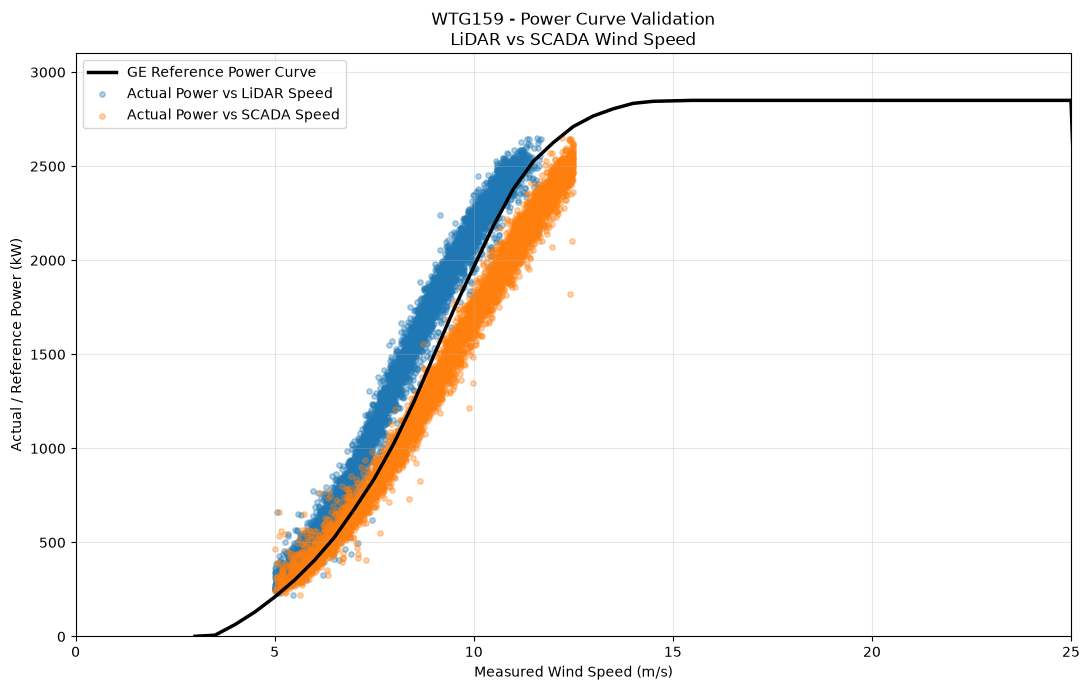

In [55]:
# ==============================================
# ALTA10 - WTG159 POWER CURVE VALIDATION
# LiDAR vs SCADA Wind Speed
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================================
# 1. PREPARE REFERENCE POWER CURVE
# ==============================================

curve = power_curve.copy()

curve.columns = curve.columns.str.strip()

for col in ["WINDSPEED", "POWER_KW", "AIR_DENSITY"]:
    curve[col] = pd.to_numeric(curve[col], errors="coerce")

# Use the reference curve at 1.02 kg/m³
curve = curve[
    np.isclose(curve["AIR_DENSITY"], 1.02, atol=0.001) &
    (curve["TI_CLASS"].astype(str).str.lower() == "normal")
].copy()

curve = (
    curve.groupby("WINDSPEED", as_index=False)["POWER_KW"]
    .mean()
    .sort_values("WINDSPEED")
)

if len(curve) < 2:
    raise ValueError("Not enough reference power curve points.")

# ==============================================
# 2. PREPARE WTG159 MATCHED DATA
# ==============================================

validation = all_matched[
    all_matched["turbine"] == "WTG159"
].copy()

validation["timestamp"] = pd.to_datetime(
    validation["timestamp"]
)

# Retrieve air density from SCADA
density = scada[
    scada["turbine"].astype(str).str.strip() == "WTG159"
][["utc", "air_density"]].copy()

density["timestamp"] = pd.to_datetime(
    density["utc"], errors="coerce", utc=True
).dt.tz_localize(None)

density["air_density"] = pd.to_numeric(
    density["air_density"], errors="coerce"
)

density = density.drop(columns="utc")

validation = validation.merge(
    density,
    on="timestamp",
    how="left",
    validate="many_to_one"
)

print("Initial matched intervals:", len(validation))

# ==============================================
# 3. APPLY EXPLORATORY OPERATING FILTERS
# ==============================================

# Focus below rated wind speed, where power
# changes substantially with wind speed
min_wind = 5.0
max_wind = 12.5

# Keep density near reference condition
density_tolerance = 0.03

validation = validation[
    validation["lidar_speed"].between(min_wind, max_wind) &
    validation["scada_speed"].between(min_wind, max_wind) &
    validation["power_kw"].between(100, 2850) &
    validation["air_density"].between(
        1.02 - density_tolerance,
        1.02 + density_tolerance
    )
].copy()

print("Intervals after filtering:", len(validation))

if validation.empty:
    raise ValueError(
        "No observations pass the filters. "
        "Inspect the wind and density ranges."
    )

# ==============================================
# 4. INTERPOLATE EXPECTED POWER
# ==============================================

wind_points = curve["WINDSPEED"].to_numpy()
power_points = curve["POWER_KW"].to_numpy()

validation["predicted_power_lidar"] = np.interp(
    validation["lidar_speed"],
    wind_points,
    power_points,
    left=np.nan,
    right=np.nan
)

validation["predicted_power_scada"] = np.interp(
    validation["scada_speed"],
    wind_points,
    power_points,
    left=np.nan,
    right=np.nan
)

validation = validation.dropna(
    subset=[
        "predicted_power_lidar",
        "predicted_power_scada",
        "power_kw"
    ]
)

# ==============================================
# 5. CALCULATE PREDICTION ERRORS
# ==============================================

results = []

for name, col in [
    ("LiDAR", "predicted_power_lidar"),
    ("SCADA", "predicted_power_scada")
]:

    error = validation[col] - validation["power_kw"]

    results.append({
        "wind_source": name,
        "observations": len(error),
        "mean_error_kw": error.mean(),
        "MAE_kw": error.abs().mean(),
        "RMSE_kw": np.sqrt(np.mean(error**2))
    })

power_results = pd.DataFrame(results)

print("\nWTG159 - POWER CURVE VALIDATION")
display(power_results.round(3))

# ==============================================
# 6. PLOT ACTUAL POWER AGAINST REFERENCE CURVE
# ==============================================

fig, ax = plt.subplots(figsize=(11, 7))

# Manufacturer/reference curve
ax.plot(
    curve["WINDSPEED"],
    curve["POWER_KW"],
    color="black",
    linewidth=2.5,
    label="GE Reference Power Curve"
)

# Actual production positioned by LiDAR wind speed
ax.scatter(
    validation["lidar_speed"],
    validation["power_kw"],
    alpha=0.35,
    s=15,
    label="Actual Power vs LiDAR Speed"
)

# Actual production positioned by SCADA wind speed
ax.scatter(
    validation["scada_speed"],
    validation["power_kw"],
    alpha=0.35,
    s=15,
    label="Actual Power vs SCADA Speed"
)

ax.set_xlabel("Measured Wind Speed (m/s)")
ax.set_ylabel("Actual / Reference Power (kW)")

ax.set_title(
    "WTG159 - Power Curve Validation\n"
    "LiDAR vs SCADA Wind Speed"
)

ax.set_xlim(0, 25)
ax.set_ylim(0, 3100)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

ALTA10 - SIX TURBINE POWER VALIDATION


,turbine,source,observations,mean_error_kw,MAE_kw,RMSE_kw
0,WTG159,LiDAR,6138,-204.26,207.62,230.67
1,WTG159,SCADA,6138,161.60,176.57,213.79
2,WTG170,LiDAR,8223,-150.72,191.63,223.63
3,WTG170,SCADA,8223,7.42,80.12,109.67
4,WTG171,LiDAR,9420,-132.09,197.09,238.04
5,WTG171,SCADA,9420,64.44,134.63,183.41
6,WTG173,LiDAR,9978,-53.75,145.33,182.50
7,WTG173,SCADA,9978,-1.20,104.68,136.35
8,WTG180,LiDAR,6496,-69.82,118.00,145.77
9,WTG180,SCADA,6496,-0.12,109.29,135.04


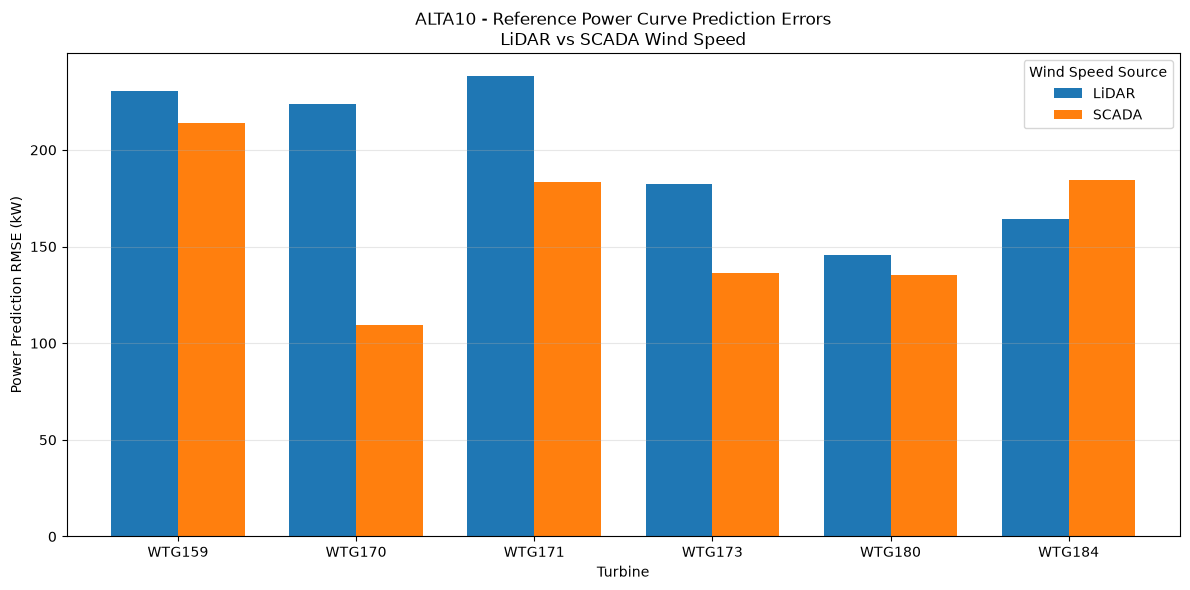

In [56]:
# ==============================================
# ALTA10 - SIX TURBINE POWER CURVE VALIDATION
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

# ----------------------------------------------
# 1. PREPARE REFERENCE POWER CURVE
# ----------------------------------------------

curve_all = power_curve.copy()

curve_all.columns = curve_all.columns.str.strip()

for col in ["WINDSPEED", "POWER_KW", "AIR_DENSITY"]:
    curve_all[col] = pd.to_numeric(
        curve_all[col], errors="coerce"
    )

curve_all = curve_all[
    np.isclose(
        curve_all["AIR_DENSITY"], 1.02, atol=0.001
    ) &
    curve_all["TI_CLASS"].astype(str)
    .str.strip().str.lower().eq("normal")
].copy()

curve_all = (
    curve_all.groupby("WINDSPEED", as_index=False)
    ["POWER_KW"].mean()
    .sort_values("WINDSPEED")
)

wind_points = curve_all["WINDSPEED"].to_numpy()
power_points = curve_all["POWER_KW"].to_numpy()

# ----------------------------------------------
# 2. PREPARE MATCHED LIDAR / SCADA DATA
# ----------------------------------------------

power_data = all_matched[
    all_matched["turbine"].isin(turbines)
].copy()

power_data["timestamp"] = pd.to_datetime(
    power_data["timestamp"]
)

# Retrieve SCADA air density
density_data = scada[
    ["utc", "turbine", "air_density"]
].copy()

density_data["timestamp"] = pd.to_datetime(
    density_data["utc"],
    errors="coerce",
    utc=True
).dt.tz_localize(None)

density_data["turbine"] = (
    density_data["turbine"].astype(str).str.strip()
)

density_data["air_density"] = pd.to_numeric(
    density_data["air_density"],
    errors="coerce"
)

power_data = power_data.merge(
    density_data[
        ["timestamp", "turbine", "air_density"]
    ],
    on=["timestamp", "turbine"],
    how="left",
    validate="one_to_one"
)

# ----------------------------------------------
# 3. APPLY CONSISTENT OPERATING FILTERS
# ----------------------------------------------

power_data = power_data[
    power_data["lidar_speed"].between(5, 12.5) &
    power_data["scada_speed"].between(5, 12.5) &
    power_data["power_kw"].between(100, 2850) &
    power_data["air_density"].between(0.99, 1.05)
].copy()

# ----------------------------------------------
# 4. PREDICT POWER
# ----------------------------------------------

power_data["predicted_lidar"] = np.interp(
    power_data["lidar_speed"],
    wind_points,
    power_points
)

power_data["predicted_scada"] = np.interp(
    power_data["scada_speed"],
    wind_points,
    power_points
)

power_data = power_data.dropna(
    subset=[
        "predicted_lidar",
        "predicted_scada",
        "power_kw"
    ]
)

# ----------------------------------------------
# 5. CALCULATE ERRORS
# ----------------------------------------------

results = []

for turbine, group in power_data.groupby("turbine"):

    for source, column in [
        ("LiDAR", "predicted_lidar"),
        ("SCADA", "predicted_scada")
    ]:

        error = group[column] - group["power_kw"]

        results.append({
            "turbine": turbine,
            "source": source,
            "observations": len(group),
            "mean_error_kw": error.mean(),
            "MAE_kw": error.abs().mean(),
            "RMSE_kw": np.sqrt(np.mean(error**2))
        })

power_comparison = pd.DataFrame(results)

print("ALTA10 - SIX TURBINE POWER VALIDATION")
display(power_comparison.round(2))

# ----------------------------------------------
# 6. COMPARE RMSE GRAPHICALLY
# ----------------------------------------------

rmse_plot = power_comparison.pivot(
    index="turbine",
    columns="source",
    values="RMSE_kw"
).reindex(turbines)

ax = rmse_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title(
    "ALTA10 - Reference Power Curve Prediction Errors\n"
    "LiDAR vs SCADA Wind Speed"
)

ax.set_xlabel("Turbine")
ax.set_ylabel("Power Prediction RMSE (kW)")

ax.legend(title="Wind Speed Source")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

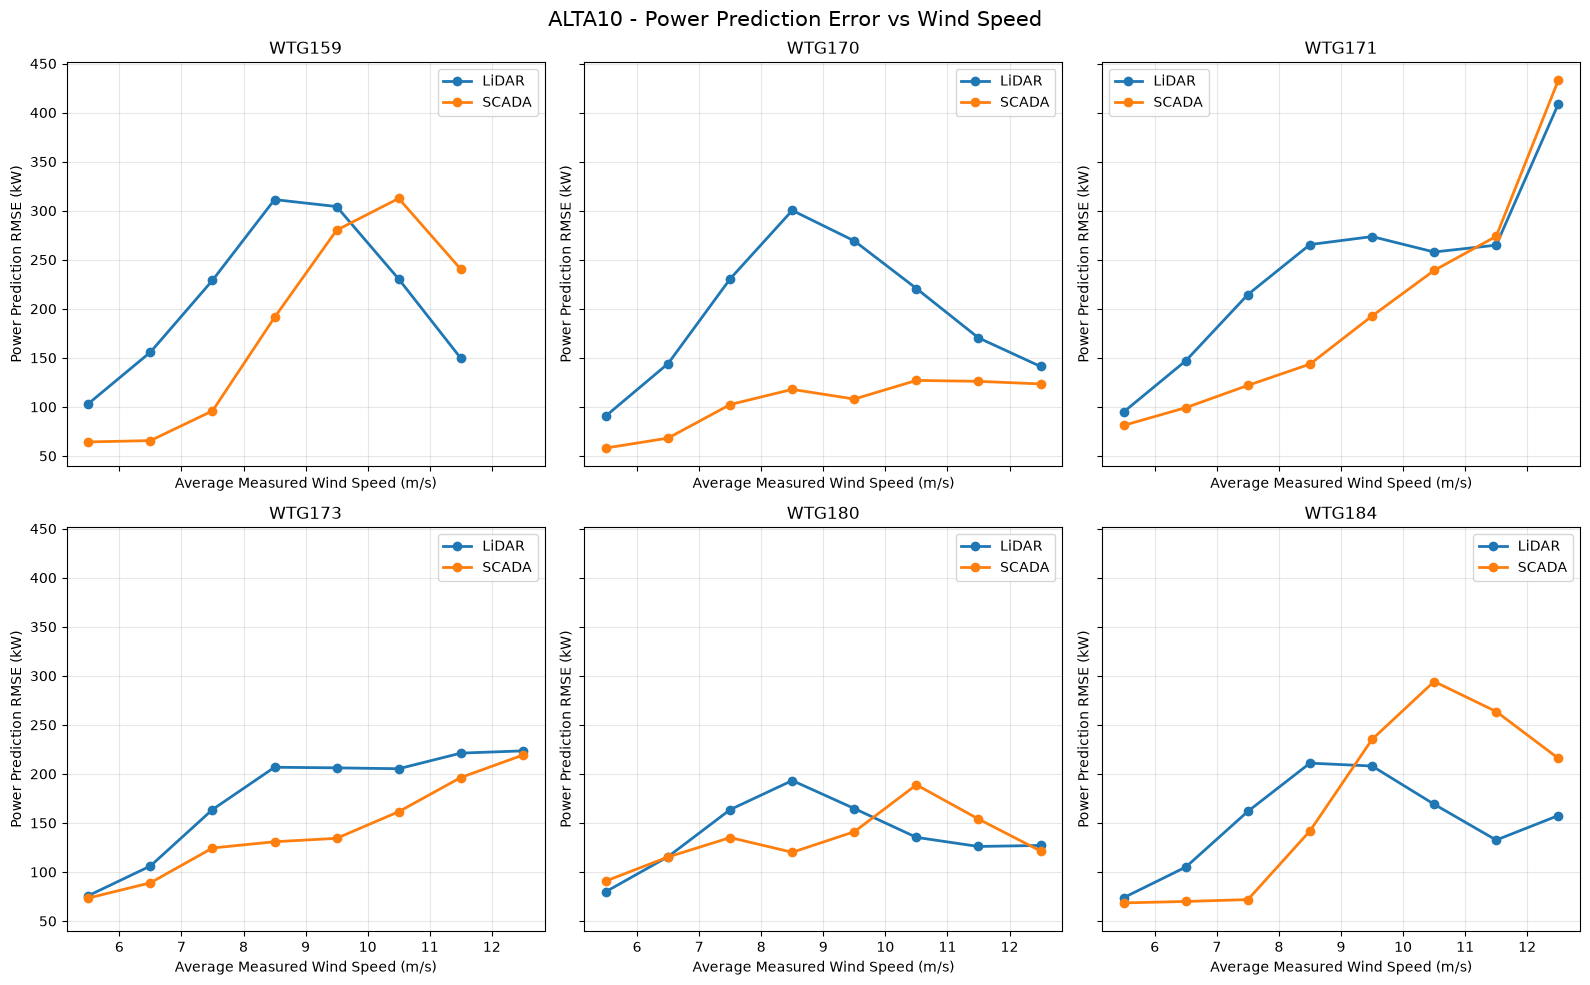

POWER ERROR BY WIND SPEED:


,turbine,speed_bin,source,observations,mean_error,MAE,RMSE
0,WTG159,5.5,LiDAR,585,-91.54,92.73,103.26
1,WTG159,5.5,SCADA,585,-28.79,43.63,64.29
2,WTG159,6.5,LiDAR,856,-143.53,146.43,155.80
3,WTG159,6.5,SCADA,856,5.48,48.85,65.62
4,WTG159,7.5,LiDAR,811,-219.26,220.14,229.04
...,...,...,...,...,...,...,...
89,WTG184,10.5,SCADA,1285,282.10,282.75,294.20
90,WTG184,11.5,LiDAR,803,-16.35,105.13,132.59
91,WTG184,11.5,SCADA,803,248.52,249.02,263.60
92,WTG184,12.5,LiDAR,40,116.38,126.59,157.53


In [57]:
# ==============================================
# ALTA10 - POWER ERROR BY WIND SPEED
# ALL SIX LIDAR TURBINES
# ==============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

analysis = power_data.copy()

# Use average of the two measured speeds
# for exploratory binning without selecting
# one source as the binning reference
analysis["comparison_speed"] = (
    analysis["lidar_speed"] +
    analysis["scada_speed"]
) / 2

# Prediction errors
analysis["lidar_error"] = (
    analysis["predicted_lidar"] - analysis["power_kw"]
)

analysis["scada_error"] = (
    analysis["predicted_scada"] - analysis["power_kw"]
)

# One-meter-per-second wind speed bins
analysis["speed_bin"] = pd.cut(
    analysis["comparison_speed"],
    bins=np.arange(5, 14, 1),
    right=False
)

results = []

for (turbine, speed_bin), group in analysis.groupby(
    ["turbine", "speed_bin"],
    observed=True
):

    if len(group) < 30:
        continue

    for source, col in [
        ("LiDAR", "lidar_error"),
        ("SCADA", "scada_error")
    ]:

        errors = group[col]

        results.append({
            "turbine": turbine,
            "speed_bin": speed_bin.left + 0.5,
            "source": source,
            "observations": len(errors),
            "mean_error": errors.mean(),
            "MAE": errors.abs().mean(),
            "RMSE": np.sqrt(np.mean(errors**2))
        })

speed_error_summary = pd.DataFrame(results)

# ==============================================
# PLOT ALL SIX TURBINES
# ==============================================

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10),
    sharex=True, sharey=True
)

for ax, turbine in zip(axes.flat, turbines):

    subset = speed_error_summary[
        speed_error_summary["turbine"] == turbine
    ]

    for source, group in subset.groupby("source"):

        ax.plot(
            group["speed_bin"],
            group["RMSE"],
            marker="o",
            linewidth=2,
            label=source
        )

    ax.set_title(turbine)
    ax.set_xlabel("Average Measured Wind Speed (m/s)")
    ax.set_ylabel("Power Prediction RMSE (kW)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "ALTA10 - Power Prediction Error vs Wind Speed",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("POWER ERROR BY WIND SPEED:")
display(speed_error_summary.round(2))

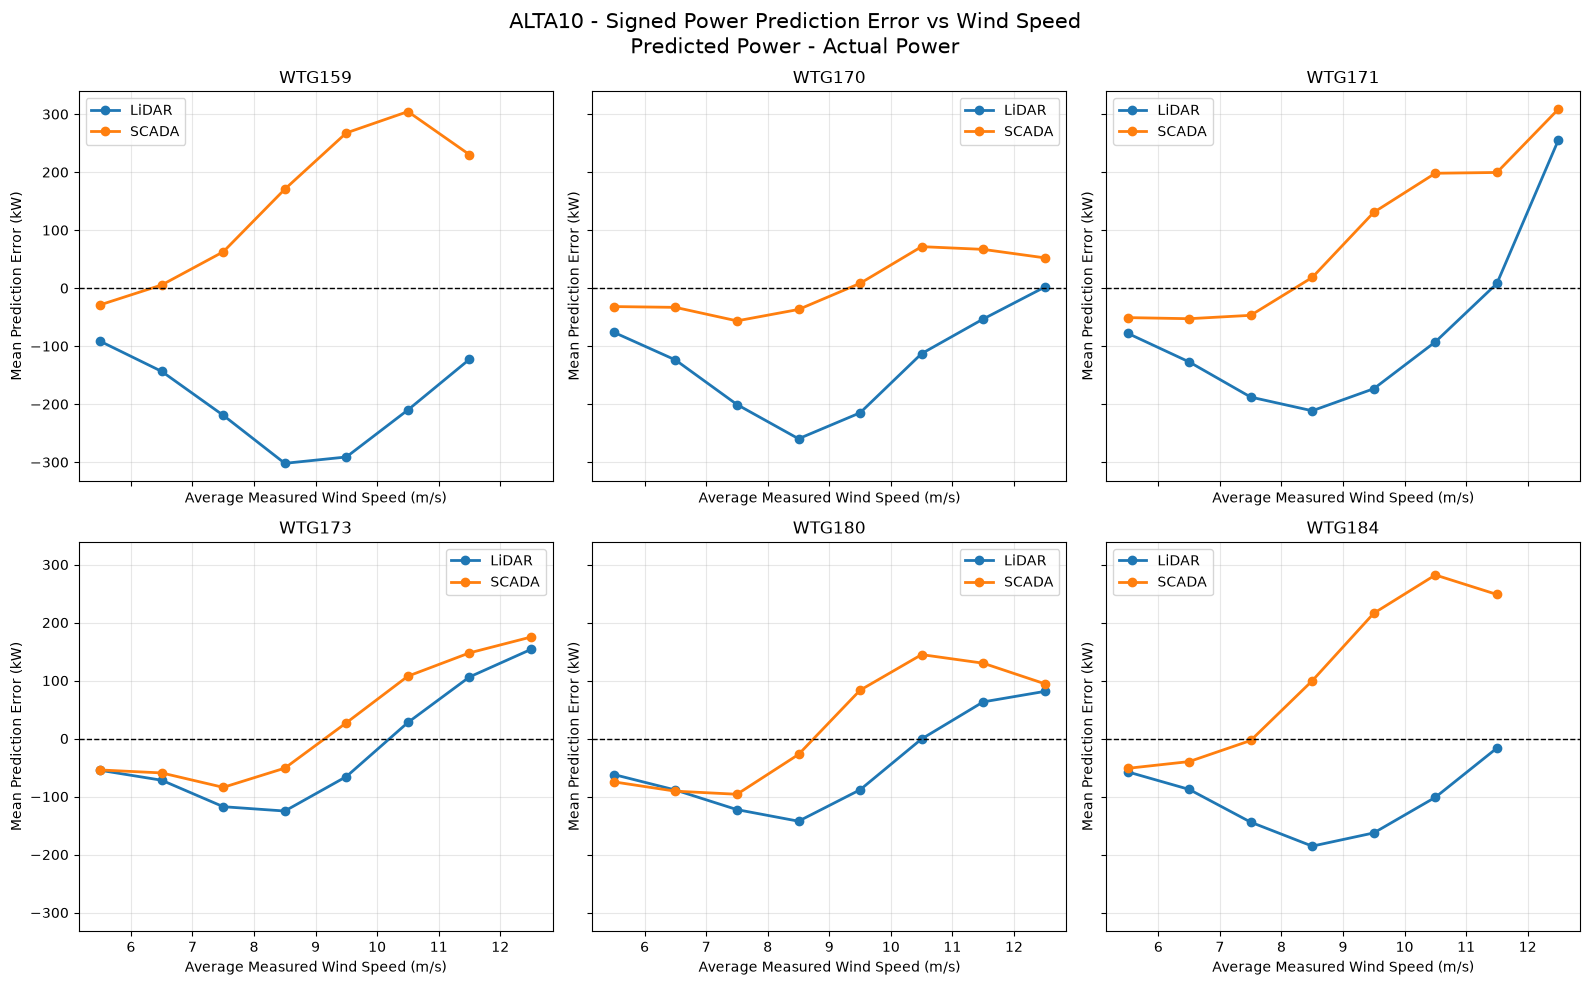

In [58]:
# ==============================================
# ALTA10 - SIGNED POWER ERROR VS WIND SPEED
# SIX LIDAR TURBINES
# ==============================================

import matplotlib.pyplot as plt

turbines = [
    "WTG159", "WTG170", "WTG171",
    "WTG173", "WTG180", "WTG184"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True
)

# Require 100 observations per bin
min_observations = 100

for ax, turbine in zip(axes.flat, turbines):

    subset = speed_error_summary[
        (speed_error_summary["turbine"] == turbine) &
        (speed_error_summary["observations"] >= min_observations)
    ]

    for source in ["LiDAR", "SCADA"]:

        group = subset[
            subset["source"] == source
        ].sort_values("speed_bin")

        ax.plot(
            group["speed_bin"],
            group["mean_error"],
            marker="o",
            linewidth=2,
            label=source
        )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(turbine)
    ax.set_xlabel("Average Measured Wind Speed (m/s)")
    ax.set_ylabel("Mean Prediction Error (kW)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "ALTA10 - Signed Power Prediction Error vs Wind Speed\n"
    "Predicted Power - Actual Power",
    fontsize=15
)

plt.tight_layout()
plt.show()